# Rug Pull Detection on Solana — Data Cleaning, EDA, Chronological Splitting, Missing-Data Preprocessing, Feature Importance, and Artifact Export

## Scope and Experimental Definition

This notebook prepares and audits three early-observation datasets for Solana rug-pull
prediction: q1 = 750 s, q2 = 2127 s, and q3 = 5585 s after token creation. The outcome
horizon is 24 hours.

A binary rug-pull label is used only when `label_status == VALID`. A positive label requires
all three rule components: a liquidity drop greater than 80%, a price drop greater than 90%,
and persistent liquidity depletion for at least 80% of the 30-minute confirmation interval,
with liquidity remaining below the persistence threshold at the endpoint.

`IN_WINDOW_EVENT` and `UNKNOWN_*` outcomes are retained for audit but excluded from binary
supervised modelling. Therefore, class 0 means that the token does not satisfy the
operational rug-pull definition within the 24-hour outcome horizon; it should not be
interpreted as proof that the token is globally benign.

Both label construction and graph extraction are token-mint-level analyses. `lp_address`
is retained as an identifying field, but the historical liquidity series and recovered
transfer activity are collected for the token mint rather than for one specific liquidity
pool. Results should therefore be interpreted as token-level early rug-pull detection,
not pool-specific prediction.

The notebook performs data cleaning, cross-table consistency checks, exploratory analysis,
structural leakage checks, graph diagnostics, chronological splitting, leakage-safe
missing-data preprocessing, training-only model-based feature importance, and final
model-ready artifact export.

All complete-data descriptive EDA is performed before the model-development split is
used. After those analyses and leakage audits are complete, one central chronological
train/validation/test assignment is created at the token-mint level and reused across
q1/q2/q3 and across tabular and graph-based model representations.

The split is label-independent for allocation and targets 70% training, 15% validation,
and 15% test data in chronological order. Because the outcome label uses future
information, samples immediately preceding validation or test are embargoed when their
labels would not yet be available at the beginning of the next partition.

Learned missing-value preprocessing and model-based feature importance are then fitted
using training data only. Validation and test values do not influence fitted imputation
parameters or the feature-importance ranking.

Graph analyses are conditional on recovered transfer activity. Because transfer discovery
is based on the mint-address signature history, the recovered graphs are partial
representations of observable transfer activity even when an edge-collection job completes
successfully.

# Installing and Loading Libraries

In [1]:
%pip install -q pandas numpy matplotlib seaborn networkx pyarrow scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import sys
import json
import joblib
import sklearn
import pyarrow
import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
import networkx as nx
import matplotlib.pyplot as plt      # NOTE: .pyplot — `import matplotlib as plt` has no .subplots()

from matplotlib.colors import LogNorm
from matplotlib.collections import LineCollection

from decimal import Decimal, InvalidOperation

from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier

sns.set_theme(style="whitegrid")
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 150)

# Loading Dataset

In [3]:
PATH = '../dataset/'

NODES_FILE = 'graph_nodes.csv'
EDGES_FILE = 'graph_edges.csv'
LABELS_FILE = 'rule_based_labels.csv'
EDGE_AMOUNTS_FILE = 'edge_amount_normalization.csv'

EXPERIMENTS = ['q1', 'q2', 'q3']

In [4]:
nodes = pd.read_csv(PATH + NODES_FILE)

# IMPORTANT:
# Keep the historical amount exactly as written in graph_edges.csv.
# It is part of the identity key used by the amount resolver.
edges = pd.read_csv(
    PATH + EDGES_FILE,
    dtype={
        'amount': 'string'
    }
)

labels = pd.read_csv(PATH + LABELS_FILE)

# Read the resolver output as strings first.
# Exact raw/token values must not be altered by float parsing.
edge_amounts = pd.read_csv(
    PATH + EDGE_AMOUNTS_FILE,
    dtype='string',
    keep_default_na=False
)

print('nodes       ', nodes.shape)
print('edges       ', edges.shape)
print('labels      ', labels.shape)
print('edge_amounts', edge_amounts.shape)

nodes        (5332, 19)
edges        (2864233, 10)
labels       (8100, 30)
edge_amounts (1914351, 10)


In [5]:
print('\nNODE DTYPES')
display(nodes.dtypes)

print('\nEDGE DTYPES')
display(edges.dtypes)

print('\nLABEL DTYPES')
display(labels.dtypes)


NODE DTYPES


lp_address                       object
token_mint                       object
experiment_id                    object
rug_pull_label                    int64
label_status                     object
creation_time                     int64
observation_window_seconds        int64
observation_start                 int64
observation_end                   int64
label_available_time              int64
volume_sell_change_percent      float64
volume_buy_change_percent       float64
unique_wallet_count             float64
unique_wallet_change_percent    float64
creators                         object
mint_authority                   object
freeze_authority                 object
liquidity_at_creation           float64
liquidity_at_observation_end    float64
dtype: object


EDGE DTYPES


lp_address                   object
token_mint                   object
experiment_id                object
observation_start             int64
observation_end               int64
tx_signature                 object
timestamp                     int64
source_address               object
target_address               object
amount               string[python]
dtype: object


LABEL DTYPES


lp_address                                     object
token_mint                                     object
token_creation_time                             int64
experiment_id                                  object
observation_window_seconds                      int64
observation_end_time                            int64
outcome_end_time                                int64
liquidity_peak_before_drop                    float64
liquidity_at_drop                             float64
liquidity_drop_ratio                          float64
liquidity_drop_flag                            object
liquidity_drop_factor_time                    float64
price_peak_before_drop                        float64
price_peak_time                               float64
price_min_after_drop                          float64
price_min_time                                float64
price_drop_ratio                              float64
price_drop_flag                                object
price_drop_factor_time      

In [6]:
nodes.head()

,lp_address,token_mint,experiment_id,rug_pull_label,label_status,creation_time,observation_window_seconds,observation_start,observation_end,label_available_time,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,creators,mint_authority,freeze_authority,liquidity_at_creation,liquidity_at_observation_end
0,CNSj2UWgELew8R6gsssotqRuJj6NGwVNQDvbosaVcW9n,1254YT9pX4kaczmZi22TF83aAPQ24vyDdoybqPU4pump,q1,0,VALID,1719709095,750,1719709095,1719709845,1719795495,109.771595,64.158611,536.0,68.442623,"[""J3n6nrFTFZcmnmuoHyZ4oAAQjeMwCJsAZFD7syKbm2yZ""]",TSLvdd1pWpHVjahSpsvCXUbgwsL3JAcvokwaKt1eokM,NaN,NaN,39270.423765
1,CNSj2UWgELew8R6gsssotqRuJj6NGwVNQDvbosaVcW9n,1254YT9pX4kaczmZi22TF83aAPQ24vyDdoybqPU4pump,q2,0,VALID,1719709095,2127,1719709095,1719711222,1719795495,85.425620,59.650088,1169.0,23.367199,"[""J3n6nrFTFZcmnmuoHyZ4oAAQjeMwCJsAZFD7syKbm2yZ""]",TSLvdd1pWpHVjahSpsvCXUbgwsL3JAcvokwaKt1eokM,NaN,NaN,33151.497432
2,CNSj2UWgELew8R6gsssotqRuJj6NGwVNQDvbosaVcW9n,1254YT9pX4kaczmZi22TF83aAPQ24vyDdoybqPU4pump,q3,0,VALID,1719709095,5585,1719709095,1719714680,1719795495,-77.486954,-78.992450,1385.0,-66.370968,"[""J3n6nrFTFZcmnmuoHyZ4oAAQjeMwCJsAZFD7syKbm2yZ""]",TSLvdd1pWpHVjahSpsvCXUbgwsL3JAcvokwaKt1eokM,NaN,NaN,12426.952249
3,7kJrUo78uCdrRXWcEWVLkQSGoX47tuCJvoYGPymkiu3b,12mcpYL84oMi8Hiinyjuv2Zq3F47tLLxjw1THLcAdKT2,q1,0,VALID,1713551640,750,1713551640,1713552390,1713638040,NaN,NaN,0.0,NaN,"[""Ad1ErDzD5ctd7irA19aeWVdochGMLDuq2Ztb7ZF8CvX5""]",TSLvdd1pWpHVjahSpsvCXUbgwsL3JAcvokwaKt1eokM,NaN,NaN,NaN
4,7kJrUo78uCdrRXWcEWVLkQSGoX47tuCJvoYGPymkiu3b,12mcpYL84oMi8Hiinyjuv2Zq3F47tLLxjw1THLcAdKT2,q2,0,VALID,1713551640,2127,1713551640,1713553767,1713638040,NaN,NaN,0.0,NaN,"[""Ad1ErDzD5ctd7irA19aeWVdochGMLDuq2Ztb7ZF8CvX5""]",TSLvdd1pWpHVjahSpsvCXUbgwsL3JAcvokwaKt1eokM,NaN,NaN,NaN


In [7]:
edges.head()

,lp_address,token_mint,experiment_id,observation_start,observation_end,tx_signature,timestamp,source_address,target_address,amount
0,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,q1,1729440830,1729441580,3EkyFboDaJNk59RjcRXSTRmze8TAy6WciSX1wuFgasgw5z...,1729441579,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,CybuGsCNmyFxTDKZJFsTQrS77DWWsXGaDWFKPJHrjAHK,56.185233
1,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,q1,1729440830,1729441580,4K3qxMPbC6ajWyYHuUWxFdm2ckEE4RmVF8rAVaZzqvWRfv...,1729441576,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,5gubMKKLvts9rsqFEFckseYM5oQ8BkGqLwHVBVqzUUjn,0.081549
2,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,q1,1729440830,1729441580,48QfpMYoAj8KfvAdB1GCyp6Fd34K9FW3BrFBxT12WYFt9W...,1729441574,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,F2dRC6C3bMT58fr8yDFzPrMaiNFk5r42J7HXrWwByECB,10382.975085
3,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,q1,1729440830,1729441580,iAvnTLFk84ot53UMmh6UXVpuMzGzveX6WegPC8NmHy9VEM...,1729441573,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,5gubMKKLvts9rsqFEFckseYM5oQ8BkGqLwHVBVqzUUjn,0.081686
4,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,q1,1729440830,1729441580,26W5wqXaawVdvTUt7tQksqTA84ck8oG2eGeuG9AJ9KPxYB...,1729441572,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,ARQUGEbNaNDPGHoAVYKiDMDpGuqyfKjG5duvYBZNA7R7,74.335485


In [8]:
labels.head()

,lp_address,token_mint,token_creation_time,experiment_id,observation_window_seconds,observation_end_time,outcome_end_time,liquidity_peak_before_drop,liquidity_at_drop,liquidity_drop_ratio,liquidity_drop_flag,liquidity_drop_factor_time,price_peak_before_drop,price_peak_time,price_min_after_drop,price_min_time,price_drop_ratio,price_drop_flag,price_drop_factor_time,persistence_confirmation_seconds,persistence_end_time,persistence_liquidity_threshold,persistence_low_liquidity_seconds,persistence_ratio,liquidity_at_persistence_end,persistent_liquidity_depletion_flag,persistent_liquidity_depletion_factor_time,label_available_time,label_status,rug_pull_label
0,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,1729440830,q1,750,1729441580,1729527230,582011.926216,105225.929236,0.819203,True,1.729445e+09,0.02629,1.729445e+09,5.728468e-10,1.729527e+09,1.0,True,1.729527e+09,1800,1.729447e+09,116402.385243,1800.0,1.0,136.313421,True,1.729447e+09,1.729527e+09,VALID,1.0
1,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,1729440830,q2,2127,1729442957,1729527230,582011.926216,105225.929236,0.819203,True,1.729445e+09,0.02629,1.729445e+09,5.728468e-10,1.729527e+09,1.0,True,1.729527e+09,1800,1.729447e+09,116402.385243,1800.0,1.0,136.313421,True,1.729447e+09,1.729527e+09,VALID,1.0
2,DxLVtZS6DTopHRFj9yq4htFtAR6V29cWkCgjbtePzkc7,6KKipnbLSjrYX66kE9JpBRrirbFpjR4W2U9AYY8QKnqs,1729440830,q3,5585,1729446415,1729527230,582011.926216,105225.929236,0.819203,True,1.729445e+09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.729445e+09,IN_WINDOW_EVENT,NaN
3,6u8jyMNF8gpwuXAG7u6nP1k1Ww7SbHMQ1hBSk7xdfLza,GJFaY6JwhYQnFCQmcPfBtqyJoz72KGsxzctBv3ruaoCe,1716778487,q1,750,1716779237,1716864887,NaN,NaN,0.685355,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.716865e+09,VALID,0.0
4,6u8jyMNF8gpwuXAG7u6nP1k1Ww7SbHMQ1hBSk7xdfLza,GJFaY6JwhYQnFCQmcPfBtqyJoz72KGsxzctBv3ruaoCe,1716778487,q2,2127,1716780614,1716864887,NaN,NaN,0.685355,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.716865e+09,VALID,0.0


# Cleaning Data

In [9]:
nodes.describe()

,rug_pull_label,creation_time,observation_window_seconds,observation_start,observation_end,label_available_time,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,liquidity_at_creation,liquidity_at_observation_end
count,5332.000000,5.332000e+03,5332.000000,5.332000e+03,5.332000e+03,5.332000e+03,2.391000e+03,2.424000e+03,4871.000000,2426.000000,242.000000,2.915000e+03
mean,0.353338,1.716988e+09,2640.716617,1.716988e+09,1.716990e+09,1.717074e+09,1.031092e+05,2.446752e+04,475.254363,139.908386,66511.649784,1.028781e+05
std,0.478051,8.052548e+06,1990.444795,8.052548e+06,8.052561e+06,8.052548e+06,3.794260e+06,7.812190e+05,930.952230,1315.859717,102702.771162,2.227889e+05
min,0.000000,1.663265e+09,750.000000,1.663265e+09,1.663266e+09,1.663352e+09,-1.000000e+02,-1.000000e+02,0.000000,-100.000000,0.000000,0.000000e+00
25%,0.000000,1.710517e+09,750.000000,1.710517e+09,1.710520e+09,1.710604e+09,-4.994062e+01,-6.542190e+01,0.000000,-38.363171,6944.582236,1.629870e+04
50%,0.000000,1.717959e+09,2127.000000,1.717959e+09,1.717960e+09,1.718045e+09,2.787093e+01,-1.455929e+00,108.000000,-1.218607,16090.699442,3.790987e+04
75%,1.000000,1.722681e+09,5585.000000,1.722681e+09,1.722685e+09,1.722768e+09,1.801685e+02,9.356404e+01,480.500000,65.200923,83623.354929,8.005278e+04
max,1.000000,1.730384e+09,5585.000000,1.730384e+09,1.730390e+09,1.730471e+09,1.810542e+08,3.450116e+07,9649.000000,38075.000000,564736.786340,2.515053e+06


In [10]:
edges.describe()

,observation_start,observation_end,timestamp
count,2.864233e+06,2.864233e+06,2.864233e+06
mean,1.719786e+09,1.719790e+09,1.719788e+09
std,7.509640e+06,7.509431e+06,7.509370e+06
min,1.673339e+09,1.673340e+09,1.673339e+09
25%,1.714766e+09,1.714772e+09,1.714768e+09
50%,1.720967e+09,1.720973e+09,1.720970e+09
75%,1.726601e+09,1.726607e+09,1.726604e+09
max,1.730384e+09,1.730390e+09,1.730390e+09


In [11]:
labels.describe()

,token_creation_time,observation_window_seconds,observation_end_time,outcome_end_time,liquidity_peak_before_drop,liquidity_at_drop,liquidity_drop_ratio,liquidity_drop_factor_time,price_peak_before_drop,price_peak_time,price_min_after_drop,price_min_time,price_drop_ratio,price_drop_factor_time,persistence_confirmation_seconds,persistence_end_time,persistence_liquidity_threshold,persistence_low_liquidity_seconds,persistence_ratio,liquidity_at_persistence_end,persistent_liquidity_depletion_factor_time,label_available_time,rug_pull_label
count,8.100000e+03,8100.000000,8.100000e+03,8.100000e+03,4.080000e+03,4080.000000,6729.000000,4.080000e+03,2.686000e+03,2.686000e+03,2.686000e+03,2.686000e+03,2686.000000,2.686000e+03,8100.0,3.030000e+03,3030.000000,2884.000000,2884.000000,2884.000000,2.884000e+03,6.374000e+03,5335.00000
mean,1.715191e+09,2820.666667,1.715194e+09,1.715277e+09,1.276744e+05,10119.724955,0.772732,1.717017e+09,2.744037e+00,1.717744e+09,6.277004e-03,1.717779e+09,0.940519,1.717779e+09,1800.0,1.717485e+09,29120.707683,1526.047157,0.847804,10144.392622,1.717505e+09,1.716852e+09,0.35314
std,1.269964e+07,2034.035808,1.269964e+07,1.269964e+07,2.640494e+05,23836.752712,0.231453,7.796664e+06,5.073295e+01,7.530047e+06,7.892542e-02,7.530798e+06,0.196614,7.530798e+06,0.0,7.707905e+06,57307.295483,531.835002,0.295464,27055.284010,7.677979e+06,8.042524e+06,0.47799
min,1.612288e+09,750.000000,1.612288e+09,1.612374e+09,2.840385e-01,0.000000,0.000000,1.681925e+09,3.128693e-09,1.699498e+09,5.296464e-17,1.699499e+09,0.000000,1.699499e+09,1800.0,1.681926e+09,0.056808,60.000000,0.033333,0.000000,1.681926e+09,1.663352e+09,0.00000
25%,1.709866e+09,750.000000,1.709869e+09,1.709953e+09,6.863167e+03,3.427105,0.699828,1.710322e+09,1.668120e-04,1.711409e+09,1.032745e-08,1.711449e+09,0.979844,1.711449e+09,1800.0,1.711000e+09,2279.882137,1620.000000,0.900000,3.001472,1.711130e+09,1.710346e+09,0.00000
50%,1.716884e+09,2127.000000,1.716887e+09,1.716970e+09,5.156139e+04,581.943740,0.803566,1.718742e+09,6.351830e-04,1.719555e+09,2.224470e-06,1.719628e+09,0.993939,1.719628e+09,1800.0,1.719150e+09,11855.684365,1800.000000,1.000000,667.809613,1.719228e+09,1.717916e+09,0.00000
75%,1.722505e+09,5585.000000,1.722509e+09,1.722592e+09,1.138295e+05,10376.846091,0.997411,1.722522e+09,3.243724e-03,1.722692e+09,1.052953e-05,1.722716e+09,0.999974,1.722716e+09,1800.0,1.722674e+09,23991.399280,1800.000000,1.000000,9379.070353,1.722647e+09,1.722648e+09,1.00000
max,1.730384e+09,5585.000000,1.730390e+09,1.730471e+09,2.715463e+06,214829.986230,1.000000,1.730445e+09,1.170349e+03,1.730412e+09,1.365650e+00,1.730445e+09,1.000000,1.730445e+09,1800.0,1.730447e+09,543092.518324,1800.000000,1.000000,310324.037718,1.730447e+09,1.730471e+09,1.00000


## Step 1 — Clean each table

Each input table is cleaned separately. Row counts before and after cleaning are printed
to make filtering explicit and auditable.

In [12]:
def clean_nodes(df):
    """Drop blanks/duplicates, keep only labelled rows, parse the extra columns."""
    n0 = len(df)
    df = df.dropna(how='all')
    # collector may re-run an experiment and append; keep the freshest row
    df = df.drop_duplicates(subset=['lp_address', 'token_mint', 'experiment_id'], keep='last')

    # graph_nodes should already contain only VALID rows, but make sure
    df = df[df.label_status == 'VALID']
    df = df[df.rug_pull_label.notna()]
    df['rug_pull_label'] = df.rug_pull_label.astype(int)

    # authority fields are recovered from the selected mint-creation transaction.
    # convert their presence into initial-authority indicators
    df['has_initial_mint_authority'] = df.mint_authority.notna()
    df['has_initial_freeze_authority'] = df.freeze_authority.notna()

    # how long AFTER the window closes does the label become known? must be > 0
    df['label_lead_time'] = df.label_available_time - df.observation_end

    invalid_time = df.label_lead_time.isna() | (df.label_lead_time <= 0)
    leaking = invalid_time.sum()
    if leaking:
        print(f'  WARNING: {leaking} rows with invalid label timing (missing or <= 0 lead time) - dropped')
        print(df[invalid_time][['token_mint', 'observation_end', 'label_available_time']].head())
        df = df[~invalid_time]

    print(f'clean_nodes : {n0} -> {len(df)} rows')
    return df.reset_index(drop=True)

In [13]:
def clean_edges(df):
    """Drop blanks, duplicate transfers, self-loops and out-of-window transfers."""
    n0 = len(df)
    df = df.dropna(how='all')
    df = df.dropna(subset=['lp_address', 'experiment_id', 'token_mint', 'tx_signature', 'source_address', 
                           'target_address', 'timestamp', 'amount', 'observation_start', 'observation_end'])

    # IMPORTANT: one tx_signature can contain MANY transfers, so it is not a key by itself
    df = df.drop_duplicates(subset=['lp_address', 'experiment_id', 'token_mint', 'tx_signature', 
                                    'source_address', 'target_address', 'amount'])


    # self-loops are removed because they add no connectivity between distinct recovered endpoints
    df = df[df.source_address != df.target_address]                    # self-loops
    df = df[(df.timestamp >= df.observation_start) &
            (df.timestamp < df.observation_end)]                       # leakage guard

    df['t_frac'] = ((df.timestamp - df.observation_start) /
                    (df.observation_end - df.observation_start))       # relative position inside the observation window: 0 <= t_frac < 1

    print(f'clean_edges : {n0} -> {len(df)} rows')
    return df.reset_index(drop=True)

In [14]:
def clean_labels(df):
    """Only dedupe. This table is the audit trail, so unlabelled rows are KEPT."""
    n0 = len(df)
    df = df.dropna(how='all')
    df = df.drop_duplicates(subset=['lp_address', 'token_mint', 'experiment_id'], keep='last')

    print(f'clean_labels: {n0} -> {len(df)} rows')
    return df.reset_index(drop=True)

In [15]:
nodes = clean_nodes(nodes)
edges = clean_edges(edges)
labels = clean_labels(labels)

clean_nodes : 5332 -> 5332 rows


clean_edges : 2864233 -> 2862579 rows


clean_labels: 8100 -> 8100 rows


In [16]:
# ============================================================
# RECOVERED EDGE-AMOUNT NORMALIZATION
# ============================================================
#
# The historical graph_edges.csv `amount` column is retained
# only as an identity/provenance field. It must NOT be used
# directly as a model feature because historical rows can mix
# decimal-scaled token units and raw SPL base units.
#
# Canonical amount semantics:
#
#     amount_token = amount_raw / (10 ** decimals)
#
# Raw values and the exact decimal representation are preserved
# alongside a floating modelling representation.
# ============================================================

AMOUNT_KEY = [
    'tx_signature',
    'token_mint',
    'source_address',
    'target_address',
    'original_amount'
]

AMOUNT_REQUIRED_COLUMNS = AMOUNT_KEY + [
    'amount_raw',
    'decimals',
    'amount_token',
    'resolution_status',
    'provenance'
]

missing_amount_columns = [
    col
    for col in AMOUNT_REQUIRED_COLUMNS
    if col not in edge_amounts.columns
]

assert not missing_amount_columns, f'edge_amount_normalization.csv is missing required columns: {missing_amount_columns}'

# ------------------------------------------------------------
# Preserve the exact historical amount used by the resolver.
# ------------------------------------------------------------

edges = edges.rename(
    columns={
        'amount': 'original_amount'
    }
)

for col in AMOUNT_KEY:
    edges[col] = edges[col].astype('string').str.strip()

    edge_amounts[col] = edge_amounts[col].astype('string').str.strip()

# The resolver is designed to contain exactly one row for each
# unique historical edge identity.
duplicate_amount_keys = edge_amounts.duplicated(AMOUNT_KEY, keep=False)

print('duplicate amount-mapping keys:', int(duplicate_amount_keys.sum()))

assert not duplicate_amount_keys.any(), 'edge_amount_normalization.csv contains duplicate edge identities'

# ------------------------------------------------------------
# Merge the amount resolution onto every q-window edge copy.
# The same on-chain transfer may appear in q1/q2/q3, therefore
# experiment_id is intentionally NOT part of the merge key.
# ------------------------------------------------------------

amount_payload = edge_amounts[AMOUNT_REQUIRED_COLUMNS].copy()

edges = edges.merge(
    amount_payload,
    on=AMOUNT_KEY,
    how='left',
    validate='many_to_one',
    indicator='_amount_merge'
)

print('\nAMOUNT MERGE COVERAGE')
print(edges['_amount_merge'].value_counts(dropna=False))

missing_mapping = edges['_amount_merge'] != 'both'

print('\nedges without an amount-resolution mapping:', int(missing_mapping.sum()))

assert not missing_mapping.any(), (
    'Some cleaned graph edges are missing from '
    'edge_amount_normalization.csv. '
    'The amount resolver must be completed/resumed before '
    'the final EDA artifacts are generated.'
)

edges = edges.drop(columns='_amount_merge')

duplicate amount-mapping keys: 0



AMOUNT MERGE COVERAGE
_amount_merge
both          2862579
left_only           0
right_only          0
Name: count, dtype: int64

edges without an amount-resolution mapping: 0


In [17]:
# ============================================================
# EXACT AMOUNT-CONSISTENCY AUDIT
# ============================================================

edges['amount_resolved'] = edges['resolution_status'].fillna('').astype(str).str.startswith('resolved_')

resolved = edges[edges['amount_resolved']].copy()

print(
    'resolved edge rows:',
    f'{len(resolved):,}',
    '/',
    f'{len(edges):,}',
    f'({len(resolved) / len(edges):.6%})'
)

# Every row marked resolved must contain all canonical fields.
resolved_missing_fields = (
    resolved[
        [
            'amount_raw',
            'decimals',
            'amount_token'
        ]
    ]
    .replace('', pd.NA)
    .isna()
    .any(axis=1)
)

print('resolved rows missing raw/decimals/token amount:', int(resolved_missing_fields.sum()))

assert not resolved_missing_fields.any(), 'At least one resolved amount row is missing amount_raw, decimals, or amount_token.'


def exact_amount_relation_holds(row):
    """Check amount_token == amount_raw / 10**decimals exactly."""

    try:
        raw = int(str(row['amount_raw']).strip())

        decimals = int(str(row['decimals']).strip())

        token_amount = Decimal(str(row['amount_token']).strip())

        expected = Decimal(raw) / (Decimal(10) ** decimals)

        return token_amount == expected

    except (ValueError, TypeError, InvalidOperation):
        return False


exact_ok = resolved.apply(exact_amount_relation_holds, axis=1)

print('resolved rows failing exact raw/decimal consistency:', int((~exact_ok).sum()))

assert exact_ok.all(), 'At least one resolved edge violates amount_token = amount_raw / 10**decimals.'

print('\nExact amount normalization audit PASSED.')

resolved edge rows: 2,862,567 / 2,862,579 (99.999581%)


resolved rows missing raw/decimals/token amount: 0


resolved rows failing exact raw/decimal consistency: 0

Exact amount normalization audit PASSED.


In [18]:
# ============================================================
# FINAL EDGE-AMOUNT REPRESENTATIONS
# ============================================================

# Preserve the exact decimal string from the resolver.
edges = edges.rename(
    columns={
        'amount_token': 'amount_token_exact',
        'resolution_status': 'amount_resolution_status',
        'provenance': 'amount_provenance'
    }
)

# Numeric representation for EDA / downstream modelling.
# Unresolved rows intentionally remain NaN; they are never guessed.
edges['amount_token'] = pd.to_numeric(
    edges['amount_token_exact']
    .replace('', pd.NA),
    errors='coerce'
)

# A valid SPL transfer amount cannot be negative.
negative_amounts = (
    edges['amount_resolved']
    &
    (edges['amount_token'] < 0)
)

assert not negative_amounts.any(), 'Negative normalized token amounts detected.'

# All resolved exact amounts must also be representable as finite
# numerical values for the downstream modelling pipeline.
nonfinite_resolved = (
    edges['amount_resolved']
    &
    ~np.isfinite(edges['amount_token'])
)

print('resolved rows with non-finite numeric amount:', int(nonfinite_resolved.sum()))

assert not nonfinite_resolved.any()

# Literature-aligned magnitude transformation:
# decimal normalization first, logarithmic scaling second.
edges['log1p_amount_token'] = np.where(
    edges['amount_resolved'],
    np.log1p(edges['amount_token']),
    np.nan
)

print('\nFINAL AMOUNT COLUMNS')
display(
    edges[
        [
            'original_amount',
            'amount_raw',
            'decimals',
            'amount_token_exact',
            'amount_token',
            'log1p_amount_token',
            'amount_resolved',
            'amount_resolution_status',
            'amount_provenance'
        ]
    ]
    .head(10)
)

resolved rows with non-finite numeric amount: 0

FINAL AMOUNT COLUMNS


,original_amount,amount_raw,decimals,amount_token_exact,amount_token,log1p_amount_token,amount_resolved,amount_resolution_status,amount_provenance
0,56.185233,56185233,6,56.185233,56.185233,4.046296,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
1,0.081549,81549,6,0.081549,0.081549,0.078394,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
2,10382.975085,10382975085,6,10382.975085,10382.975085,9.248019,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
3,0.081686,81686,6,0.081686,0.081686,0.078521,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
4,74.335485,74335485,6,74.335485,74.335485,4.321951,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
5,5203.178607,5203178607,6,5203.178607,5203.178607,8.557217,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
6,19578.144933,19578144933,6,19578.144933,19578.144933,9.882220,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
7,5466.267498,5466267498,6,5466.267498,5466.267498,8.606534,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
8,0.082074,82074,6,0.082074,0.082074,0.078880,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...
9,58.091022,58091022,6,58.091022,58.091022,4.079079,True,resolved_local_proven_unique,existing_amount+legacy_mint_account+unique_raw...


In [19]:
# ============================================================
# UNRESOLVED-AMOUNT SAFETY AUDIT
# ============================================================

unresolved_has_canonical_value = (
    edges.loc[
        ~edges['amount_resolved'],
        [
            'amount_raw',
            'decimals',
            'amount_token_exact'
        ]
    ]
    .replace('', pd.NA)
    .notna()
    .any(axis=1)
)

print('unresolved rows carrying canonical amount fields:', int(unresolved_has_canonical_value.sum()))

assert not unresolved_has_canonical_value.any(), 'An unresolved edge unexpectedly contains canonical amount fields.'

unresolved rows carrying canonical amount fields: 0


In [20]:
# ============================================================
# AMOUNT RECOVERY / NORMALIZATION EDA
# ============================================================

print('AMOUNT RESOLUTION SUMMARY')

amount_resolution_summary = (
    edges['amount_resolution_status']
    .fillna('missing')
    .value_counts(dropna=False)
    .rename_axis('amount_resolution_status')
    .to_frame('edge_rows')
)

amount_resolution_summary['fraction'] = amount_resolution_summary['edge_rows'] / len(edges)

display(amount_resolution_summary)

print(
    '\nResolved:',
    f'{edges["amount_resolved"].sum():,}',
    '/',
    f'{len(edges):,}',
    f'({edges["amount_resolved"].mean():.6%})'
)

print(
    'Unresolved:',
    f'{(~edges["amount_resolved"]).sum():,}'
)

AMOUNT RESOLUTION SUMMARY


,edge_rows,fraction
amount_resolution_status,,
resolved_local_proven_unique,2638445,0.921702
resolved_rpc_exact,224109,0.078289
unresolved_transaction_unavailable,12,0.000004
resolved_rpc_multiple_equivalent,7,0.000002
resolved_local_decimals0,6,0.000002



Resolved: 2,862,567 / 2,862,579 (99.999581%)
Unresolved: 12


In [21]:
# ============================================================
# UNRESOLVED AMOUNT ROWS
# ============================================================

unresolved_amount_edges = edges.loc[
    ~edges['amount_resolved'],
    [
        'lp_address',
        'token_mint',
        'experiment_id',
        'tx_signature',
        'timestamp',
        'source_address',
        'target_address',
        'original_amount',
        'amount_resolution_status',
        'amount_provenance'
    ]
].copy()

print('Unresolved amount edge rows:', len(unresolved_amount_edges))

display(
    unresolved_amount_edges
    .sort_values(
        [
            'token_mint',
            'experiment_id',
            'timestamp'
        ]
    )
)

Unresolved amount edge rows: 12


,lp_address,token_mint,experiment_id,tx_signature,timestamp,source_address,target_address,original_amount,amount_resolution_status,amount_provenance
2714731,6Yi9iEZwwGYcndAXWnA4RXELMGECDtMxVb9jP8QEWstD,2qEHjDLDLbuBgRYvsxhc5D6uDWAivNFZGan56P1tpump,q3,4UvdQ8GuhFVXuyQPTuTkS1UKrGMJFhqFhReZbiS8MAqMMD...,1730387430,8QaDxsrvMUJ8CU9zQoZbcgzLfRGEPGqA2G9pckJGNywn,4BE8nMFXKzGxLNy3aTkpSxzxvQZ2kR5CDxAysTNNrE3g,5000000,unresolved_transaction_unavailable,rpc_getTransaction_null
2128942,49qTJhN84JQGkvWT2ZQSNuXHbfrS8cLUK1HA6fq2h7Uw,7LMF28hFiExWoMUw4SEvCWSBmYH4nn1ZyHKjvxDKpump,q1,5F3pHsftjN2LnMNh6SeJd9uc1GQBwQ3mg8hFjRa1NRuGWe...,1717116476,E44c7Bq1ar2HfJaa5A6z8QjiLRmL2eaapZYsNE8VDEC5,F91kSvB1qL94AwpBhkHmDDVnNKPYsExRq45cRLbd1ZGs,154496.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2130507,49qTJhN84JQGkvWT2ZQSNuXHbfrS8cLUK1HA6fq2h7Uw,7LMF28hFiExWoMUw4SEvCWSBmYH4nn1ZyHKjvxDKpump,q2,5F3pHsftjN2LnMNh6SeJd9uc1GQBwQ3mg8hFjRa1NRuGWe...,1717116476,E44c7Bq1ar2HfJaa5A6z8QjiLRmL2eaapZYsNE8VDEC5,F91kSvB1qL94AwpBhkHmDDVnNKPYsExRq45cRLbd1ZGs,154496.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2130246,49qTJhN84JQGkvWT2ZQSNuXHbfrS8cLUK1HA6fq2h7Uw,7LMF28hFiExWoMUw4SEvCWSBmYH4nn1ZyHKjvxDKpump,q2,232MmueWDatMAi6Kgmpbp8Vb7M5sQUVaQwdHzQ3GxWSkTw...,1717116854,F91kSvB1qL94AwpBhkHmDDVnNKPYsExRq45cRLbd1ZGs,39azUYFWPz3VHgKCf3VChUwbpURdCHRxjWVowf5jUJjg,206900000.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2134848,49qTJhN84JQGkvWT2ZQSNuXHbfrS8cLUK1HA6fq2h7Uw,7LMF28hFiExWoMUw4SEvCWSBmYH4nn1ZyHKjvxDKpump,q3,5F3pHsftjN2LnMNh6SeJd9uc1GQBwQ3mg8hFjRa1NRuGWe...,1717116476,E44c7Bq1ar2HfJaa5A6z8QjiLRmL2eaapZYsNE8VDEC5,F91kSvB1qL94AwpBhkHmDDVnNKPYsExRq45cRLbd1ZGs,154496.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2134587,49qTJhN84JQGkvWT2ZQSNuXHbfrS8cLUK1HA6fq2h7Uw,7LMF28hFiExWoMUw4SEvCWSBmYH4nn1ZyHKjvxDKpump,q3,232MmueWDatMAi6Kgmpbp8Vb7M5sQUVaQwdHzQ3GxWSkTw...,1717116854,F91kSvB1qL94AwpBhkHmDDVnNKPYsExRq45cRLbd1ZGs,39azUYFWPz3VHgKCf3VChUwbpURdCHRxjWVowf5jUJjg,206900000.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2154346,HkvjJeWCineoUcTMLiptq7aGjR1yKtPtjM8dr51ebzK,7MRj6QSPHcNVtxQkzxsVzfXvfT1tqEW8oFDDV2Pipump,q3,T5dmrd2EuG2TuqGhCegAjRhMa7goXHnTwWMqn1ZKoHrWjA...,1730096033,BZLryiMD4jetjgiEq9reJDWB1t9rmp3AFnAbdZYtevzR,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,40000.0,unresolved_transaction_unavailable,rpc_getTransaction_null
2137229,AhfmmDLv8uAW1Jw8H4jgB3fK8SMirsvpKkK47Nyu6wq5,DNFRkvJrbG8niS4z9HQ7XEsJ1YuAFY4yCJ4SGQRYGgpJ,q3,647PzNGdvhjSaZFs8m8vdnZHPRLLSVc8cWEy7MzMeQnC3v...,1705833630,F76JL5Pt7BvnFA5WVuiZT8uWwCYnUgvRVxyxTCiuFobT,ZG98FUCjb8mJ824Gbs6RsgVmr1FhXb2oNiJHa2dwmPd,1219057.2181274,unresolved_transaction_unavailable,rpc_getTransaction_null
2137230,AhfmmDLv8uAW1Jw8H4jgB3fK8SMirsvpKkK47Nyu6wq5,DNFRkvJrbG8niS4z9HQ7XEsJ1YuAFY4yCJ4SGQRYGgpJ,q3,647PzNGdvhjSaZFs8m8vdnZHPRLLSVc8cWEy7MzMeQnC3v...,1705833630,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,F76JL5Pt7BvnFA5WVuiZT8uWwCYnUgvRVxyxTCiuFobT,129584232.87533975,unresolved_transaction_unavailable,rpc_getTransaction_null
2137226,AhfmmDLv8uAW1Jw8H4jgB3fK8SMirsvpKkK47Nyu6wq5,DNFRkvJrbG8niS4z9HQ7XEsJ1YuAFY4yCJ4SGQRYGgpJ,q3,3zqhZFRtrncwbRpgNViuwJ7RU4HPouWPdWEQsPURmsRGBC...,1705833638,5Q544fKrFoe6tsEbD7S8EmxGTJYAKtTVhAW5Q5pge4j1,5vKAQzVRjNSWdGqpuWMqQgUWz7VFqbD8pqgjnAPaGXsx,239290069.80708003,unresolved_transaction_unavailable,rpc_getTransaction_null


In [22]:
# ============================================================
# NORMALIZED AMOUNT DISTRIBUTION
# ============================================================

resolved_amounts = edges.loc[edges['amount_resolved'], 'amount_token']

print('NORMALIZED TOKEN-AMOUNT DISTRIBUTION')

display(
    resolved_amounts.describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
            0.999
        ]
    )
)

print('\nLOG1P TOKEN-AMOUNT DISTRIBUTION')

display(
    edges.loc[
        edges['amount_resolved'],
        'log1p_amount_token'
    ].describe(
        percentiles=[
            0.01,
            0.05,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99,
            0.999
        ]
    )
)

NORMALIZED TOKEN-AMOUNT DISTRIBUTION


count                2862567.0
mean        23993211355.052719
std      28165920533847.207031
min                        0.0
1%                    0.113533
5%                        4.56
25%               10721.345149
50%              155182.040965
75%              935636.950186
95%              11250190.1791
99%            90227368.318585
99.9%             8700000000.0
max        33696364535058056.0
Name: amount_token, dtype: Float64


LOG1P TOKEN-AMOUNT DISTRIBUTION


count    2.862567e+06
mean     1.107275e+01
std      4.105798e+00
min      0.000000e+00
1%       1.075378e-01
5%       1.715598e+00
25%      9.280085e+00
50%      1.195236e+01
75%      1.374898e+01
95%      1.623590e+01
99%      1.831784e+01
99.9%    2.288659e+01
max      3.805617e+01
Name: log1p_amount_token, dtype: float64

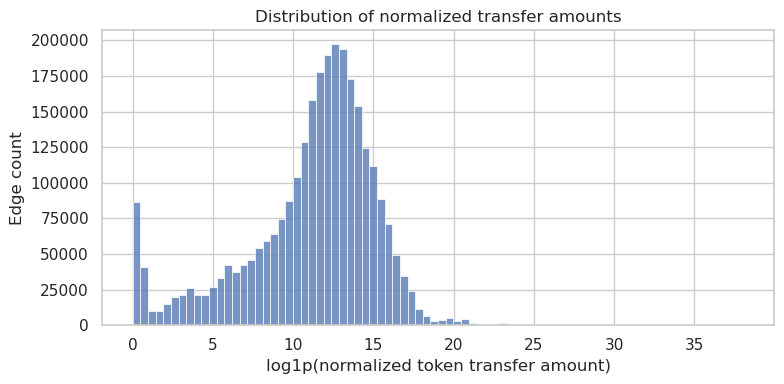

In [23]:
fig, ax = plt.subplots(figsize=(8, 4))

sns.histplot(
    data=edges.loc[
        edges['amount_resolved']
    ],
    x='log1p_amount_token',
    bins=80,
    ax=ax
)

ax.set_xlabel('log1p(normalized token transfer amount)')
ax.set_ylabel('Edge count')
ax.set_title('Distribution of normalized transfer amounts')

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# AMOUNT RESOLUTION BY OBSERVATION WINDOW
# ============================================================

amount_resolution_by_q = (
    edges.groupby(
        'experiment_id'
    )
    .agg(
        edge_rows=(
            'tx_signature',
            'size'
        ),
        resolved_edges=(
            'amount_resolved',
            'sum'
        )
    )
)

amount_resolution_by_q['unresolved_edges'] = amount_resolution_by_q['edge_rows'] - amount_resolution_by_q['resolved_edges']

amount_resolution_by_q['resolution_rate'] = amount_resolution_by_q['resolved_edges'] / amount_resolution_by_q['edge_rows']

display(amount_resolution_by_q)

,edge_rows,resolved_edges,unresolved_edges,resolution_rate
experiment_id,,,,
q1,303958,303957,1,0.999997
q2,823045,823042,3,0.999996
q3,1735576,1735568,8,0.999995


In [25]:
# ============================================================
# GRAPH-LEVEL AMOUNT COVERAGE
# ============================================================

graph_amount_coverage = (
    edges.groupby(
        [
            'experiment_id',
            'token_mint'
        ]
    )
    .agg(
        n_edges=(
            'tx_signature',
            'size'
        ),
        n_amount_resolved=(
            'amount_resolved',
            'sum'
        )
    )
    .reset_index()
)

graph_amount_coverage['n_amount_unresolved'] = graph_amount_coverage['n_edges'] - graph_amount_coverage['n_amount_resolved']

graph_amount_coverage['amount_resolution_rate'] = graph_amount_coverage['n_amount_resolved'] / graph_amount_coverage['n_edges']

graph_amount_coverage['amount_all_resolved'] = graph_amount_coverage['n_amount_unresolved'] == 0

print('GRAPH-LEVEL AMOUNT COVERAGE')

display(
    graph_amount_coverage.groupby(
        'experiment_id'
    ).agg(
        n_graphs=(
            'token_mint',
            'size'
        ),
        fully_resolved_graphs=(
            'amount_all_resolved',
            'sum'
        ),
        min_resolution_rate=(
            'amount_resolution_rate',
            'min'
        ),
        mean_resolution_rate=(
            'amount_resolution_rate',
            'mean'
        )
    )
)

GRAPH-LEVEL AMOUNT COVERAGE


,n_graphs,fully_resolved_graphs,min_resolution_rate,mean_resolution_rate
experiment_id,,,,
q1,912,911,0.997468,0.999997
q2,956,954,0.998722,0.999998
q3,889,884,0.998575,0.999997


In [26]:
print('\nCLEANED DATASET SIZES')
print(f'nodes : {nodes.shape}')
print(f'labels: {labels.shape}')
print(f'edges : {edges.shape}')

print('\nLABEL STATUS COUNTS')
display(labels['label_status'].value_counts(dropna=False))

print('\nNODE LABEL COUNTS')
display(nodes['rug_pull_label'].value_counts(dropna=False).sort_index())


CLEANED DATASET SIZES
nodes : (5332, 22)
labels: (8100, 30)
edges : (2862579, 19)

LABEL STATUS COUNTS


label_status
VALID                                        5335
UNKNOWN_MISSING_LIQUIDITY_HISTORY            1287
IN_WINDOW_EVENT                              1039
UNKNOWN_INSUFFICIENT_PERSISTENCE_COVERAGE     107
UNKNOWN_MISSING_POST_EVENT_PRICE               96
UNKNOWN_MISSING_PRE_EVENT_PRICE                92
UNKNOWN_INVALID_LIQUIDITY_BASELINE             42
UNKNOWN_INSUFFICIENT_LIQUIDITY_HISTORY         42
UNKNOWN_INSUFFICIENT_PERSISTENCE_HORIZON       39
UNKNOWN_OBSERVATION_BOUNDARY_AMBIGUOUS         11
UNKNOWN_MISSING_PRICE_HISTORY                  10
Name: count, dtype: int64


NODE LABEL COUNTS


rug_pull_label
0    3448
1    1884
Name: count, dtype: int64

In [27]:
KEY = ['lp_address', 'token_mint', 'experiment_id']

valid_labels = labels[
    (labels['label_status'] == 'VALID') &
    labels['rug_pull_label'].notna()
].copy()

label_node_audit = valid_labels[
    KEY + [
        'rug_pull_label',
        'token_creation_time',
        'observation_window_seconds',
        'observation_end_time',
        'label_available_time'
    ]
].merge(
    nodes[
        KEY + [
            'rug_pull_label',
            'creation_time',
            'observation_window_seconds',
            'observation_end',
            'label_available_time'
        ]
    ],
    on=KEY,
    how='outer',
    indicator=True,
    suffixes=('_label', '_node')
)

print(label_node_audit['_merge'].value_counts())

display(
    label_node_audit.loc[
        label_node_audit['_merge'] != 'both',
        KEY + ['_merge']
    ]
)

_merge
both          5332
left_only        3
right_only       0
Name: count, dtype: int64


,lp_address,token_mint,experiment_id,_merge
1121,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump,q1,left_only
1122,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump,q2,left_only
1123,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump,q3,left_only


In [28]:
matched = label_node_audit[label_node_audit['_merge'] == 'both']

print('label mismatch:', (matched['rug_pull_label_label'] != matched['rug_pull_label_node']).sum())
print('creation_time mismatch:', (matched['token_creation_time'] != matched['creation_time']).sum())
print('window length mismatch:', (matched['observation_window_seconds_label'] != matched['observation_window_seconds_node']).sum())
print('observation_end mismatch:', (matched['observation_end_time'] != matched['observation_end']).sum())
print('label_available_time mismatch:', (matched['label_available_time_label'] != matched['label_available_time_node']).sum())

assert (label_node_audit['_merge'] == 'right_only').sum() == 0
assert (matched['rug_pull_label_label'] != matched['rug_pull_label_node']).sum() == 0
assert (matched['token_creation_time'] != matched['creation_time']).sum() == 0
assert (matched['observation_window_seconds_label'] != matched['observation_window_seconds_node']).sum() == 0
assert (matched['observation_end_time'] != matched['observation_end']).sum() == 0
assert (matched['label_available_time_label'] != matched['label_available_time_node']).sum() == 0

label mismatch: 0
creation_time mismatch: 0
window length mismatch: 0
observation_end mismatch: 0
label_available_time mismatch: 0


**<span style="color:red">Observation:</span>** One token has VALID labels for q1/q2/q3
but no corresponding rows in `graph_nodes.csv`. Under the node-collector logic, ordinary
missing numerical features do not by themselves suppress a node row; incomplete features
are retained as missing values.

Therefore, these three missing rows are recorded as a persisted-node-output discrepancy
rather than ordinary feature missingness. The exact cause cannot be determined from the
current artifacts and would require the collector logs or progress state. All 5,332
matched rows agree on label and temporal metadata.

## Step 2 — Separate by Observation Window

q1/q2/q3 represent three different observation-window lengths. Many tokens appear in
more than one observation window, so separate tables are created for each experiment
before the remaining analyses are performed.

This separation is not a train/validation/test split. The central chronological
model-development split is defined later in this notebook, after the complete-data
descriptive analyses and leakage audits.

In [29]:
def separate_qs(df, expr_id):
    """Take one experiment's slice. experiment_id is dropped: it is now a property of the table."""
    out = df[df.experiment_id == expr_id].drop(columns='experiment_id')
    return out.reset_index(drop=True)

In [30]:
nodes_q = {q: separate_qs(nodes, q) for q in EXPERIMENTS}
edges_q = {q: separate_qs(edges, q) for q in EXPERIMENTS}
labels_q = {q: separate_qs(labels, q) for q in EXPERIMENTS}

for q in EXPERIMENTS:
    print(f'{q}: {len(nodes_q[q]):5} tokens, {len(edges_q[q]):7} transfers, '
          f'window = {nodes_q[q].observation_window_seconds.iloc[0]} s')

q1:  1961 tokens,  303958 transfers, window = 750 s
q2:  1798 tokens,  823045 transfers, window = 2127 s
q3:  1573 tokens, 1735576 transfers, window = 5585 s


## Step 3 — The `full` and `panel` token scopes

For post-observation supervised prediction, a rug-pull event that occurs inside the
observation window cannot serve as a future binary target. Longer windows therefore
exclude more early events. Additional samples can also be unavailable because of
`UNKNOWN_*` label states. In the current model-ready node tables the token sets are nested
(q3 ⊂ q2 ⊂ q1), so the common-token panel is the q3 token set.

* **full** = every available supervised node sample for this observation window
* **panel** = only supervised node samples shared across q1/q2/q3

Both are reported: `full` preserves all available supervised node samples for each
observation window, while `panel` enables a controlled comparison of window length using
the same tokens.

In [31]:
q1_tokens = set(nodes_q['q1'].token_mint)
q2_tokens = set(nodes_q['q2'].token_mint)
q3_tokens = set(nodes_q['q3'].token_mint)

print('q2 subset of q1:', q2_tokens.issubset(q1_tokens))
print('q3 subset of q2:', q3_tokens.issubset(q2_tokens))

assert q2_tokens.issubset(q1_tokens)
assert q3_tokens.issubset(q2_tokens)

q2 subset of q1: True
q3 subset of q2: True


In [32]:
common_tokens = set.intersection(*[set(nodes_q[q].token_mint) for q in EXPERIMENTS])
print(f'common tokens: {len(common_tokens)}')

# what does the panel throw away?
for q in EXPERIMENTS:
    df = nodes_q[q]
    dropped = df[~df.token_mint.isin(common_tokens)]
    print(f'{q}: drops {len(dropped):4} tokens | rug rate of dropped = '
          f'{dropped.rug_pull_label.mean() if len(dropped) else float("nan"):.2f}')

common tokens: 1573
q1: drops  388 tokens | rug rate of dropped = 0.75
q2: drops  225 tokens | rug rate of dropped = 0.76
q3: drops    0 tokens | rug rate of dropped = nan


**<span style="color:red">Observation:</span>** The common-token panel is strongly selected toward tokens that survive
the longer observation windows. The samples removed from q1 and q2 have much higher rug
rates, so `full` is retained as the primary analysis scope and `panel` is used only for
controlled cross-window comparisons.

In [33]:
panel_meta = pd.concat([
    nodes_q[q]
    .loc[
        nodes_q[q]['token_mint'].isin(common_tokens),
        ['token_mint', 'lp_address', 'rug_pull_label', 'creation_time']
    ]
    .assign(experiment_id=q)
    for q in EXPERIMENTS
])

print('panel tokens with inconsistent labels:', (panel_meta.groupby('token_mint')['rug_pull_label'].nunique() > 1).sum())
print('panel tokens with inconsistent LP address:', (panel_meta.groupby('token_mint')['lp_address'].nunique() > 1).sum())
print('panel tokens with inconsistent creation_time:', (panel_meta.groupby('token_mint')['creation_time'].nunique() > 1).sum())

assert (panel_meta.groupby('token_mint')['rug_pull_label'].nunique() <= 1).all()
assert (panel_meta.groupby('token_mint')['lp_address'].nunique() <= 1).all()
assert (panel_meta.groupby('token_mint')['creation_time'].nunique() <= 1).all()

panel tokens with inconsistent labels: 0
panel tokens with inconsistent LP address: 0
panel tokens with inconsistent creation_time: 0


In [34]:
def apply_scope(df, scope):
    """Apply the predefined full or common-token panel scope."""
    if scope == 'full':
        return df

    if scope == 'panel':
        return df[df.token_mint.isin(common_tokens)].reset_index(drop=True)

    raise ValueError("scope must be either 'full' or 'panel'")

## Step 4 — Sanity checks

These checks verify key uniqueness, observation-window integrity, label timing, edge
membership, and basic numerical validity. Any failed check raises an `AssertionError`
and stops downstream processing.

In [35]:
def run_checks(nodes_df, edges_df, labels_df, name):
    checks = {}

    # ------------------------------------------------------------
    # Model-ready node population
    # ------------------------------------------------------------
    node_keys = pd.MultiIndex.from_frame(
        nodes_df[
            ['lp_address', 'token_mint']
        ].drop_duplicates()
    )

    # ------------------------------------------------------------
    # VALID labelled population
    # Edges are collected directly from these rows, not from
    # graph_nodes.csv.
    # ------------------------------------------------------------
    valid_labels = labels_df[
        (labels_df['label_status'] == 'VALID')
        &
        (labels_df['rug_pull_label'].isin([0, 1]))
    ].copy()

    label_keys = pd.MultiIndex.from_frame(
        valid_labels[
            ['lp_address', 'token_mint']
        ].drop_duplicates()
    )

    label_windows = (
        valid_labels[
            [
                'lp_address',
                'token_mint',
                'token_creation_time',
                'observation_end_time'
            ]
        ]
        .rename(
            columns={
                'token_creation_time': 'observation_start',
                'observation_end_time': 'observation_end'
            }
        )
        .drop_duplicates()
    )

    label_window_keys = pd.MultiIndex.from_frame(
        label_windows[
            [
                'lp_address',
                'token_mint',
                'observation_start',
                'observation_end'
            ]
        ]
    )

    # ------------------------------------------------------------
    # Recovered-edge population
    # ------------------------------------------------------------
    edge_keys = pd.MultiIndex.from_frame(
        edges_df[
            ['lp_address', 'token_mint']
        ].drop_duplicates()
    )

    edge_window_keys = pd.MultiIndex.from_frame(
        edges_df[
            [
                'lp_address',
                'token_mint',
                'observation_start',
                'observation_end'
            ]
        ].drop_duplicates()
    )

    edge_dedup_cols = [
        'lp_address',
        'token_mint',
        'tx_signature',
        'source_address',
        'target_address',
        'original_amount'
    ]

    # ------------------------------------------------------------
    # Node-level checks
    # ------------------------------------------------------------
    checks['token key is unique'] = (
        not nodes_df.duplicated(
            ['lp_address', 'token_mint']
        ).any()
    )

    checks['token_mint is unique'] = (not nodes_df.duplicated('token_mint').any())

    checks['one window length'] = nodes_df.observation_window_seconds.nunique() == 1

    checks['window timestamps match duration'] = ((nodes_df.observation_end - nodes_df.observation_start) == nodes_df.observation_window_seconds).all()

    checks['observation starts at creation time'] = (nodes_df.observation_start == nodes_df.creation_time).all()

    checks['labels available after cutoff'] = (nodes_df.label_lead_time > 0).all()

    checks['labels are binary'] = nodes_df.rug_pull_label.isin([0, 1]).all()

    checks['node rows belong to VALID labels'] = node_keys.isin(label_keys).all()

    # ------------------------------------------------------------
    # Edge-level checks
    # ------------------------------------------------------------
    checks['edges inside window'] = ((edges_df.t_frac >= 0) & (edges_df.t_frac < 1)).all()

    checks['edges belong to VALID labelled samples'] = edge_keys.isin(label_keys).all()

    checks['edge windows match VALID label windows'] = edge_window_keys.isin(label_window_keys).all()

    checks['no self-loop edges'] = (edges_df.source_address != edges_df.target_address).all()

    checks['edge dedup key is unique'] = ~edges_df.duplicated(edge_dedup_cols).any()

    checks['edge window duration positive'] = (edges_df.observation_end > edges_df.observation_start).all()

    checks['resolved normalized edge amounts finite and non-negative'] = (
        np.isfinite(
            edges_df.loc[
                edges_df['amount_resolved'],
                'amount_token'
            ]
        ).all()
        &
        (
            edges_df.loc[
                edges_df['amount_resolved'],
                'amount_token'
            ]
            >= 0
        ).all()
    )

    checks['resolved edge amounts have canonical fields'] = (
        edges_df.loc[
            edges_df['amount_resolved'],
            [
                'amount_raw',
                'decimals',
                'amount_token_exact'
            ]
        ]
        .replace('', pd.NA)
        .notna()
        .all(axis=1)
        .all()
    )

    # ------------------------------------------------------------
    # Audit: valid recovered-edge samples that do not have a
    # persisted graph_nodes.csv row.
    #
    # This is reported, not treated as an edge-data failure.
    # ------------------------------------------------------------
    edge_sample_keys = (
        edges_df[
            ['lp_address', 'token_mint']
        ]
        .drop_duplicates()
    )

    node_sample_keys = (
        nodes_df[
            ['lp_address', 'token_mint']
        ]
        .drop_duplicates()
    )

    edge_without_node = (
        edge_sample_keys
        .merge(
            node_sample_keys,
            on=['lp_address', 'token_mint'],
            how='left',
            indicator=True
        )
        .query('_merge == "left_only"')
        .drop(columns='_merge')
        .reset_index(drop=True)
    )

    print(f'\n[{name}]')

    for k, v in checks.items():
        print(f'  {"OK  " if v else "FAIL"} {k}')

    print(f'  INFO recovered-edge samples without a persisted node row: {len(edge_without_node)}')

    if len(edge_without_node):
        display(edge_without_node)

    if not all(checks.values()):
        raise AssertionError(f'{name}: one or more sanity checks failed')

    return checks

In [36]:
for q in EXPERIMENTS:
    run_checks(nodes_q[q], edges_q[q], labels_q[q], q)


[q1]
  OK   token key is unique
  OK   token_mint is unique
  OK   one window length
  OK   window timestamps match duration
  OK   observation starts at creation time
  OK   labels available after cutoff
  OK   labels are binary
  OK   node rows belong to VALID labels
  OK   edges inside window
  OK   edges belong to VALID labelled samples
  OK   edge windows match VALID label windows
  OK   no self-loop edges
  OK   edge dedup key is unique
  OK   edge window duration positive
  OK   resolved normalized edge amounts finite and non-negative
  OK   resolved edge amounts have canonical fields
  INFO recovered-edge samples without a persisted node row: 1


,lp_address,token_mint
0,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump



[q2]
  OK   token key is unique
  OK   token_mint is unique
  OK   one window length
  OK   window timestamps match duration
  OK   observation starts at creation time
  OK   labels available after cutoff
  OK   labels are binary
  OK   node rows belong to VALID labels
  OK   edges inside window
  OK   edges belong to VALID labelled samples
  OK   edge windows match VALID label windows
  OK   no self-loop edges
  OK   edge dedup key is unique
  OK   edge window duration positive
  OK   resolved normalized edge amounts finite and non-negative
  OK   resolved edge amounts have canonical fields
  INFO recovered-edge samples without a persisted node row: 1


,lp_address,token_mint
0,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump



[q3]
  OK   token key is unique
  OK   token_mint is unique
  OK   one window length
  OK   window timestamps match duration
  OK   observation starts at creation time
  OK   labels available after cutoff
  OK   labels are binary
  OK   node rows belong to VALID labels
  OK   edges inside window
  OK   edges belong to VALID labelled samples
  OK   edge windows match VALID label windows
  OK   no self-loop edges
  OK   edge dedup key is unique
  OK   edge window duration positive
  OK   resolved normalized edge amounts finite and non-negative
  OK   resolved edge amounts have canonical fields
  INFO recovered-edge samples without a persisted node row: 1


,lp_address,token_mint
0,4H2UYcZfw1rFdBsSqSBpopKohqu2ZbbePDj6qT2jx4Pf,7VLmqqHQbP6gkAxRL8o5Qua5MckL86YHDB3PoLm3pump


### Fine-Grained Temporal Rug-Pull Prevalence — Descriptive Dataset Audit

To examine temporal non-stationarity without imposing a train/validation/test split,
each observation-window population is sorted by token creation time and divided into
ten consecutive approximately equal-count chronological bins.

This analysis is descriptive dataset accounting only. The bins are not model-development
splits and are not used for feature selection, preprocessing, threshold selection, or
model tuning. Because q1/q2/q3 contain different eligible supervised populations, the
curves are interpreted within each observation window rather than as a same-token
comparison.

In [37]:
N_CHRONO_BINS = 10

temporal_parts = []

for q in EXPERIMENTS:
    d = nodes_q[q][['creation_time', 'rug_pull_label']].sort_values('creation_time').reset_index(drop=True).copy()

    # Consecutive approximately equal-count chronological bins.
    d['chrono_bin'] = np.floor(np.arange(len(d)) * N_CHRONO_BINS / len(d)).astype(int)

    d['chrono_bin'] = d['chrono_bin'].clip(upper=N_CHRONO_BINS - 1)

    s = d.groupby('chrono_bin').agg(median_creation_time=('creation_time', 'median'), rug_rate=('rug_pull_label', 'mean'), n=('rug_pull_label', 'size')).reset_index()

    s['experiment_id'] = q
    s['bin_number'] = s['chrono_bin'] + 1
    s['date'] = pd.to_datetime(s['median_creation_time'], unit='s', utc=True)

    temporal_parts.append(s)

temporal_prevalence = pd.concat(temporal_parts, ignore_index=True)

peak_idx = temporal_prevalence.groupby('experiment_id')['rug_rate'].idxmax()

temporal_peak_summary = (
    temporal_prevalence
    .loc[
        peak_idx,
        ['experiment_id', 'bin_number', 'date', 'rug_rate', 'n']
    ]
    .sort_values('experiment_id')
    .reset_index(drop=True)
)

temporal_peak_summary['rug_rate_percent'] = temporal_peak_summary['rug_rate'] * 100

display(temporal_peak_summary)

,experiment_id,bin_number,date,rug_rate,n,rug_rate_percent
0,q1,8,2024-08-02 21:04:40.500000+00:00,0.607143,196,60.714286
1,q2,8,2024-08-03 14:19:00.500000+00:00,0.588889,180,58.888889
2,q3,8,2024-08-04 23:29:47+00:00,0.515924,157,51.592357


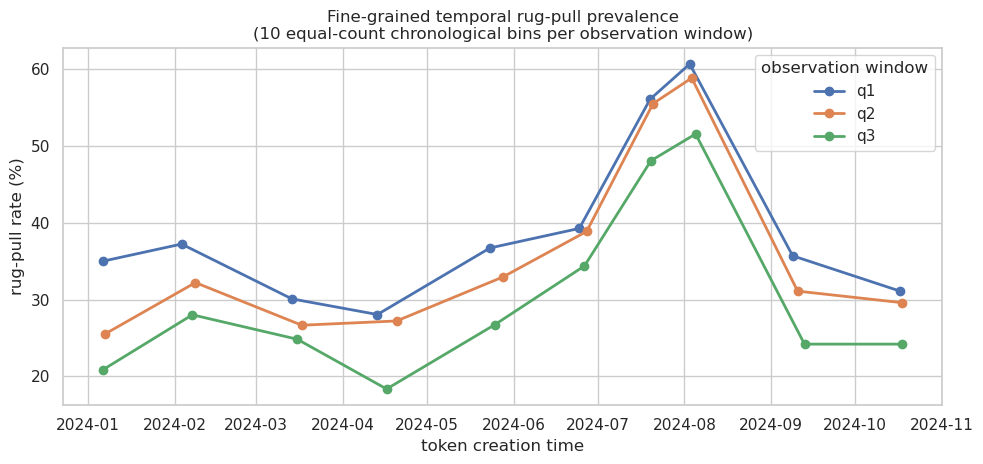

In [38]:
fig, ax = plt.subplots(figsize=(10, 4.8))

for q in EXPERIMENTS:
    p = temporal_prevalence[temporal_prevalence['experiment_id'] == q]

    ax.plot(
        p['date'],
        p['rug_rate'] * 100,
        marker='o',
        linewidth=2,
        label=q
    )

ax.set_ylabel('rug-pull rate (%)')
ax.set_xlabel('token creation time')
ax.set_title('Fine-grained temporal rug-pull prevalence\n(10 equal-count chronological bins per observation window)')
ax.legend(title='observation window')

plt.tight_layout()
plt.show()

**<span style="color:red">Observation:</span>** The chronological bins show that rug-pull
prevalence is not constant over the data-collection period. The exact peak bin, date, and
prevalence for each observation window are reported by the table above.

This analysis is descriptive only. No train/validation/test boundaries are defined here,
and the temporal bins are not used as modelling partitions. Because the bins are
constructed separately within the q1/q2/q3 populations, differences between the three
curves should not be interpreted as same-token effects of observation-window length.

# Exploratory Data Analysis (EDA)

**EDA policy:** The analyses in this section characterize the complete cleaned dataset
before model-development partitions are used. Descriptive label distributions,
missingness, feature distributions, univariate associations, correlations, and graph
structure may therefore be examined on the complete data.

No model-based feature importance or learned missing-value imputation is fitted on the
complete cleaned dataset.

After all complete-data EDA and leakage audits are finished, this notebook creates one
central chronological train/validation/test split. Learned missing-data preprocessing and
model-based feature importance are then fitted using training data only. Validation and
test data do not influence those fitted transformations or the feature-importance ranking.

## Step 1 — Labels and class balance

In [39]:
def label_summary(nodes_df, labels_df):
    """Rug rate, plus how many tokens the labelling rules could not label."""
    n_rug = int(nodes_df.rug_pull_label.sum())
    n_valid_labels = int(((labels_df['label_status'] == 'VALID') & labels_df['rug_pull_label'].notna()).sum())
    return pd.Series({
        'attempted': len(labels_df),
        'valid_labels': n_valid_labels,
        'model_ready': len(nodes_df),
        'non_rug': len(nodes_df) - n_rug,
        'rug': n_rug,
        'rug_rate': nodes_df.rug_pull_label.mean(),
        'label_coverage': n_valid_labels / len(labels_df),
        'model_ready_coverage': len(nodes_df) / len(labels_df),
        'valid_without_node_row': n_valid_labels - len(nodes_df),
        'in_window_event': int((labels_df.label_status == 'IN_WINDOW_EVENT').sum()),
    })

In [40]:
balance = pd.DataFrame({q: label_summary(nodes_q[q], labels_q[q]) for q in EXPERIMENTS}).T

balance

,attempted,valid_labels,model_ready,non_rug,rug,rug_rate,label_coverage,model_ready_coverage,valid_without_node_row,in_window_event
q1,2700.0,1962.0,1961.0,1196.0,765.0,0.390107,0.726667,0.726296,1.0,128.0
q2,2700.0,1799.0,1798.0,1153.0,645.0,0.358732,0.666296,0.665926,1.0,321.0
q3,2700.0,1574.0,1573.0,1099.0,474.0,0.301335,0.582963,0.582593,1.0,590.0


In [41]:
status_counts = pd.DataFrame({
    q: labels_q[q]['label_status'].value_counts(dropna=False)
    for q in EXPERIMENTS
}).fillna(0).astype(int)

status_counts

,q1,q2,q3
label_status,,,
IN_WINDOW_EVENT,128,321,590
UNKNOWN_INSUFFICIENT_LIQUIDITY_HISTORY,14,14,14
UNKNOWN_INSUFFICIENT_PERSISTENCE_COVERAGE,41,36,30
UNKNOWN_INSUFFICIENT_PERSISTENCE_HORIZON,13,13,13
UNKNOWN_INVALID_LIQUIDITY_BASELINE,14,14,14
UNKNOWN_MISSING_LIQUIDITY_HISTORY,429,429,429
UNKNOWN_MISSING_POST_EVENT_PRICE,39,36,21
UNKNOWN_MISSING_PRE_EVENT_PRICE,52,29,11
UNKNOWN_MISSING_PRICE_HISTORY,4,3,3


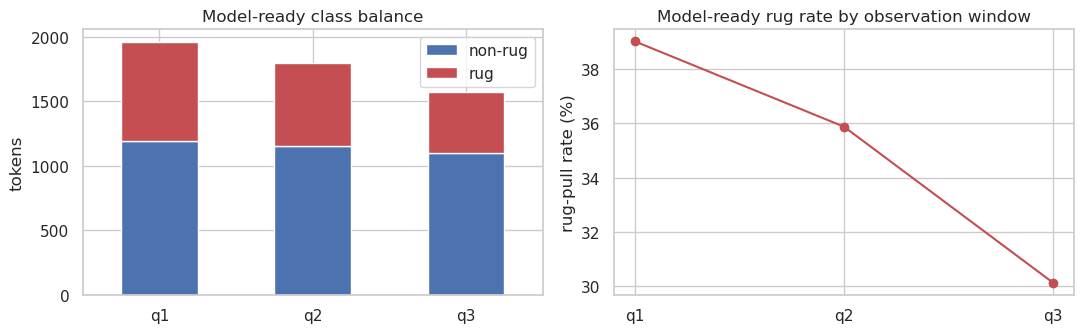

In [42]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

balance[['non_rug', 'rug']].plot(kind='bar', stacked=True, ax=ax[0], color=['#4c72b0', '#c44e52'])
ax[0].set_title('Model-ready class balance')
ax[0].set_ylabel('tokens')
ax[0].tick_params(axis='x', rotation=0)
ax[0].legend(['non-rug', 'rug'])

ax[1].plot(balance.index, balance.rug_rate * 100, marker='o', color='#c44e52')
ax[1].set_title('Model-ready rug rate by observation window')
ax[1].set_ylabel('rug-pull rate (%)')

plt.tight_layout()
plt.show()

**<span style="color:red">Observation:</span>** Label availability decreases as the
observation window becomes longer: valid-label coverage falls from about 72.7% in q1 to
66.6% in q2 and 58.3% in q3, while `IN_WINDOW_EVENT` cases increase from 128 to 321 and
590. The model-ready rug-pull rate also decreases from about 39.0% to 35.9% and 30.1%.
Therefore, q1/q2/q3 should not be interpreted as identical populations observed for
different durations; the eligible supervised population changes with the cutoff.

## Step 2 — Recovered-Edge Presence

`graph_edges.csv` contains the retained recovered edge rows from the final edge export.
A token-experiment sample with no edge row therefore has no retained recovered transfer
in this export. This does not prove that the token had no on-chain transfers, because
transfer discovery begins from the mint-address signature history and is therefore only
a partial view of token-transfer activity.

The analysis below therefore measures **recovered-edge presence**, not proof of true
transfer absence or complete transfer coverage. Graph diagnostics use only samples with
at least one recovered edge.

In [43]:
def add_edge_counts(nodes_df, edges_df):
    """Attach the number of recovered transfers present in the current edge file."""
    counts = edges_df.groupby('token_mint').size().rename('n_transfers')
    out = nodes_df.merge(counts, on='token_mint', how='left')
    out['n_transfers'] = out.n_transfers.fillna(0).astype(int)
    out['has_recovered_edges'] = out.n_transfers > 0
    return out


for q in EXPERIMENTS:
    nodes_q[q] = add_edge_counts(nodes_q[q], edges_q[q])
    cov = nodes_q[q].has_recovered_edges
    print(f'{q}: {cov.sum():3} / {len(cov):5} tokens have recovered edges ({100 * cov.mean():.1f}%)')

q1: 911 /  1961 tokens have recovered edges (46.5%)
q2: 955 /  1798 tokens have recovered edges (53.1%)


q3: 888 /  1573 tokens have recovered edges (56.5%)


In [44]:
# subset with at least one recovered edge, used for graph diagnostics
edge_present = {q: nodes_q[q][nodes_q[q].has_recovered_edges].reset_index(drop=True) for q in EXPERIMENTS}

# Descriptive dataset audit: compare class prevalence in the full supervised data
# with the non-empty recovered-graph subset. This is not used for model tuning.
for q in EXPERIMENTS:
    print(f'{q}: rug rate all = {nodes_q[q].rug_pull_label.mean():.3f} | recovered-edge subset = {edge_present[q].rug_pull_label.mean():.3f}')

q1: rug rate all = 0.390 | recovered-edge subset = 0.437
q2: rug rate all = 0.359 | recovered-edge subset = 0.392
q3: rug rate all = 0.301 | recovered-edge subset = 0.319


In [45]:
for q in EXPERIMENTS:
    print(f'\n{q} recovered-edge presence by class:')
    display(
        nodes_q[q]
        .groupby('rug_pull_label')['has_recovered_edges']
        .agg(['count', 'sum', 'mean'])
        .rename(index={0: 'non-rug', 1: 'rug'})
    )


q1 recovered-edge presence by class:


,count,sum,mean
rug_pull_label,,,
non-rug,1196,513,0.428930
rug,765,398,0.520261



q2 recovered-edge presence by class:


,count,sum,mean
rug_pull_label,,,
non-rug,1153,581,0.503903
rug,645,374,0.579845



q3 recovered-edge presence by class:


,count,sum,mean
rug_pull_label,,,
non-rug,1099,605,0.550500
rug,474,283,0.597046


**<span style="color:red">Observation:</span>** The presence of at least one recovered
edge is consistently higher among rug-pull samples than among non-rug samples across
q1/q2/q3. This shows that the non-empty recovered-graph subset is class-dependent and
should not be treated as representative of the full supervised dataset. Importantly, 
absence of an edge row does not prove that the token had no on-chain transfers, because
mint-address-based transfer discovery provides only a partial view of token-transfer activity.

### Earliest Recovered-Edge Presence Across Observation Windows — Common-Panel Samples

The marginal recovered-edge rates of q1/q2/q3 are based on different supervised
populations. To compare recovered-edge presence across observation-window lengths while
holding token identity fixed, this analysis uses the common q1/q2/q3 token panel.

For each token, the earliest observation window containing at least one row in the
current recovered-edge table is recorded. This represents earliest recovered-edge
presence, not the token's true first transfer time and not proof of collection
completeness.

Monotonicity across q1/q2/q3 is checked only as an internal consistency property of the
current recovered edge output. It is not treated as evidence that the recovered graph is
complete.

In [46]:
panel_edge_presence = nodes_q['q3'].loc[nodes_q['q3']['token_mint'].isin(common_tokens), ['token_mint', 'rug_pull_label']].copy()

for q in EXPERIMENTS:
    q_presence = (nodes_q[q][['token_mint', 'has_recovered_edges']].rename(columns={'has_recovered_edges': q}))

    panel_edge_presence = panel_edge_presence.merge(q_presence, on='token_mint', how='left', validate='one_to_one')

assert panel_edge_presence[['q1', 'q2', 'q3']].notna().all().all()

non_monotone = (
    (panel_edge_presence['q1'] & ~panel_edge_presence['q2'])
    |
    (panel_edge_presence['q2'] & ~panel_edge_presence['q3'])
)

print('common-panel tokens with non-monotone recovered-edge presence:', int(non_monotone.sum()))

if non_monotone.any():
    raise RuntimeError('Recovered-edge presence is not monotone across q1/q2/q3. Inspect these cases before interpreting earliest recovered-edge presence.')

common-panel tokens with non-monotone recovered-edge presence: 0


In [47]:
panel_edge_presence['first_recovered_edge_window'] = np.select(
    [
        panel_edge_presence['q1'],
        panel_edge_presence['q2'],
        panel_edge_presence['q3']
    ],
    [
        'q1',
        'q2',
        'q3'
    ],
    default='none by q3'
)

category_order = [
    'q1',
    'q2',
    'q3',
    'none by q3'
]

edge_emergence_counts = (
    pd.crosstab(
        panel_edge_presence['rug_pull_label'],
        panel_edge_presence['first_recovered_edge_window']
    )
    .reindex(
        index=[0, 1],
        columns=category_order,
        fill_value=0
    )
)

edge_emergence_pct = edge_emergence_counts.div(edge_emergence_counts.sum(axis=1), axis=0) * 100

edge_emergence_pct = edge_emergence_pct.rename(index={0: 'non-rug', 1: 'rug'})

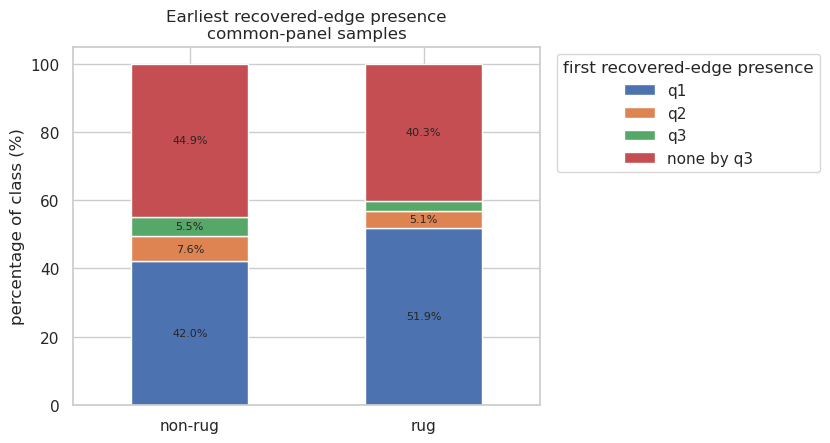

Counts:


first_recovered_edge_window,q1,q2,q3,none by q3
rug_pull_label,,,,
non-rug,462,83,60,494
rug,246,24,13,191


Percentages:


first_recovered_edge_window,q1,q2,q3,none by q3
rug_pull_label,,,,
non-rug,42.0,7.6,5.5,44.9
rug,51.9,5.1,2.7,40.3


In [48]:
fig, ax = plt.subplots(figsize=(8.5, 4.6))

edge_emergence_pct.plot(
    kind='bar',
    stacked=True,
    ax=ax
)

for container in ax.containers:
    bar_labels = [f'{value:.1f}%' if value >= 5 else '' for value in container.datavalues]

    ax.bar_label(
        container,
        labels=bar_labels,
        label_type='center',
        fontsize=8
    )

ax.set_ylabel('percentage of class (%)')
ax.set_xlabel('')
ax.set_title('Earliest recovered-edge presence\ncommon-panel samples')

ax.tick_params(axis='x', rotation=0)
ax.legend(title='first recovered-edge presence', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

print('Counts:')
display(edge_emergence_counts.rename(index={0: 'non-rug', 1: 'rug'}))

print('Percentages:')
display(edge_emergence_pct.round(1))

**<span style="color:red">Observation:</span>** The table and stacked bars above show when
recovered-edge presence first becomes observable within the common-token population.
The result should be interpreted only as a property of the current recovered-edge data.

A token categorized as `none by q3` has no retained edge row in the current edge table by
the longest observation cutoff. This does not prove that the token had no transfers, and
recovered-edge presence should not be interpreted as evidence of complete transfer
recovery.

## Step 3 — Token-Level Features

### Missingness

In [49]:
FEATURES = ['volume_sell_change_percent', 'volume_buy_change_percent',
            'unique_wallet_count', 'unique_wallet_change_percent',
            'liquidity_at_creation', 'liquidity_at_observation_end']

# Check overall feature missingness before interpreting feature distributions or associations
print('Missing features %:')
pd.DataFrame({q: nodes_q[q][FEATURES].isna().mean() * 100 for q in EXPERIMENTS}).round(1)

Missing features %:


,q1,q2,q3
volume_sell_change_percent,66.8,51.2,45.3
volume_buy_change_percent,65.4,50.8,45.3
unique_wallet_count,5.0,6.3,15.8
unique_wallet_change_percent,65.4,50.8,45.2
liquidity_at_creation,94.3,95.3,97.1
liquidity_at_observation_end,57.9,41.1,34.5


In [50]:
def feature_auc(df, col, label='rug_pull_label', min_n=20, min_per_class=10):    
    """Rank AUC of a single feature. 0.5 = no rank separation; values farther from 0.5 indicate stronger univariate separation."""
    d = df[[col, label]].dropna()

    if d[label].nunique() < 2:
        return np.nan          # only one class present -> AUC undefined
    if len(d) < min_n:
        return np.nan          # too few samples to mean anything

    if (d[label].value_counts() < min_per_class).any():
        return np.nan

    pos = d[d[label] == 1][col]
    neg = d[d[label] == 0][col]
    ranks = pd.concat([pos, neg]).rank().values
    
    return (ranks[:len(pos)].sum() - len(pos)*(len(pos)+1)/2) / (len(pos)*len(neg))

### Class-Conditional Missingness — Descriptive Full Dataset

Feature availability is also summarized separately by outcome class. This is a descriptive
data-quality analysis of the complete cleaned dataset and is not used to select predictors
for the final models.

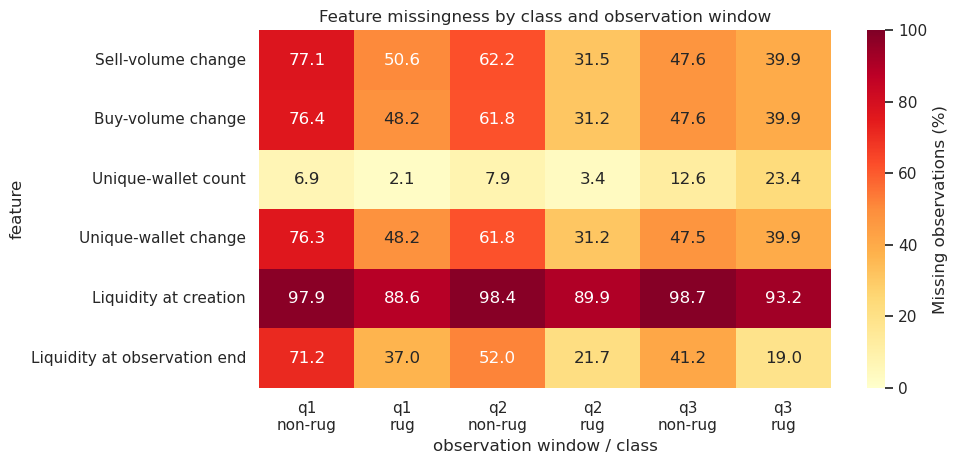

In [51]:
missing_by_class = {}

for q in EXPERIMENTS:
    for label_value, class_name in [(0, 'non-rug'), (1, 'rug')]:
        subset = nodes_q[q][nodes_q[q]['rug_pull_label'] == label_value]

        missing_by_class[f'{q}\n{class_name}'] = subset[FEATURES].isna().mean() * 100

missing_by_class = pd.DataFrame(missing_by_class)

feature_display_names = {
    'volume_sell_change_percent': 'Sell-volume change',
    'volume_buy_change_percent': 'Buy-volume change',
    'unique_wallet_count': 'Unique-wallet count',
    'unique_wallet_change_percent': 'Unique-wallet change',
    'liquidity_at_creation': 'Liquidity at creation',
    'liquidity_at_observation_end': 'Liquidity at observation end'
}

missing_plot = missing_by_class.rename(index=feature_display_names)

fig, ax = plt.subplots(figsize=(10, 4.8))

sns.heatmap(
    missing_plot,
    annot=True,
    fmt='.1f',
    vmin=0,
    vmax=100,
    cmap='YlOrRd',
    cbar_kws={'label': 'Missing observations (%)'},
    ax=ax
)

ax.set_title('Feature missingness by class and observation window')
ax.set_xlabel('observation window / class')
ax.set_ylabel('feature')

plt.tight_layout()
plt.show()

**<span style="color:red">Observation:</span>** Missingness differs across observation
windows and may also differ between the two outcome classes. The heatmap above is used
only to characterize data availability. These differences should not be interpreted as
causal evidence or used directly to select final predictors.

Missing values are preserved throughout the complete-data EDA. No imputation method is
fitted before the chronological split.

After the central split is fixed later in this notebook, exactly two predefined
missing-data representations are constructed separately for q1, q2, and q3:

1. native missing values (`raw_nan`);
2. training-median imputation with explicit missingness indicators
   (`median_indicator`).

The median-imputation parameters are fitted using training predictors only and then
applied unchanged to validation and test data. The outcome label is never supplied to
the imputation model.

### Single-Feature Rank Association — Descriptive Only

The following univariate rank AUC values describe marginal association in the cleaned
dataset. They are not used for final feature selection or model configuration.

In [52]:
node_auc = pd.DataFrame({q: {c: feature_auc(nodes_q[q], c) for c in FEATURES}
                            for q in EXPERIMENTS
                        })

node_n = pd.DataFrame({q: {c: nodes_q[q][[c, 'rug_pull_label']].dropna().shape[0] for c in FEATURES}
                          for q in EXPERIMENTS
                      })

pd.concat(
    {
        'auc': node_auc.round(3),
        'n': node_n
    },
    axis=1
)

auc                   n            
                                 q1     q2     q3    q1    q2    q3
volume_sell_change_percent    0.649  0.612  0.602   652   878   861
volume_buy_change_percent     0.613  0.598  0.572   678   885   861
unique_wallet_count           0.665  0.645  0.610  1862  1685  1324
unique_wallet_change_percent  0.545  0.522  0.578   679   885   862
liquidity_at_creation         0.766  0.746  0.759   112    84    46
liquidity_at_observation_end  0.665  0.677  0.645   826  1059  1030

**<span style="color:red">Observation:</span>** Univariate AUC values must be interpreted
together with their non-missing sample counts. A feature can show apparently strong
separation while being observed for only a small and potentially selected subset of
tokens. These values are descriptive only and do not determine the final feature set.

### Robust Distribution Summaries — Descriptive Full Dataset

In [53]:
for q in EXPERIMENTS:
    print(f'\n{q} feature medians by class:')
    display(
        nodes_q[q]
        .groupby('rug_pull_label')[FEATURES]
        .median()
        .rename(index={0: 'non-rug', 1: 'rug'})
        .round(3)
    )

    print(f'{q} feature IQR:')
    display(
        nodes_q[q]
        .groupby('rug_pull_label')[FEATURES]
        .quantile([0.25, 0.75])
        .rename(index={0: 'non-rug', 1: 'rug'}, level=0)
        .round(3)
    )


q1 feature medians by class:


,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,liquidity_at_creation,liquidity_at_observation_end
rug_pull_label,,,,,,
non-rug,21.918,-13.093,0.0,19.301,6038.261,27361.192
rug,133.993,53.802,105.0,27.441,32864.976,46596.530


q1 feature IQR:


volume_sell_change_percent  volume_buy_change_percent  unique_wallet_count  unique_wallet_change_percent  \
rug_pull_label                                                                                                                  
non-rug        0.25                     -56.862                    -68.638                  0.0                       -28.624   
               0.75                     192.705                    125.176                 94.0                       101.881   
rug            0.25                      17.722                    -20.675                  0.0                        -8.457   
               0.75                     478.117                    194.191                308.0                       132.860   

                     liquidity_at_creation  liquidity_at_observation_end  
rug_pull_label                                                            
non-rug        0.25                 33.716                      8334.679  
               0.75              22220.007                     47867.273  
rug            0.25              11009.319                     25004.356  
               0.75             123087.508                    139955.923


q2 feature medians by class:


,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,liquidity_at_creation,liquidity_at_observation_end
rug_pull_label,,,,,,
non-rug,6.924,-20.452,56.0,2.495,6038.261,27854.189
rug,53.416,23.941,306.0,-2.442,19252.368,55491.491


... (2 outputs left out)


q3 feature medians by class:


,volume_sell_change_percent,volume_buy_change_percent,unique_wallet_count,unique_wallet_change_percent,liquidity_at_creation,liquidity_at_observation_end
rug_pull_label,,,,,,
non-rug,-32.921,-40.964,242.0,-25.052,5811.898,29564.272
rug,12.460,-14.676,544.0,-7.990,15878.616,54078.786


q3 feature IQR:


volume_sell_change_percent  volume_buy_change_percent  unique_wallet_count  unique_wallet_change_percent  \
rug_pull_label                                                                                                                  
non-rug        0.25                     -81.530                    -84.767                  0.0                       -68.157   
               0.75                      81.221                     45.573               1160.0                        30.462   
rug            0.25                     -47.194                    -67.368                247.0                       -39.180   
               0.75                     113.962                     52.085               1439.5                        24.076   

                     liquidity_at_creation  liquidity_at_observation_end  
rug_pull_label                                                            
non-rug        0.25                  5.454                     12884.321  
               0.75              11051.117                     56802.941  
rug            0.25               7611.639                     25278.854  
               0.75              39076.667                    119575.051

**<span style="color:red">Observation:</span>** The class-conditional medians and
interquartile ranges summarize the observed non-missing values in each observation
window. Because several features have substantial and class-dependent missingness,
these summaries should be interpreted as descriptive conditional patterns rather than
population-level or causal effects.

### Feature Correlations — Descriptive Full Dataset

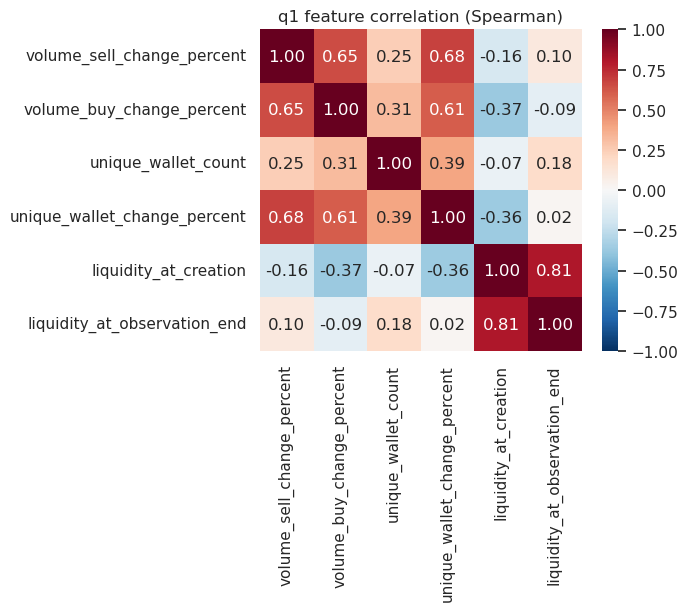

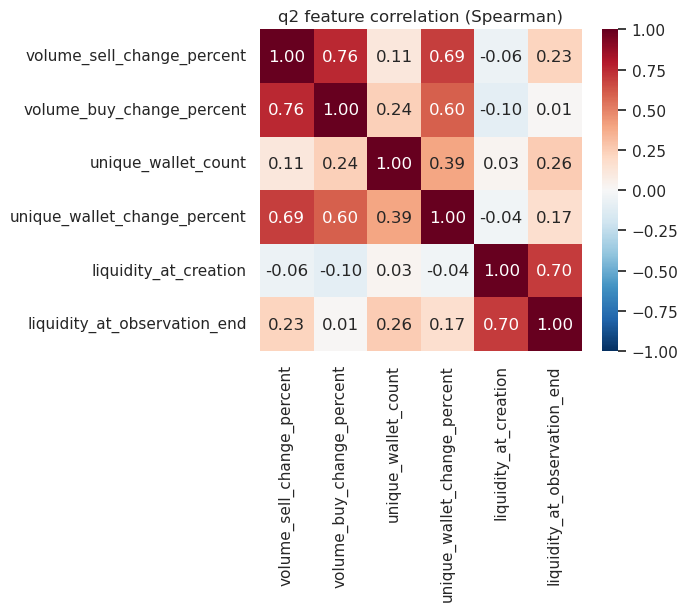

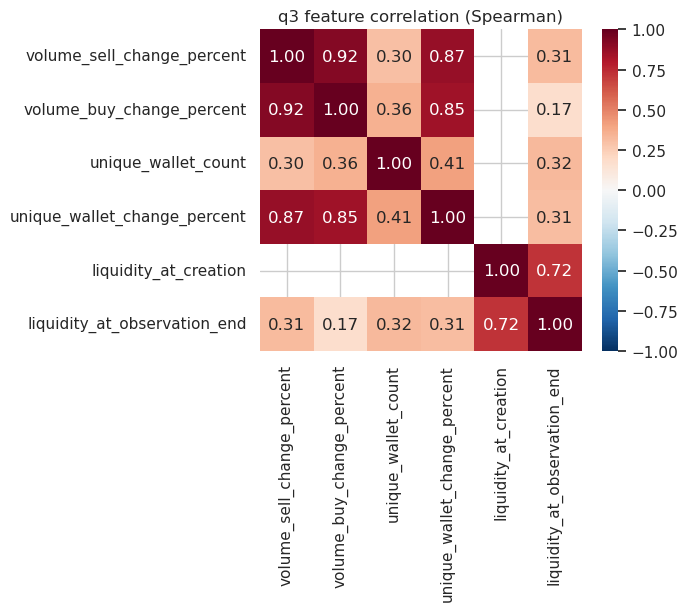


q1:
high correlation: liquidity_at_creation <-> liquidity_at_observation_end : +0.81

q2:

q3:
high correlation: volume_sell_change_percent <-> volume_buy_change_percent : +0.92
high correlation: volume_sell_change_percent <-> unique_wallet_change_percent : +0.87
high correlation: volume_buy_change_percent <-> unique_wallet_change_percent : +0.85


In [54]:
# Feature-vs-feature correlation is used as a descriptive redundancy diagnostic.
# No feature is removed in this notebook solely because of pairwise correlation.
corr_q = {
    q: nodes_q[q][FEATURES].corr(
        method='spearman',
        min_periods=30
    )
    for q in EXPERIMENTS
}

for q in EXPERIMENTS:
    fig, ax = plt.subplots(figsize=(7, 6))

    sns.heatmap(
        corr_q[q],
        cmap='RdBu_r',
        center=0,
        vmin=-1,
        vmax=1,
        annot=True,
        fmt='.2f',
        square=True,
        ax=ax
    )

    ax.set_title(f'{q} feature correlation (Spearman)')

    plt.tight_layout()
    plt.show()

# flag strongly correlated feature pairs for redundancy review in each observation window
for q in EXPERIMENTS:
    print(f'\n{q}:')
    corr_current = corr_q[q]

    for i in range(len(FEATURES)):
        for j in range(i + 1, len(FEATURES)):
            r = corr_current.iloc[i, j]

            if pd.notna(r) and abs(r) > 0.8:
                print(f'high correlation: {FEATURES[i]} <-> {FEATURES[j]} : {r:+.2f}')

**<span style="color:red">Observation:</span>** The correlation structure changes across
observation windows. q1 shows strong association between liquidity at creation and at the
observation cutoff, whereas q3 shows strong correlation among the volume-change features
and wallet-change percentage.

In q3, several correlations involving `liquidity_at_creation` are left undefined because
the pairwise number of non-missing observations is below the `min_periods=30` threshold
used for Spearman correlation. Correlations are therefore reported only where sufficient
pairwise observations are available.

The reported correlations are redundancy diagnostics only; no feature is removed solely
because of pairwise correlation, particularly given the unequal missingness patterns.

### Initial Authority Metadata

In [55]:
AUTHORITY_EDA_FEATURES = [
    'has_initial_mint_authority',
    'has_initial_freeze_authority'
]

FREEZE_AUTHORITY_ABLATION_FEATURE = 'has_initial_freeze_authority'

AUXILIARY_MODEL_FEATURES = [
    FREEZE_AUTHORITY_ABLATION_FEATURE
]

# Initial-authority indicators are retained for EDA only.
# A missing authority field cannot currently distinguish a true absent authority
# from incomplete recovery of the mint-initialization metadata.

# ============================================================
# FINAL TOKEN-LEVEL FEATURE DECISION
# ============================================================

# Preserve all six original candidate predictors for descriptive EDA
# and training-only feature-importance auditing.
FEATURE_IMPORTANCE_FEATURES = FEATURES.copy()

# Final modeling decision:
# liquidity_at_creation is excluded after considering its extreme
# missingness and negligible training-only permutation importance.
EXCLUDED_NODE_MODEL_FEATURES = [
    'liquidity_at_creation'
]

NODE_MODEL_FEATURES = [
    feature
    for feature in FEATURES
    if feature not in EXCLUDED_NODE_MODEL_FEATURES
]

assert 'liquidity_at_creation' in FEATURE_IMPORTANCE_FEATURES
assert 'liquidity_at_creation' not in NODE_MODEL_FEATURES

assert NODE_MODEL_FEATURES == [
    'volume_sell_change_percent',
    'volume_buy_change_percent',
    'unique_wallet_count',
    'unique_wallet_change_percent',
    'liquidity_at_observation_end'
]

print('Original EDA / feature-importance candidates:')
print(FEATURE_IMPORTANCE_FEATURES)

print('\nExcluded from final modeling:')
print(EXCLUDED_NODE_MODEL_FEATURES)

print('\nFinal token-level model predictors:')
print(NODE_MODEL_FEATURES)

for q in EXPERIMENTS:
    print(f'\n{q} initial-authority prevalence (%):')
    display(
        nodes_q[q]
        .groupby('rug_pull_label')[AUTHORITY_EDA_FEATURES]
        .mean()
        .mul(100)
        .rename(index={0: 'non-rug', 1: 'rug'})
        .round(1)
    )

Original EDA / feature-importance candidates:
['volume_sell_change_percent', 'volume_buy_change_percent', 'unique_wallet_count', 'unique_wallet_change_percent', 'liquidity_at_creation', 'liquidity_at_observation_end']

Excluded from final modeling:
['liquidity_at_creation']

Final token-level model predictors:
['volume_sell_change_percent', 'volume_buy_change_percent', 'unique_wallet_count', 'unique_wallet_change_percent', 'liquidity_at_observation_end']

q1 initial-authority prevalence (%):


,has_initial_mint_authority,has_initial_freeze_authority
rug_pull_label,,
non-rug,99.9,35.1
rug,99.9,53.6



q2 initial-authority prevalence (%):


,has_initial_mint_authority,has_initial_freeze_authority
rug_pull_label,,
non-rug,99.9,34.3
rug,100.0,53.8



q3 initial-authority prevalence (%):


,has_initial_mint_authority,has_initial_freeze_authority
rug_pull_label,,
non-rug,99.9,33.8
rug,100.0,53.4


**<span style="color:red">Observation:</span>** `has_initial_mint_authority` is nearly
constant in the cleaned data, whereas `has_initial_freeze_authority` shows greater class
separation. These indicators describe initial authorities parsed from the selected
mint-creation transaction, not the token's later query-time authority state. Because an
empty authority field cannot currently distinguish a genuinely absent authority from
incomplete recovery of initialization metadata, both authority indicators are retained
for EDA only and excluded from `NODE_MODEL_FEATURES`.

### Creator Metadata

In [56]:
for q in EXPERIMENTS:
    creator_values = nodes_q[q]['creators'].fillna('').astype(str).str.strip()

    empty_creator_metadata = creator_values.isin(['', '[]'])

    print(
        q,
        'empty creator metadata % =',
        round(empty_creator_metadata.mean() * 100, 1),
        '| unique non-empty creator values =',
        creator_values[~empty_creator_metadata].nunique()
    )

q1 empty creator metadata % = 0.1 | unique non-empty creator values = 1932
q2 empty creator metadata % = 0.1 | unique non-empty creator values = 1780
q3 empty creator metadata % = 0.1 | unique non-empty creator values = 1558


**<span style="color:red">Observation:</span>** In this dataset, `creators` denotes
non-mint signer accounts recovered from the selected mint-creation transaction; it is not
Metaplex creator metadata. An empty list (`[]`) should therefore be interpreted as empty
recovered creator-side metadata, not necessarily as proof that no creator account existed.
The field is also high-cardinality, so raw creator identity is intentionally excluded from
`NODE_MODEL_FEATURES` to avoid address memorization.

### Feature-Selection and Missing-Data Boundary

No model-based feature importance or learned missing-value imputation is fitted during
the complete-data descriptive EDA above.

After the complete-data EDA and leakage audits, this notebook creates one central
chronological split. Model-based feature importance is then computed using training
data only.

`liquidity_at_creation` is retained throughout the descriptive EDA and in the
training-only feature-importance audit so that the evidence supporting its exclusion
remains visible. It is excluded only from the final model-ready predictor registry.

This decision reflects the combination of extremely limited feature availability
(approximately 94--97% missing across q1/q2/q3) and negligible training-only
permutation importance across all three observation windows. The feature is therefore
not carried into final model training or missing-data preprocessing.

The two final missing-data representations, `raw_nan` and `median_indicator`, are
constructed using the remaining five token-level predictors. The median imputer is
fitted on training predictors only and applied unchanged to validation and test data.

## Step 4 — Graph features

Within each observation-window dataset, one graph-feature row is constructed for each token with at least one recovered edge.
These summaries describe the recovered transfer graph and provide both diagnostic graph statistics and
candidate classical baseline features.

Graph endpoints are resolved owner addresses when owner metadata is available; otherwise the
underlying token-account address is retained. Therefore, `n_endpoints`, `n_senders`, and
`n_receivers` count recovered graph endpoints and should not be interpreted as pure wallet
counts.

Only features listed in `GRAPH_MODEL_FEATURES` are retained as candidate modelling
predictors. Transfer amounts are now recovered with explicit provenance. For resolved edges,
`amount_raw` preserves the exact SPL base-unit integer, `decimals` records the mint
precision, and `amount_token = amount_raw / 10^decimals` provides the canonical
decimal-normalized token quantity. Exact consistency is verified before downstream use.

Absolute normalized token quantities are retained for descriptive analysis but are not
included in the primary graph-model predictor set. Decimal normalization resolves the
raw-base-unit inconsistency but does not make token quantities economically comparable
across different token mints, which may differ substantially in supply and market value.
A cross-token economic amount feature would require cutoff-safe supply normalization or
historical price information available at or before the transfer time.

`top_sender_share` is scale-invariant within a token graph and is retained for
amount-aware analysis, but the primary graph-summary baseline remains restricted to
topology and timing features for comparability with the original experiment.

In [57]:
def graph_features(edges_df):
    """Per-token summary of the recovered transfer graph."""

    g = edges_df.groupby('token_mint')

    # ------------------------------------------------------------
    # Structural / timing features
    # ------------------------------------------------------------

    out = g.agg(
        n_transfers=('tx_signature', 'size'),
        n_senders=('source_address', 'nunique'),
        n_receivers=('target_address', 'nunique'),
        first_t_frac=('t_frac', 'min'),
        mean_t_frac=('t_frac', 'mean'),
    )

    # ------------------------------------------------------------
    # Endpoint statistics
    # ------------------------------------------------------------

    endpoints = pd.concat(
        [
            edges_df[
                ['token_mint', 'source_address']
            ].rename(
                columns={
                    'source_address': 'endpoint'
                }
            ),
            edges_df[
                ['token_mint', 'target_address']
            ].rename(
                columns={
                    'target_address': 'endpoint'
                }
            ),
        ],
        ignore_index=True
    )

    out['n_endpoints'] = endpoints.groupby('token_mint').endpoint.nunique()

    # Distinct directed endpoint pairs.
    pairs = (
        edges_df
        .groupby(
            [
                'token_mint',
                'source_address',
                'target_address'
            ]
        )
        .size()
    )

    out['n_edges'] = pairs.groupby('token_mint').size()

    out['density'] = out['n_edges'] / (out['n_endpoints'] * (out['n_endpoints'] - 1))

    out.loc[out['n_endpoints'] < 2, 'density'] = np.nan

    # Average total degree in the simple directed graph.
    out['avg_degree'] = 2 * out['n_edges'] / out['n_endpoints']

    # ------------------------------------------------------------
    # Amount-resolution coverage
    # ------------------------------------------------------------

    amount_coverage = g.agg(
        n_amount_resolved=(
            'amount_resolved',
            'sum'
        ),
        n_amount_edges=(
            'amount_resolved',
            'size'
        )
    )

    amount_coverage['n_amount_unresolved'] = amount_coverage['n_amount_edges'] - amount_coverage['n_amount_resolved']

    amount_coverage['amount_resolution_rate'] = amount_coverage['n_amount_resolved'] / amount_coverage['n_amount_edges']

    amount_coverage['amount_all_resolved'] = amount_coverage['n_amount_unresolved'] == 0

    out = out.join(
        amount_coverage[
            [
                'n_amount_resolved',
                'n_amount_unresolved',
                'amount_resolution_rate',
                'amount_all_resolved'
            ]
        ]
    )

    # ------------------------------------------------------------
    # Canonical normalized amount features
    #
    # Only compute graph-level amount summaries when ALL edge
    # amounts in that graph are resolved. Otherwise the aggregate
    # would represent an incomplete graph total.
    # ------------------------------------------------------------

    fully_resolved_edges = edges_df[
        edges_df.groupby(
            'token_mint'
        )['amount_resolved']
        .transform('all')
    ].copy()

    if len(fully_resolved_edges):

        amount_group = fully_resolved_edges.groupby('token_mint')

        amount_stats = amount_group.agg(
            amount_token_sum=(
                'amount_token',
                'sum'
            ),
            amount_token_median=(
                'amount_token',
                'median'
            ),
            amount_token_max=(
                'amount_token',
                'max'
            ),
        )

        # Log-transform AFTER aggregation so the graph-level
        # feature corresponds to total/median/max transfer
        # magnitude in canonical token units.
        amount_stats['log1p_amount_token_sum'] = np.log1p(amount_stats['amount_token_sum'])

        amount_stats['log1p_amount_token_median'] = np.log1p(amount_stats['amount_token_median'])

        amount_stats['log1p_amount_token_max'] = np.log1p(amount_stats['amount_token_max'])

        # --------------------------------------------------------
        # Sender concentration in normalized token units
        # --------------------------------------------------------

        sent = (
            fully_resolved_edges
            .groupby(
                [
                    'token_mint',
                    'source_address'
                ]
            )['amount_token']
            .sum()
        )

        top_sent = sent.groupby('token_mint').max()

        total_sent = sent.groupby('token_mint').sum().replace(0, np.nan)

        amount_stats['top_sender_share'] = top_sent / total_sent

        out = out.join(amount_stats)

    else:

        for col in [
            'amount_token_sum',
            'amount_token_median',
            'amount_token_max',
            'log1p_amount_token_sum',
            'log1p_amount_token_median',
            'log1p_amount_token_max',
            'top_sender_share'
        ]:
            out[col] = np.nan

    return out.reset_index()

In [58]:
gfeat = {}

for q in EXPERIMENTS:
    gf = graph_features(edges_q[q])

    gfeat[q] = gf.merge(
        edge_present[q][
            [
                'lp_address',
                'token_mint',
                'creation_time',
                'rug_pull_label'
            ]
        ],
        on='token_mint',
        how='inner',
        validate='one_to_one'
    )

    print(f'{q}: {gfeat[q].shape[0]} tokens x {gfeat[q].shape[1]} columns')

gfeat['q1'].head()

q1: 911 tokens x 24 columns


q2: 955 tokens x 24 columns


q3: 888 tokens x 24 columns


,token_mint,n_transfers,n_senders,n_receivers,first_t_frac,mean_t_frac,n_endpoints,n_edges,density,avg_degree,n_amount_resolved,n_amount_unresolved,amount_resolution_rate,amount_all_resolved,amount_token_sum,amount_token_median,amount_token_max,log1p_amount_token_sum,log1p_amount_token_median,log1p_amount_token_max,top_sender_share,lp_address,creation_time,rug_pull_label
0,1254YT9pX4kaczmZi22TF83aAPQ24vyDdoybqPU4pump,733,82,579,0.000000,0.524007,579,655,0.001957,2.262522,733,0,1.0,True,1900955186.131446,277954.297531,206900000.0,21.365622,12.535216,19.147746,0.571962,CNSj2UWgELew8R6gsssotqRuJj6NGwVNQDvbosaVcW9n,1719709095,0
1,12nXVvvFYkgNt5P7dJcpZnJkk5wU8T34j5FhKx3JqJU6,310,4,308,0.374667,0.553200,309,309,0.003247,2.000000,310,0,1.0,True,203790062.997281,121883.761544,100000000.0,19.132601,11.710831,18.420681,0.509299,947npHb53cNCTz4aFdnJ5AHUzTTPtFZZNn5rQzsXzhnd,1721148587,1
2,14wsLiQvpaV5LRibdE54JUVfLh7gzjWEkQwvYXgpump,697,105,574,0.000000,0.406984,574,640,0.001946,2.229965,697,0,1.0,True,2929526656.057302,935646.729366,206900000.0,21.798107,13.748994,19.147746,0.37112,5FVid8k1YuXsJkfGxmu5iT9dyVcCSdsag9xoiS1Li736,1728332857,1
3,1A3CZ3b8f878LfqpT3stoiDC7C1EDMjda6A1xHakkMF,847,96,657,0.736000,0.832324,658,746,0.001726,2.267477,847,0,1.0,True,2914814588.123466,66503.371031,1000000000.0,21.793072,11.105023,20.723266,0.373416,6Xmm3zYK2FTMRXQyQes3EoTfp8oGvTp5KrEBDF58dhAC,1711926888,0
4,21pn2YfW4tqWJppH7x7me2N9gPaKJHtWYPdyW4Y6pump,34,6,26,0.000000,0.708000,26,29,0.044615,2.230769,34,0,1.0,True,706881464.652955,14829395.280168,153285714.285714,20.376374,16.512122,18.847814,0.860385,72Bo6fDLr7NkTtkiWeF7Xk189YTuHE6aTzUcWmJg5RXF,1718067600,0


In [59]:
# Graph-feature AUCs are descriptive univariate associations computed on
# all cleaned samples with at least one recovered edge.
# They are NOT used for final feature selection.

GRAPH_FEATURES = [
    # Structural / timing features
    'n_transfers',
    'n_endpoints',
    'n_edges',
    'n_senders',
    'n_receivers',
    'density',
    'avg_degree',
    'first_t_frac',
    'mean_t_frac',

    # Amount-derived descriptive features
    'top_sender_share',
    'amount_token_sum',
    'amount_token_median',
    'amount_token_max',
    'log1p_amount_token_sum',
    'log1p_amount_token_median',
    'log1p_amount_token_max',
]

# These columns are useful for amount-related EDA, but they are not
# included in the primary graph-model predictor set.
#
# Decimal normalization fixes the raw-base-unit inconsistency, but
# absolute token quantities are still not economically comparable
# across different token mints without supply normalization or a
# cutoff-safe historical price conversion.
#
# top_sender_share is scale-invariant, but it is kept out of the
# primary structural/timing baseline so that the original baseline
# definition remains unchanged. It can later be evaluated in an
# explicit amount-aware ablation.
GRAPH_DIAGNOSTIC_ONLY = [
    'top_sender_share',
    'amount_token_sum',
    'amount_token_median',
    'amount_token_max',
    'log1p_amount_token_sum',
    'log1p_amount_token_median',
    'log1p_amount_token_max',
]

# Primary graph-summary baseline:
# topology + timing only.
GRAPH_MODEL_FEATURES = [
    'n_transfers',
    'n_endpoints',
    'n_edges',
    'n_senders',
    'n_receivers',
    'density',
    'avg_degree',
    'first_t_frac',
    'mean_t_frac',
]

# Data-quality / provenance columns.
# These are audit metadata, never model predictors.
GRAPH_QUALITY_COLUMNS = [
    'n_amount_resolved',
    'n_amount_unresolved',
    'amount_resolution_rate',
    'amount_all_resolved',
]

graph_auc = pd.DataFrame({
    q: {
        c: feature_auc(gfeat[q], c)
        for c in GRAPH_FEATURES
    }
    for q in EXPERIMENTS
})

graph_n = pd.DataFrame({
    q: {
        c: gfeat[q][[c, 'rug_pull_label']]
        .dropna()
        .shape[0]
        for c in GRAPH_FEATURES
    }
    for q in EXPERIMENTS
})

pd.concat(
    {
        'auc': graph_auc.round(3),
        'n': graph_n
    },
    axis=1
)

auc                  n          
                              q1     q2     q3   q1   q2   q3
n_transfers                0.581  0.549  0.543  911  955  888
n_endpoints                0.637  0.605  0.587  911  955  888
n_edges                    0.612  0.578  0.570  911  955  888
n_senders                  0.425  0.423  0.445  911  955  888
n_receivers                0.636  0.605  0.587  911  955  888
density                    0.342  0.376  0.395  911  955  888
avg_degree                 0.369  0.361  0.380  911  955  888
first_t_frac               0.624  0.570  0.528  911  955  888
mean_t_frac                0.502  0.411  0.388  911  955  888
top_sender_share           0.437  0.469  0.441  910  953  883
amount_token_sum           0.548  0.500  0.488  910  953  883
amount_token_median        0.398  0.418  0.436  910  953  883
amount_token_max           0.663  0.617  0.587  910  953  883
log1p_amount_token_sum     0.548  0.500  0.488  910  953  883
log1p_amount_token_median  0.398  0.418  0.436  910  953  883
log1p_amount_token_max     0.663  0.617  0.587  910  953  883

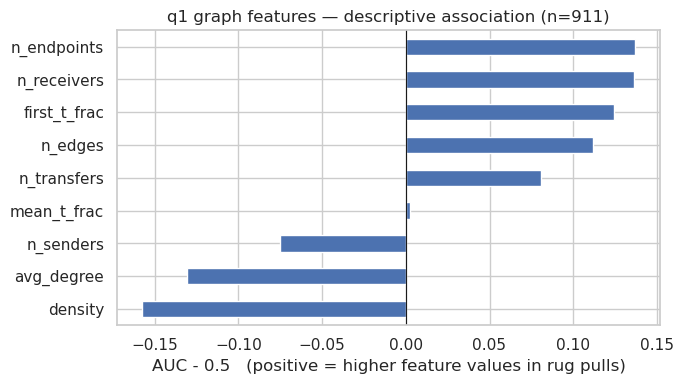

In [60]:
# Descriptive graph-feature association for q1.
# This plot is EDA only and is not used to select the final feature set.

fig, ax = plt.subplots(figsize=(7, 4))

(graph_auc.loc[GRAPH_MODEL_FEATURES, 'q1'] - 0.5).sort_values().plot(kind='barh', ax=ax, color='#4c72b0')

ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('AUC - 0.5   (positive = higher feature values in rug pulls)')
ax.set_title(f'q1 graph features — descriptive association (n={len(gfeat["q1"])})')

plt.tight_layout()
plt.show()

**<span style="color:red">Observation:</span>** Within q1 samples that contain at least
one recovered edge, the figure summarizes the univariate rank association between each
candidate graph feature and the rug-pull label. An AUC above 0.5 indicates that larger
feature values tend to occur for rug-pull samples, whereas an AUC below 0.5 indicates
the opposite direction.

This analysis is descriptive only. It is not used to select the final graph predictors,
because it is computed on the complete cleaned q1 graph subset rather than on the
training partition created later in this notebook. Training-only model-based feature
importance is computed only after the central chronological split has been fixed.

Recovered-edge presence is also class-dependent, and the recovered graphs are partial
mint-visible representations, so these associations are conditional on the non-empty
recovered-graph subset.

## Step 5 — Gephi Network Visualization Export

The publication-oriented network visualization is derived from the complete cleaned
recovered transfer network.

Each node represents a recovered transfer endpoint address. For visualization only,
endpoints with full-network structural degree below 5 are excluded, where structural
degree is computed from distinct undirected endpoint pairs. The resulting visualization
uses the induced network among the retained endpoints.

All original recovered edge rows between retained endpoints are preserved before
visualization aggregation. Repeated rows between the same ordered `source_address` →
`target_address` pair are then represented in Gephi as one directed weighted edge, where
the edge weight equals the number of retained recovered rows for that ordered pair.
Therefore, edge multiplicity is preserved exactly while avoiding parallel-edge rendering
and memory limitations in Gephi.

This aggregation affects only the visualization representation; the underlying recovered
edge dataset and model-ready graph artifacts remain unaggregated.

Transfer amount is intentionally not used as the Gephi visualization weight. Although
canonical decimal-normalized amounts are now available for resolved edges, this
visualization is designed to show recovered transfer multiplicity and topology rather
than economic transfer magnitude. Edge weight therefore remains the number of retained
recovered transfer rows for each ordered endpoint pair.

In [61]:
# ============================================================
# FINAL GEPHI VISUALIZATION EXPORT
# DEGREE >= 5, WEIGHTED ONLY FOR VISUALIZATION
# ============================================================

os.makedirs('./artifacts_stratified/gephi', exist_ok=True)

MIN_VISUALIZATION_DEGREE = 5

# ------------------------------------------------------------
# 1. Complete cleaned recovered edge rows
# ------------------------------------------------------------

viz_rows = (
    edges[
        ['source_address', 'target_address']
    ]
    .copy()
)

assert viz_rows['source_address'].notna().all()
assert viz_rows['target_address'].notna().all()

viz_rows['source_address'] = viz_rows['source_address'].astype(str)
viz_rows['target_address'] = viz_rows['target_address'].astype(str)

original_edge_rows = len(viz_rows)


# ------------------------------------------------------------
# 2. Full-network structural degree
#
# Degree filtering is based on distinct undirected endpoint
# pairs, not repeated recovered rows.
# ------------------------------------------------------------

pairs = (
    viz_rows[
        ['source_address', 'target_address']
    ]
    .drop_duplicates()
    .copy()
)

pairs['u'] = pairs[
    ['source_address', 'target_address']
].min(axis=1)

pairs['v'] = pairs[
    ['source_address', 'target_address']
].max(axis=1)

undirected_pairs = pairs[['u', 'v']].drop_duplicates()

full_structural_degree = (
    pd.concat(
        [
            undirected_pairs['u'],
            undirected_pairs['v']
        ],
        ignore_index=True
    )
    .value_counts()
)

retained_nodes = set(
    full_structural_degree[
        full_structural_degree >= MIN_VISUALIZATION_DEGREE
    ].index
)


# ------------------------------------------------------------
# 3. Induced visualization network
#
# Keep EVERY original recovered row whose two endpoints both
# survive the degree filter.
# ------------------------------------------------------------

retained_rows = (
    viz_rows[
        viz_rows['source_address'].isin(retained_nodes)
        &
        viz_rows['target_address'].isin(retained_nodes)
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Nodes actually present in the induced network
# ------------------------------------------------------------

visible_nodes = (
    pd.concat(
        [
            retained_rows['source_address'],
            retained_rows['target_address']
        ],
        ignore_index=True
    )
    .drop_duplicates()
    .reset_index(drop=True)
)

gephi_nodes = pd.DataFrame({'Id': visible_nodes})

gephi_nodes['Label'] = gephi_nodes['Id']

gephi_nodes['full_structural_degree'] = gephi_nodes['Id'].map(full_structural_degree).astype('int64')

out_rows = retained_rows['source_address'].value_counts()
in_rows = retained_rows['target_address'].value_counts()

gephi_nodes['recovered_out_rows'] = gephi_nodes['Id'].map(out_rows).fillna(0).astype('int64')
gephi_nodes['recovered_in_rows'] = gephi_nodes['Id'].map(in_rows).fillna(0).astype('int64')
gephi_nodes['recovered_total_rows'] = gephi_nodes['recovered_out_rows'] + gephi_nodes['recovered_in_rows']


# ------------------------------------------------------------
# 5. Weighted Gephi representation
#
# Aggregation is ONLY for visualization.
# Weight = retained recovered-row multiplicity for the ordered
# Source -> Target pair.
# ------------------------------------------------------------

gephi_weighted_edges = (
    retained_rows
    .groupby(
        ['source_address', 'target_address'],
        as_index=False,
        sort=False
    )
    .size()
    .rename(
        columns={
            'source_address': 'Source',
            'target_address': 'Target',
            'size': 'Weight'
        }
    )
)

gephi_weighted_edges['Type'] = 'Directed'


# ------------------------------------------------------------
# 6. Audits
# ------------------------------------------------------------

assert gephi_nodes['Id'].is_unique

assert gephi_nodes['full_structural_degree'].ge(MIN_VISUALIZATION_DEGREE).all()

assert gephi_weighted_edges['Weight'].sum() == len(retained_rows)

assert set(gephi_weighted_edges['Source']).issubset(set(gephi_nodes['Id']))

assert set(gephi_weighted_edges['Target']).issubset(set(gephi_nodes['Id']))


print('FINAL GEPHI VISUALIZATION EXPORT')
print('--------------------------------')

print(f'Original recovered edge rows: {original_edge_rows:,}')
print(f'Nodes with full-network structural degree >= {MIN_VISUALIZATION_DEGREE}: {len(retained_nodes):,}')
print(f'Retained visualization nodes: {len(gephi_nodes):,}')
print(f'Retained recovered edge rows: {len(retained_rows):,}')
print(f'Weighted directed visualization edges: {len(gephi_weighted_edges):,}')
print(f'Sum of visualization edge weights: {gephi_weighted_edges["Weight"].sum():,}')
print('Raw recovered dataset modified:', False)


# ------------------------------------------------------------
# 7. Save
# ------------------------------------------------------------

nodes_path = ('./artifacts_stratified/gephi/gephi_degree5_weighted_nodes.csv')

edges_path = ('./artifacts_stratified/gephi/gephi_degree5_weighted_edges.csv')

gephi_nodes.to_csv(nodes_path, index=False)

gephi_weighted_edges.to_csv(edges_path, index=False)

print('\nSaved:')
print(nodes_path)
print(edges_path)

FINAL GEPHI VISUALIZATION EXPORT
--------------------------------
Original recovered edge rows: 2,862,579
Nodes with full-network structural degree >= 5: 8,298
Retained visualization nodes: 8,026
Retained recovered edge rows: 377,308
Weighted directed visualization edges: 57,878
Sum of visualization edge weights: 377,308
Raw recovered dataset modified: False

Saved:
./artifacts_stratified/gephi/gephi_degree5_weighted_nodes.csv
./artifacts_stratified/gephi/gephi_degree5_weighted_edges.csv


## Step 6 — Full Recovered Transfer Multigraph Example

The visualization below shows one token-window sample as a full recovered directed
transfer multigraph. Every retained recovered transfer row is drawn individually.

No node filtering, edge aggregation, or topology simplification is
used in the figure itself. If multiple retained transfers occur between the same ordered
pair of endpoints, they are drawn as separate directed edges rather than being collapsed
into a single edge.

Each node is a recovered transfer endpoint. The figure should still be interpreted as a
partial mint-visible recovered transfer graph, not as a complete history of all token
transfers on-chain. The graph is complete only with respect to the retained recovered
edge rows for the selected token-window sample.

In [62]:
def build_recovered_multigraph(edges_df, token_mint):
    """
    Build a full recovered transfer multigraph for one token-window sample.

    Every retained recovered transfer row is kept as a separate directed edge.
    No aggregation across repeated source-target pairs is performed.
    """
    sub = edges_df[edges_df['token_mint'] == token_mint].copy().reset_index(drop=True)

    G = nx.MultiDiGraph()

    for row_id, row in sub.iterrows():
        G.add_edge(
            row['source_address'],
            row['target_address'],
            key=row_id,
            tx_signature=row['tx_signature'],

            # Historical value retained only for provenance.
            original_amount=row['original_amount'],

            # Canonical normalized amount fields.
            amount_raw=row['amount_raw'],
            decimals=row['decimals'],
            amount_token=row['amount_token'],
            amount_resolved=bool(row['amount_resolved']),

            t_frac=row['t_frac'],
            observation_start=row['observation_start'],
            observation_end=row['observation_end']
        )

    return G, sub

In [63]:
def graph_structure_diagnostics(edges_df, graph_feature_df):
    """
    Structural diagnostics of the simple directed topology induced by the
    retained recovered edge rows.

    Repeated source-target rows are collapsed only for these topology
    diagnostics. The original recovered multigraph is not modified.
    """

    model_tokens = set(graph_feature_df['token_mint'])

    label_lookup = (graph_feature_df.set_index('token_mint')['rug_pull_label'].to_dict())

    # Structural diagnostics depend only on distinct directed endpoint pairs.
    # Deduplicate once globally instead of rescanning the full edge table
    # separately for every token.
    pair_rows = (
        edges_df.loc[
            edges_df['token_mint'].isin(model_tokens),
            [
                'token_mint',
                'source_address',
                'target_address'
            ]
        ]
        .drop_duplicates()
    )

    rows = []
    seen_tokens = set()

    for token, sub in pair_rows.groupby('token_mint', sort=False):
        seen_tokens.add(token)

        G = nx.from_pandas_edgelist(
            sub,
            source='source_address',
            target='target_address',
            create_using=nx.DiGraph()
        )

        n_nodes = G.number_of_nodes()
        n_edges = G.number_of_edges()

        assert n_nodes > 0
        assert n_edges > 0

        distinct_neighbor_counts = np.array(
            [
                len(
                    set(G.predecessors(node))
                    | set(G.successors(node))
                )
                for node in G.nodes()
            ],
            dtype=float
        )

        topological_leaf_fraction = (
            (distinct_neighbor_counts == 1).mean()
            if n_nodes > 1
            else np.nan
        )

        multi_neighbor_fraction = (
            (distinct_neighbor_counts >= 2).mean()
            if n_nodes > 0
            else np.nan
        )

        max_distinct_neighbors = (
            distinct_neighbor_counts.max()
            if n_nodes > 0
            else np.nan
        )

        distinct_neighbor_dominance = (
            max_distinct_neighbors / (n_nodes - 1)
            if n_nodes > 1
            else np.nan
        )

        U = G.to_undirected()

        n_components = nx.number_connected_components(U)

        reciprocity = nx.reciprocity(G)

        rows.append(
            {
                'token_mint': token,
                'rug_pull_label': label_lookup[token],
                'n_endpoints': n_nodes,
                'n_edges': n_edges,
                'n_components': n_components,
                'max_distinct_neighbors': max_distinct_neighbors,
                'topological_leaf_fraction': topological_leaf_fraction,
                'distinct_neighbor_dominance': distinct_neighbor_dominance,
                'multi_neighbor_fraction': multi_neighbor_fraction,
                'reciprocity': reciprocity
            }
        )

    missing_tokens = model_tokens - seen_tokens

    assert not missing_tokens, (f'Graph-feature tokens missing from structural diagnostics: {len(missing_tokens)}')

    result = (
        pd.DataFrame(rows)
        .sort_values(
            'token_mint',
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    assert len(result) == len(graph_feature_df)

    return result

In [64]:
structure_by_q = {
    q: graph_structure_diagnostics(
        edges_q[q],
        gfeat[q]
    )
    for q in EXPERIMENTS
}

structural_summary = pd.DataFrame({
    q: {
        'recovered graphs':
            len(structure_by_q[q]),

        'median topological leaf fraction':
            structure_by_q[q]['topological_leaf_fraction'].median(),

        'median distinct-neighbor dominance':
            structure_by_q[q]['distinct_neighbor_dominance'].median(),

        'median reciprocity':
            structure_by_q[q]['reciprocity'].median()
    }
    for q in EXPERIMENTS
}).T

display(structural_summary.round(3))

,recovered graphs,median topological leaf fraction,median distinct-neighbor dominance,median reciprocity
q1,911.0,0.953,0.990,0.019
q2,955.0,0.927,0.975,0.035
q3,888.0,0.888,0.937,0.063


**<span style="color:red">Observation:</span>** The structural summary above characterizes
the recovered non-empty graphs at each observation window. The statistics are descriptive
properties of the partial recovered graphs and should not be interpreted as complete
token-wide network statistics.

The example selected below is intentionally chosen for readability and structural richness,
not because it is representative of either outcome class.

In [65]:
VIS_Q = 'q3'

visual_candidates = structure_by_q[VIS_Q].copy()

visual_candidates = visual_candidates[
    (visual_candidates['n_components'] == 1)
    &
    (visual_candidates['n_endpoints'].between(50, 200))
].copy()

assert not visual_candidates.empty

leaf_cut = visual_candidates['topological_leaf_fraction'].quantile(0.25)

dominance_cut = visual_candidates['distinct_neighbor_dominance'].quantile(0.25)

multi_neighbor_cut = visual_candidates['multi_neighbor_fraction'].quantile(0.75)

rich_candidates = visual_candidates[
    (visual_candidates['topological_leaf_fraction'] <= leaf_cut)
    &
    (visual_candidates['distinct_neighbor_dominance'] <= dominance_cut)
    &
    (visual_candidates['multi_neighbor_fraction'] >= multi_neighbor_cut)
].copy()

if rich_candidates.empty:
    rich_candidates = visual_candidates.copy()

selected_graph_row = (
    rich_candidates
    .sort_values(
        [
            'n_edges',
            'n_endpoints',
            'token_mint'
        ],
        ascending=[
            False,
            False,
            True
        ]
    )
    .iloc[0]
)

display(
    selected_graph_row[
        [
            'token_mint',
            'n_endpoints',
            'n_edges',
            'n_components',
            'topological_leaf_fraction',
            'multi_neighbor_fraction',
            'distinct_neighbor_dominance',
            'reciprocity'
        ]
    ]
    .to_frame('value')
)

,value
token_mint,HSwR3tZuxQKq8ddz9YxR4BX65Znm6MNdWGURw3x5FJQi
n_endpoints,191
n_edges,246
n_components,1
topological_leaf_fraction,0.696335
multi_neighbor_fraction,0.303665
distinct_neighbor_dominance,0.810526
reciprocity,0.00813


In [66]:
selected_token = selected_graph_row['token_mint']

G_selected, selected_edges = build_recovered_multigraph(edges_q[VIS_Q], selected_token)

distinct_directed_pairs = selected_edges[['source_address', 'target_address']].drop_duplicates().shape[0]

print('Observation window:', VIS_Q)
print('Token mint:', selected_token)
print('Retained recovered transfer rows:', G_selected.number_of_edges())
print('Transfer endpoints:', G_selected.number_of_nodes())
print('Distinct directed endpoint pairs:', distinct_directed_pairs)

Observation window: q3
Token mint: HSwR3tZuxQKq8ddz9YxR4BX65Znm6MNdWGURw3x5FJQi
Retained recovered transfer rows: 296
Transfer endpoints: 191
Distinct directed endpoint pairs: 246


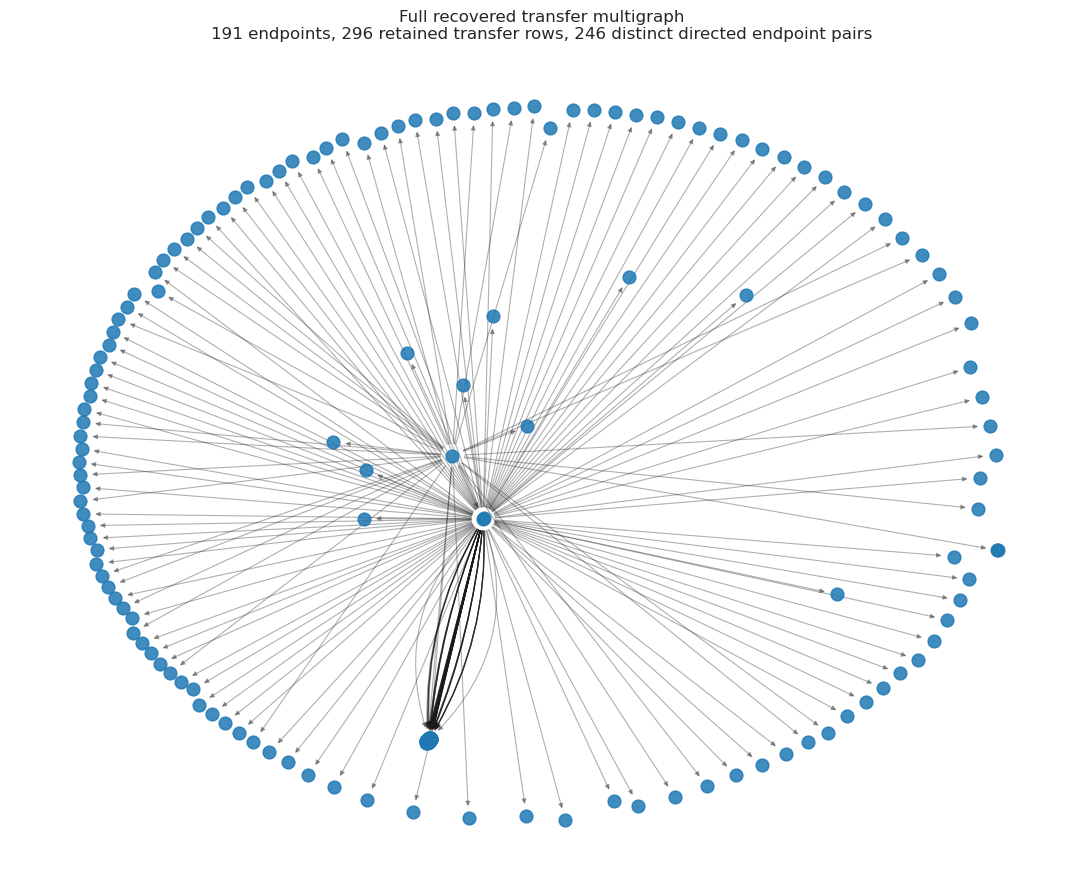

In [67]:
os.makedirs('./artifacts_stratified/figures', exist_ok=True)

pos = nx.spring_layout(
    G_selected,
    seed=42,
    iterations=1000
)

fig, ax = plt.subplots(figsize=(11, 9))

# Draw all nodes with one style only.
nx.draw_networkx_nodes(
    G_selected,
    pos,
    node_size=85,
    node_shape='o',
    alpha=0.85,
    ax=ax
)

# Draw every retained transfer row separately.
# If multiple transfers exist between the same ordered pair,
# assign different curvatures so that they remain individually visible.
pair_to_keys = {}

for u, v, k in G_selected.edges(keys=True):
    pair_to_keys.setdefault((u, v), []).append(k)

for (u, v), keys in pair_to_keys.items():
    m = len(keys)

    if m == 1:
        radii = [0.0]
    else:
        max_rad = min(0.6, 0.08 * (m - 1))
        radii = np.linspace(-max_rad, max_rad, m)

    for k, rad in zip(keys, radii):
        nx.draw_networkx_edges(
            G_selected,
            pos,
            edgelist=[(u, v, k)],
            width=0.8,
            alpha=0.35,
            arrows=True,
            arrowsize=7,
            arrowstyle='-|>',
            connectionstyle=f'arc3,rad={rad}',
            ax=ax
        )

ax.set_title(
    'Full recovered transfer multigraph\n'
    f'{G_selected.number_of_nodes()} endpoints, '
    f'{G_selected.number_of_edges()} retained transfer rows, '
    f'{distinct_directed_pairs} distinct directed endpoint pairs'
)

ax.axis('off')
plt.tight_layout()

fig.savefig('./artifacts_stratified/figures/example_recovered_transfer_multigraph.pdf', bbox_inches='tight')
fig.savefig('./artifacts_stratified/figures/example_recovered_transfer_multigraph.png', dpi=600, bbox_inches='tight')

plt.show()

**<span style="color:red">Observation:</span>** The figure shows the selected token-window
sample as a full recovered directed transfer multigraph. Every retained recovered transfer 
row is drawn as a separate directed edge, so repeated transfers between the same ordered pair of
endpoints appear as separate directed edges.

No node filtering or edge aggregation is used in the figure
itself. The layout is used only to position nodes on the page. The visualization should
therefore be interpreted as a direct view of the retained recovered edge rows for the
selected sample.

The graph is still a partial mint-visible recovered transfer graph rather than a complete
on-chain transfer history, because the edge collector starts from mint-address-based
transaction discovery.

# Leakage and Data-Validity Checks

## Step 1 — Verify Label Construction Consistency

In [68]:
valid = labels['label_status'] == 'VALID'
non_valid = ~valid

expected_windows = {
    'q1': 750,
    'q2': 2127,
    'q3': 5585
}

label_key_cols = ['lp_address', 'token_mint', 'experiment_id']
sample_key_cols = ['lp_address', 'token_mint']

sample_experiment_counts = labels.groupby(sample_key_cols)['experiment_id'].nunique()

expected_rug = labels['liquidity_drop_flag'].eq(True) & labels['price_drop_flag'].eq(True) & labels['persistent_liquidity_depletion_flag'].eq(True)
valid_rug = valid & labels['rug_pull_label'].eq(1)

In [69]:
label_checks = {}

label_checks['label key is unique'] = ~labels.duplicated(label_key_cols).any()

label_checks['only expected experiments are present'] = set(labels['experiment_id'].dropna().unique()) == set(EXPERIMENTS)

label_checks['2700 rows per experiment'] = labels.groupby('experiment_id').size().reindex(EXPERIMENTS).eq(2700).all()

label_checks['2700 unique token-LP samples'] = labels[sample_key_cols].drop_duplicates().shape[0] == 2700

label_checks['each token-LP sample has q1/q2/q3'] = sample_experiment_counts.eq(len(EXPERIMENTS)).all()

label_checks['observation end matches window'] = ((labels['observation_end_time'] - labels['token_creation_time']) == labels['observation_window_seconds']).all()

label_checks['24h outcome horizon'] = ((labels['outcome_end_time'] - labels['token_creation_time']) == 86400).all()

label_checks['q/window mapping'] = all((labels.loc[labels['experiment_id'] == q, 'observation_window_seconds'] == seconds).all()
    for q, seconds in expected_windows.items()
)

label_checks['VALID labels are binary'] = labels.loc[valid, 'rug_pull_label'].isin([0, 1]).all()

label_checks['non-VALID labels are unset'] = labels.loc[non_valid, 'rug_pull_label'].isna().all()

label_checks['VALID labels available after cutoff'] = (labels.loc[valid, 'label_available_time'] > labels.loc[valid, 'observation_end_time']).all()

label_checks['VALID labels available within outcome horizon'] = (labels.loc[valid, 'label_available_time'] <= labels.loc[valid, 'outcome_end_time']).all()

label_checks['binary label matches three-rule conjunction'] = (labels.loc[valid, 'rug_pull_label'].astype(int) == expected_rug.loc[valid].astype(int)).all()

label_checks['rug liquidity drop exceeds 80%'] = (labels.loc[valid_rug, 'liquidity_drop_ratio'] > 0.80).all()

label_checks['rug price drop exceeds 90%'] = (labels.loc[valid_rug, 'price_drop_ratio'] > 0.90).all()

label_checks['rug persistence ratio is at least 80%'] = (labels.loc[valid_rug, 'persistence_ratio'] >= 0.8).all()

label_checks['rug persistence endpoint remains below threshold'] = (labels.loc[valid_rug, 'liquidity_at_persistence_end'] <= labels.loc[valid_rug, 'persistence_liquidity_threshold']).all()

label_checks['30-minute persistence confirmation'] = (labels['persistence_confirmation_seconds'] == 1800).all()

label_checks['rug evidence is strictly after the observation window'] = all((labels.loc[valid_rug, col] > labels.loc[valid_rug, 'observation_end_time']).all()
    for col in [
        'liquidity_drop_factor_time',
        'price_drop_factor_time',
        'persistent_liquidity_depletion_factor_time'
    ]
)

label_checks['VALID rug liquidity event clears 1-minute boundary ambiguity'] = ((labels.loc[valid_rug, 'liquidity_drop_factor_time'] - 60) > labels.loc[valid_rug, 'observation_end_time']).all()

label_checks['VALID labels become available at the 24h outcome endpoint'] = (labels.loc[ valid, 'label_available_time'] == labels.loc[valid, 'outcome_end_time']).all()

for name, passed in label_checks.items():
    print(f'{"OK  " if passed else "FAIL"} {name}')

if not all(label_checks.values()):
    raise AssertionError('Label construction consistency check failed')

OK   label key is unique
OK   only expected experiments are present
OK   2700 rows per experiment
OK   2700 unique token-LP samples
OK   each token-LP sample has q1/q2/q3
OK   observation end matches window
OK   24h outcome horizon
OK   q/window mapping
OK   VALID labels are binary
OK   non-VALID labels are unset
OK   VALID labels available after cutoff
OK   VALID labels available within outcome horizon
OK   binary label matches three-rule conjunction
OK   rug liquidity drop exceeds 80%
OK   rug price drop exceeds 90%
OK   rug persistence ratio is at least 80%
OK   rug persistence endpoint remains below threshold
OK   30-minute persistence confirmation
OK   rug evidence is strictly after the observation window
OK   VALID rug liquidity event clears 1-minute boundary ambiguity
OK   VALID labels become available at the 24h outcome endpoint


## Step 2 — Check Direct Predictor/Outcome Column Overlap

In [70]:
PREDICTOR_COLUMNS = set(NODE_MODEL_FEATURES + GRAPH_MODEL_FEATURES)

LABEL_AUDIT_COLUMNS = set(labels.columns) - {
    'lp_address',
    'token_mint',
    'experiment_id',
    'observation_window_seconds'
}

leaking_predictors = sorted(PREDICTOR_COLUMNS & LABEL_AUDIT_COLUMNS)

print('predictor columns overlapping label-audit columns:', leaking_predictors)

assert not leaking_predictors, f'Potential direct leakage: {leaking_predictors}'

predictor columns overlapping label-audit columns: []


## Step 3 — Verify Label Availability After the Observation Window

In [71]:
for q in EXPERIMENTS:
    invalid = (
        nodes_q[q]['label_lead_time'].isna()
        | (nodes_q[q]['label_lead_time'] <= 0)
    )

    print(f'{q}: invalid label timing = {invalid.sum()}')

    assert invalid.sum() == 0

q1: invalid label timing = 0
q2: invalid label timing = 0
q3: invalid label timing = 0


## Step 4 — Predictor Provenance Boundary

| Predictor group | Verified collector behavior | Remaining limitation |
|---|---|---|
| Numerical token-level features | Trade records are locally restricted to the half-open `[observation_start, observation_end)` interval. Incomplete/unparseable trade histories do not produce numerical features. Liquidity at the cutoff uses a backward snapshot, and temporally distant snapshots remain missing rather than using current/post-cutoff values. | Historical API availability and missingness remain external data-quality constraints. |
| Initial authority metadata | `mint_authority` and `freeze_authority` are parsed from the selected mint-creation transaction rather than queried from later token state. | A missing field cannot currently distinguish a genuinely absent authority from incomplete recovery of initialization metadata; authority indicators are therefore EDA-only. |
| Creator metadata | `creators` contains non-mint signer accounts from the selected mint-creation transaction and is excluded from the modelling whitelist. | Empty recovered metadata does not prove that no creator-side account existed; the fallback creation transaction may also be approximate. |
| Graph topology/timing | Edge jobs use the label-defined half-open observation window, and recovered transfer timestamps are checked again during processing. | Transfer discovery begins with `getSignaturesForAddress(token_mint)`, so transfers not visible through the mint-address history may be missed. |
| Transfer amounts | Exact SPL raw amounts and mint decimals are recovered independently from the historical edge collector. For resolved edges, `amount_token = amount_raw / 10^decimals` is verified exactly before conversion to a numerical modelling representation. Amount recovery covers more than 99.999% of retained cleaned edge rows; unresolved transaction-unavailable rows remain explicitly marked and are never guessed. | Decimal normalization establishes consistent token units but does not establish cross-token economic comparability. Absolute amount summaries therefore remain diagnostic until a cutoff-safe supply-normalized or historical-price-normalized representation is available. |

The collector and amount-resolution audits support cutoff-safe construction of the
historical numerical token features, graph topology/timing features, and canonical
per-edge token quantities. The remaining limitations concern historical data
availability, graph-discovery coverage, the small number of transaction-unavailable
amount rows, and the absence of a cutoff-safe cross-token economic normalization for
absolute transfer quantities.

## Step 5 — Experimental Validity Notes

- `IN_WINDOW_EVENT` samples are excluded from supervised model-ready data because the
  rug-pull event occurs inside the observation window rather than after prediction time.

- The `full` scope is the primary dataset for each observation window. The `panel` scope is
  used only as a controlled secondary analysis with the same tokens across q1/q2/q3.

- A single central chronological train/validation/test assignment is created only after
  all complete-data EDA and leakage audits are finished. The assignment is defined once
  at the token-mint level and reused across q1/q2/q3 and across tabular and graph-model
  representations. Class labels are not used to allocate samples to partitions.

- Learned missing-data preprocessing and model-based feature importance are fitted only
  after the central chronological split has been fixed. The median imputer is fitted
  using training predictors only and is applied unchanged to validation and test data.
  Model-based feature importance is also computed using training data only. These fitted
  preprocessing objects, final data variants, and training-only importance results are
  saved by this notebook and are not recomputed downstream.

- `graph_edges.csv` contains only retained recovered-edge rows. Absence of an edge row
  does not by itself prove that the token had no transfers.

- Recovered transaction graphs represent transfer activity visible through the
  mint-address transaction history and should not be interpreted as complete token
  transaction histories.

- Token-level feature missingness is preserved throughout the complete-data EDA.
  Imputation is performed only after splitting. Incomplete trade histories do not produce
  numerical trade features, undefined percentage changes remain missing in the raw
  representation, and unavailable or temporally distant liquidity snapshots are not
  replaced with current or post-cutoff values.

- Historical transfer amounts have been re-resolved with explicit raw-unit, decimal,
  normalized-token, status, and provenance fields. Resolved edges satisfy
  `amount_token = amount_raw / 10^decimals` exactly, while unresolved transactions
  remain explicitly marked and are never imputed or guessed. Absolute normalized token
  quantities are not used as primary cross-token predictors because decimal
  normalization alone does not account for differences in token supply or market value.
  Price-based transfer values are not constructed from label-side price fields because
  those fields contain post-observation outcome information and would introduce leakage.

- One token has VALID labels for all three observation windows but no corresponding node
  rows in the current output. Missing numerical features alone do not suppress node rows
  under the collector logic, so the absence concerns the persisted node output rather
  than ordinary feature missingness.

- Recovered-edge presence is class-dependent, so the subset of samples with non-empty
  recovered graphs should not be treated as representative of the full supervised
  dataset.

- Because the edge table does not contain instruction-level event identifiers, distinct
  transfers within the same transaction that share the same source, target, and amount
  cannot always be distinguished from duplicated collection rows by the current
  deduplication key.

- Supervised evaluation is conditional on label availability. `UNKNOWN_*` outcomes are
  retained in the audit table but excluded from binary modelling.

# Final Artifact Preparation

The notebook first saves the complete cleaned, unsplit artifacts with missing predictor
values preserved.

It then creates the central chronological train/validation/test assignment, applies the
temporal embargo audit, generates both predefined missing-data representations,
computes training-only model-based feature importance, and exports the final
model-ready artifacts.

No model-development preprocessing is fitted before the chronological split.

In [72]:
os.makedirs('./artifacts_stratified', exist_ok=True)
os.makedirs('./artifacts_stratified/label_audit', exist_ok=True)
os.makedirs('./artifacts_stratified/figures', exist_ok=True)

In [73]:
sample_manifest = pd.concat(
    [
        nodes_q[q][
            [
                'lp_address',
                'token_mint',
                'creation_time',
                'observation_start',
                'observation_end',
                'label_available_time',
                'rug_pull_label',
                'has_recovered_edges'
            ]
        ]
        .assign(experiment_id=q)
        for q in EXPERIMENTS
    ],
    ignore_index=True
)

manifest_key = [
    'lp_address',
    'token_mint',
    'experiment_id'
]

assert not sample_manifest.duplicated(manifest_key).any()

assert 'split' not in sample_manifest.columns

sample_manifest.to_parquet('./artifacts_stratified/sample_manifest.parquet', index=False)

print('sample manifest rows:', len(sample_manifest))

display(
    sample_manifest
    .groupby('experiment_id')
    .agg(
        samples=('token_mint', 'size'),
        tokens=('token_mint', 'nunique'),
        rug_rate=('rug_pull_label', 'mean'),
        recovered_graphs=('has_recovered_edges', 'sum')
    )
)

sample manifest rows: 5332


,samples,tokens,rug_rate,recovered_graphs
experiment_id,,,,
q1,1961,1961,0.390107,911
q2,1798,1798,0.358732,955
q3,1573,1573,0.301335,888


In [74]:
for q in EXPERIMENTS:
    labels_q[q].to_parquet(f'./artifacts_stratified/label_audit/{q}_labels.parquet', index=False)

label_node_audit.to_parquet('./artifacts_stratified/label_node_audit.parquet', index=False)

In [75]:
nodes.to_parquet('./artifacts_stratified/cleaned_nodes.parquet', index=False)
edges.to_parquet('./artifacts_stratified/cleaned_edges.parquet', index=False)
labels.to_parquet('./artifacts_stratified/cleaned_labels.parquet', index=False)

print('Saved cleaned root tables:')
print('  cleaned_nodes.parquet')
print('  cleaned_edges.parquet')
print('  cleaned_labels.parquet')

Saved cleaned root tables:
  cleaned_nodes.parquet
  cleaned_edges.parquet
  cleaned_labels.parquet


In [76]:
feature_registry = {
    'node_model_candidates': NODE_MODEL_FEATURES,
    'graph_model_candidates': GRAPH_MODEL_FEATURES,
    'graph_diagnostic_only': GRAPH_DIAGNOSTIC_ONLY,
    'graph_quality_audit': GRAPH_QUALITY_COLUMNS,

    'edge_amount_policy': {
        'canonical_relation': (
            'amount_token = amount_raw / 10**decimals'
        ),
        'raw_amount_preserved_exactly': True,
        'unresolved_amounts_are_guessed': False,
        'absolute_token_amounts_primary_model_predictors': False,
        'reason_absolute_amounts_excluded': (
            'Decimal normalization resolves SPL base-unit scaling but does not '
            'make absolute token quantities economically comparable across '
            'different token mints.'
        ),
        'price_normalization_used': False,
        'price_normalization_reason': (
            'No cutoff-safe historical edge-time price series is available. '
            'Label-side price-drop fields are outcome information and are not '
            'used as predictors.'
        ),
        'primary_graph_model': (
            'topology_and_timing_only'
        )
    },

    'split_policy': {
        'unit': 'token_mint',
        'type': 'stratified_random',
        'target_train_fraction': 0.70,
        'target_validation_fraction': 0.15,
        'target_test_fraction': 0.15,
        'stratification_variable': 'rug_pull_label',
        'random_state': 42,
        'allocation_uses_label': True,
        'same_assignment_across_q_windows': True,
        'same_assignment_across_model_branches': True,
        'embargo_rule': None
    },

    'feature_importance_policy': (
        'Model-based feature importance is implemented and executed directly in this '
        'notebook after the central stratified split is fixed. It is computed '
        'separately for q1/q2/q3 using training rows from the raw_nan representation '
        'only. Validation and test rows do not enter estimator fitting or permutation '
        'scoring. The resulting rankings are saved as final experimental artifacts '
        'and are not recomputed downstream.'
    ),

    'missing_data_variants': {
        'raw_nan': (
            'Preserve missing predictor values without imputation.'
        ),
        'median_indicator': (
            'Median imputation fitted on training predictors only, with explicit '
            'missingness indicators. The fitted imputer is applied unchanged to '
            'validation and test data.'
        )
    },

    'missing_data_policy': (
        'Missing-data representations are generated in this notebook only after the '
        'stratified split is fixed. Labels are never used as imputation inputs.'
    )
}

with open('./artifacts_stratified/feature_registry.json', 'w', encoding='utf-8') as f:
    json.dump(feature_registry, f, indent=2)

print(json.dumps(feature_registry, indent=2))

{
  "node_model_candidates": [
    "volume_sell_change_percent",
    "volume_buy_change_percent",
    "unique_wallet_count",
    "unique_wallet_change_percent",
    "liquidity_at_observation_end"
  ],
  "graph_model_candidates": [
    "n_transfers",
    "n_endpoints",
    "n_edges",
    "n_senders",
    "n_receivers",
    "density",
    "avg_degree",
    "first_t_frac",
    "mean_t_frac"
  ],
  "graph_diagnostic_only": [
    "top_sender_share",
    "amount_token_sum",
    "amount_token_median",
    "amount_token_max",
    "log1p_amount_token_sum",
    "log1p_amount_token_median",
    "log1p_amount_token_max"
  ],
  "graph_quality_audit": [
    "n_amount_resolved",
    "n_amount_unresolved",
    "amount_resolution_rate",
    "amount_all_resolved"
  ],
  "edge_amount_policy": {
    "canonical_relation": "amount_token = amount_raw / 10**decimals",
    "raw_amount_preserved_exactly": true,
    "unresolved_amounts_are_guessed": false,
    "absolute_token_amounts_primary_model_predictors": f

In [77]:
for scope in ['full', 'panel']:

    for q in EXPERIMENTS:
        folder = f'./artifacts_stratified/{scope}/{q}'

        os.makedirs(folder, exist_ok=True)

        # Full cleaned token-level table.
        nodes_out = (
            apply_scope(nodes_q[q], scope)
            .drop(
                columns=[
                    'n_transfers',
                    'has_recovered_edges'
                ],
                errors='ignore'
            )
        )

        assert 'split' not in nodes_out.columns

        nodes_out.to_parquet(f'{folder}/nodes.parquet', index=False)

        # Restricted candidate table for tabular modelling.
        model_nodes_out = nodes_out[
            [
                'lp_address',
                'token_mint',
                'creation_time',
                'rug_pull_label'
            ]
            + NODE_MODEL_FEATURES
        ].copy()

        model_nodes_out.to_parquet(f'{folder}/model_nodes.parquet', index=False)

        # Clean recovered transfer rows for the same model-ready
        # token population represented by nodes_out.
        model_keys = nodes_out[['lp_address', 'token_mint']].drop_duplicates()

        edges_out = edges_q[q].merge(model_keys, on=['lp_address', 'token_mint'], how='inner', validate='many_to_one')

        edge_keys_out = pd.MultiIndex.from_frame(edges_out[['lp_address', 'token_mint']].drop_duplicates())

        model_keys_index = pd.MultiIndex.from_frame(model_keys)

        assert edge_keys_out.isin(model_keys_index).all()

        edges_out.to_parquet(f'{folder}/edges.parquet', index=False)

        # Graph-summary table: only samples with a non-empty
        # recovered graph are present by construction.
        graph_out = apply_scope(gfeat[q], scope)

        assert 'split' not in graph_out.columns

        graph_out.to_parquet(f'{folder}/graph_features.parquet', index=False)

        # Restricted candidate graph-summary predictors.
        model_graph_out = graph_out[
            [
                'lp_address',
                'token_mint',
                'creation_time',
                'rug_pull_label'
            ]
            + GRAPH_MODEL_FEATURES
        ].copy()

        model_graph_out.to_parquet(f'{folder}/model_graph_features.parquet', index=False)

        # Structural diagnostic table.
        structure_out = apply_scope(structure_by_q[q], scope)

        structure_out.to_parquet(f'{folder}/graph_structure.parquet', index=False)

    print(f'saved scope={scope}')

saved scope=full


saved scope=panel


# Chronological Split and Leakage-Safe Experimental Preparation

All complete-data descriptive analyses and leakage audits are complete above.

The following cells create the final model-development partitions and preprocessing
artifacts. One chronological assignment is defined at the unique token-mint level and is
reused across q1/q2/q3 and across tabular and graph-model representations.

The target proportions are 70% training, 15% validation, and 15% test. Train/validation/test boundaries are determined from creation time only and are not
stratified by the outcome label. `label_available_time` is used only for the fixed
boundary purge/embargo check; the class value itself does not affect partition
assignment.

Because the operational label uses future outcome information, samples immediately before
the validation and test periods are embargoed whenever their labels would not yet be
available when the following period begins.

In [78]:
# ============================================================
# CENTRAL STRATIFIED SPLIT
# ============================================================
#
# Replaces the chronological split with embargo. Tokens are allocated to
# train / validation / test at random, stratified on the token-level rug label,
# so every partition has the same rug prevalence. There is no time ordering and
# hence no boundary embargo: every model-ready token is assigned.

from sklearn.model_selection import train_test_split

TRAIN_TARGET = 0.70
VALIDATION_TARGET = 0.15
TEST_TARGET = 0.15

SPLIT_RANDOM_STATE = 42

assert np.isclose(TRAIN_TARGET + VALIDATION_TARGET + TEST_TARGET, 1.0)

os.makedirs('./artifacts_stratified/splits', exist_ok=True)

split_base = sample_manifest[
    [
        'token_mint',
        'creation_time',
        'label_available_time',
        'rug_pull_label'
    ]
].copy()

for col in ['creation_time', 'label_available_time']:
    split_base[col] = pd.to_numeric(split_base[col], errors='raise')

assert split_base['token_mint'].notna().all()
assert split_base['rug_pull_label'].notna().all()

# The stratification label, creation time and label availability must agree
# across q1/q2/q3 for the same token.
for col in ['creation_time', 'label_available_time', 'rug_pull_label']:
    assert (split_base.groupby('token_mint')[col].nunique() == 1).all(), col

token_split = (
    split_base
    .groupby('token_mint', as_index=False)
    .agg(
        creation_time=('creation_time', 'first'),
        label_available_time=('label_available_time', 'first'),
        rug_pull_label=('rug_pull_label', 'first')
    )
    .sort_values('token_mint', kind='mergesort')
    .reset_index(drop=True)
)

n_tokens = len(token_split)

assert n_tokens > 0

train_idx, holdout_idx = train_test_split(
    token_split.index,
    train_size=TRAIN_TARGET,
    stratify=token_split['rug_pull_label'],
    random_state=SPLIT_RANDOM_STATE,
)

validation_idx, test_idx = train_test_split(
    holdout_idx,
    test_size=TEST_TARGET / (VALIDATION_TARGET + TEST_TARGET),
    stratify=token_split.loc[holdout_idx, 'rug_pull_label'],
    random_state=SPLIT_RANDOM_STATE,
)

token_split['split'] = pd.Series(pd.NA, index=token_split.index, dtype='object')
token_split.loc[train_idx, 'split'] = 'train'
token_split.loc[validation_idx, 'split'] = 'validation'
token_split.loc[test_idx, 'split'] = 'test'

# Kept for schema compatibility with the chronological manifest; always empty.
token_split['embargo_boundary'] = pd.Series(pd.NA, index=token_split.index, dtype='object')

assert token_split['split'].notna().all()
assert not token_split['token_mint'].duplicated().any()

token_split['creation_time_utc'] = pd.to_datetime(token_split['creation_time'], unit='s', utc=True)
token_split['label_available_time_utc'] = pd.to_datetime(token_split['label_available_time'], unit='s', utc=True)

# The label is only needed for allocation; the downstream schema does not carry it.
token_split = token_split.drop(columns='rug_pull_label')

print('Unique model-ready tokens:', n_tokens)
print('Target proportions: 70% / 15% / 15% (stratified on rug_pull_label)')

display(token_split['split'].value_counts().rename_axis('split').to_frame('tokens'))


Unique model-ready tokens: 1961
Target proportions: 70% / 15% / 15% (stratified on rug_pull_label)


,tokens
split,
train,1372
test,295
validation,294


In [79]:
# ============================================================
# SPLIT AUDIT
# ============================================================

model_token_split = token_split[
    token_split['split'].isin(
        ['train', 'validation', 'test']
    )
].copy()

train_tokens = model_token_split[model_token_split['split'] == 'train']

validation_tokens = model_token_split[model_token_split['split'] == 'validation']

test_tokens = model_token_split[model_token_split['split'] == 'test']

assert len(train_tokens) > 0
assert len(validation_tokens) > 0
assert len(test_tokens) > 0

# Stratification: rug prevalence should match across partitions.
token_rug = (
    sample_manifest.groupby('token_mint')['rug_pull_label'].first()
)
partition_rug_rate = (
    model_token_split.assign(rug=model_token_split['token_mint'].map(token_rug))
    .groupby('split')['rug'].mean()
)
print('token-level rug rate by partition:')
print(partition_rug_rate.round(4).to_string())
assert partition_rug_rate.max() - partition_rug_rate.min() < 0.02


# ------------------------------------------------------------
# Attach the central assignment to all q-window samples.
# ------------------------------------------------------------

sample_manifest_with_split = sample_manifest.merge(
    token_split[
        [
            'token_mint',
            'split',
            'embargo_boundary'
        ]
    ],
    on='token_mint',
    how='left',
    validate='many_to_one'
)

assert sample_manifest_with_split['split'].notna().all()

# Same token -> same assignment everywhere.
assert sample_manifest_with_split.groupby('token_mint')['split'].nunique().max() == 1


# ------------------------------------------------------------
# Descriptive split audit.
# LABEL IS USED HERE ONLY AFTER ALLOCATION.
# ------------------------------------------------------------

split_summary = (
    sample_manifest_with_split
    .groupby(
        ['experiment_id', 'split'],
        observed=True
    )
    .agg(
        samples=('token_mint', 'size'),
        rugs=('rug_pull_label', 'sum'),
        rug_rate=('rug_pull_label', 'mean'),
        recovered_graphs=('has_recovered_edges', 'sum'),
        first_creation_time=('creation_time', 'min'),
        last_creation_time=('creation_time', 'max')
    )
    .reset_index()
)

split_summary['non_rugs'] = split_summary['samples'] - split_summary['rugs']

split_summary['rug_rate_percent'] = split_summary['rug_rate'] * 100.0

split_summary['first_creation_utc'] = pd.to_datetime(split_summary['first_creation_time'], unit='s', utc=True)

split_summary['last_creation_utc'] = pd.to_datetime(split_summary['last_creation_time'], unit='s', utc=True)

split_summary = split_summary[
    [
        'experiment_id',
        'split',
        'samples',
        'non_rugs',
        'rugs',
        'rug_rate_percent',
        'recovered_graphs',
        'first_creation_utc',
        'last_creation_utc'
    ]
]


# Ensure every non-embargo partition has both classes for every q.
for q in EXPERIMENTS:
    q_model = sample_manifest_with_split[
        (sample_manifest_with_split['experiment_id'] == q)
        & sample_manifest_with_split['split'].isin(
            ['train', 'validation', 'test']
        )
    ]

    for split_name in ['train', 'validation', 'test']:
        classes = set(
            q_model.loc[
                q_model['split'] == split_name,
                'rug_pull_label'
            ].dropna().astype(int).unique()
        )

        assert classes == {0, 1}, (f'{q}/{split_name} does not contain both classes: {classes}')


# ------------------------------------------------------------
# Save central split source of truth.
# ------------------------------------------------------------

token_split.to_parquet('./artifacts_stratified/splits/stratified_split_manifest.parquet', index=False)

token_split.to_csv('./artifacts_stratified/splits/stratified_split_manifest.csv', index=False)

sample_manifest_with_split.to_parquet('./artifacts_stratified/splits/sample_manifest_with_split.parquet', index=False)

split_summary.to_csv('./artifacts_stratified/splits/split_summary_by_experiment.csv', index=False)


split_config = {
    'unit': 'token_mint',
    'type': 'stratified_random',
    'stratification_variable': 'rug_pull_label',
    'random_state': SPLIT_RANDOM_STATE,
    'target_train_fraction': TRAIN_TARGET,
    'target_validation_fraction': VALIDATION_TARGET,
    'target_test_fraction': TEST_TARGET,
    'allocation_uses_label': True,

    'unique_tokens_total': int(n_tokens),

    'train_tokens': int((token_split['split'] == 'train').sum()),

    'validation_tokens': int((token_split['split'] == 'validation').sum()),

    'test_tokens': int((token_split['split'] == 'test').sum()),

    'embargo_tokens': int((token_split['split'] == 'embargo').sum()),
}

with open('./artifacts_stratified/splits/split_config.json', 'w', encoding='utf-8') as f:
    json.dump(split_config, f, indent=2)

print(json.dumps(split_config, indent=2))

display(split_summary)

token-level rug rate by partition:
split
test          0.3898
train         0.3899
validation    0.3912
{
  "unit": "token_mint",
  "type": "stratified_random",
  "stratification_variable": "rug_pull_label",
  "random_state": 42,
  "target_train_fraction": 0.7,
  "target_validation_fraction": 0.15,
  "target_test_fraction": 0.15,
  "allocation_uses_label": true,
  "unique_tokens_total": 1961,
  "train_tokens": 1372,
  "validation_tokens": 294,
  "test_tokens": 295,
  "embargo_tokens": 0
}


,experiment_id,split,samples,non_rugs,rugs,rug_rate_percent,recovered_graphs,first_creation_utc,last_creation_utc
0,q1,test,295,180,115,38.983051,130,2023-01-31 07:30:45+00:00,2024-10-30 11:02:58+00:00
1,q1,train,1372,837,535,38.994169,624,2022-09-15 18:05:48+00:00,2024-10-31 14:21:40+00:00
2,q1,validation,294,179,115,39.115646,157,2023-11-25 07:25:32+00:00,2024-10-31 00:21:37+00:00
3,q2,test,275,177,98,35.636364,144,2023-01-31 07:30:45+00:00,2024-10-29 16:09:39+00:00
4,q2,train,1253,803,450,35.913807,655,2022-09-15 18:05:48+00:00,2024-10-31 14:21:40+00:00
5,q2,validation,270,173,97,35.925926,156,2023-11-29 19:05:19+00:00,2024-10-31 00:21:37+00:00
6,q3,test,233,167,66,28.326180,123,2023-01-31 07:30:45+00:00,2024-10-29 16:09:39+00:00
7,q3,train,1097,767,330,30.082042,611,2022-09-15 18:05:48+00:00,2024-10-31 14:21:40+00:00
8,q3,validation,243,165,78,32.098765,154,2023-11-29 19:05:19+00:00,2024-10-31 00:21:37+00:00


**<span style="color:red">Observation:</span>** Rug-pull prevalence differs materially
across the chronological train, validation, and test partitions, particularly in the
validation interval. This reflects temporal outcome-prevalence drift in the observed
dataset. The split boundaries are not adjusted using outcome labels to equalize class
rates, because allocation is intentionally label-independent. Model evaluation should
therefore report partition-specific class prevalence and use metrics appropriate for
temporally shifted class distributions.

# Leakage-Safe Missing-Data Variants

The central split is now fixed.

Exactly two final tabular representations are created separately for q1, q2, and q3.
The raw representation preserves NaN values. Median imputation is fitted on training
predictors only and then applied unchanged to validation and test rows.

For the median-imputed representation, an explicit missingness indicator is retained
for every original predictor. The indicators are computed from the original
pre-imputation values.

The outcome label is never supplied to the imputation model.

In [80]:
# ============================================================
# MISSING-DATA PREPROCESSING HELPERS
# ============================================================

MISSING_INDICATOR_COLUMNS = [f'{col}__missing' for col in NODE_MODEL_FEATURES]

def numeric_predictors(df):
    X = df[NODE_MODEL_FEATURES].copy()

    for col in NODE_MODEL_FEATURES:
        X[col] = pd.to_numeric(X[col], errors='raise')

    infinite_cols = [
        col
        for col in NODE_MODEL_FEATURES
        if np.isinf(X[col].dropna().to_numpy(dtype=float)).any()
    ]

    if infinite_cols:
        raise ValueError(f'Infinite predictor values found in: {infinite_cols}')

    return X


def add_missing_indicators(output_df, original_X):
    result = output_df.copy()

    for col in NODE_MODEL_FEATURES:
        result[f'{col}__missing'] = original_X[col].isna().astype('int8').to_numpy()

    return result


def rebuild_imputed_dataset(base_df, transformed_X):
    id_cols = [
        'lp_address',
        'token_mint',
        'experiment_id',
        'creation_time',
        'rug_pull_label',
        'split'
    ]

    result = base_df[id_cols + AUXILIARY_MODEL_FEATURES].copy().reset_index(drop=True)

    transformed_df = pd.DataFrame(transformed_X, columns=NODE_MODEL_FEATURES)

    result = pd.concat([result, transformed_df], axis=1)

    original_X = numeric_predictors(base_df).reset_index(drop=True)

    result = add_missing_indicators(result, original_X)

    return result


def audit_imputed_variant(raw_df, processed_df, variant_name):
    assert len(raw_df) == len(processed_df)

    for col in [
        'lp_address',
        'token_mint',
        'experiment_id',
        'creation_time',
        'rug_pull_label',
        'split'
    ]:
        assert raw_df[col].reset_index(drop=True).equals(processed_df[col].reset_index(drop=True))

    for col in AUXILIARY_MODEL_FEATURES:
        assert (
            raw_df[col]
            .reset_index(drop=True)
            .equals(
                processed_df[col]
                .reset_index(drop=True)
            )
        )

    # Imputed variants must contain no predictor NaNs.
    assert not processed_df[NODE_MODEL_FEATURES].isna().any().any()

    raw_X = numeric_predictors(raw_df).reset_index(drop=True)

    # Observed values must not be changed by imputation.
    for col in NODE_MODEL_FEATURES:
        observed = raw_X[col].notna()

        np.testing.assert_allclose(
            processed_df.loc[observed, col].astype(float),
            raw_X.loc[observed, col].astype(float),
            rtol=0,
            atol=1e-12
        )

        expected_indicator = raw_X[col].isna().astype('int8').reset_index(drop=True)

        actual_indicator = processed_df[f'{col}__missing'].astype('int8').reset_index(drop=True)

        assert expected_indicator.equals(actual_indicator)

    print(f'{variant_name}: audit passed ({len(processed_df):,} rows)')

In [81]:
# ============================================================
# BUILD FINAL TABULAR DATA VARIANTS
# ============================================================

os.makedirs('./artifacts_stratified/final/full', exist_ok=True)
os.makedirs('./artifacts_stratified/preprocessing', exist_ok=True)

split_map = token_split[['token_mint', 'split']].copy()

final_tabular = {}
preprocessing_manifest = {}

for q in EXPERIMENTS:

    print(f'\n===== {q} =====')

    final_dir = f'./artifacts_stratified/final/full/{q}'
    prep_dir = f'./artifacts_stratified/preprocessing/{q}'

    os.makedirs(final_dir, exist_ok=True)
    os.makedirs(prep_dir, exist_ok=True)

    # Base candidate table.
    base = nodes_q[q][
        [
            'lp_address',
            'token_mint',
            'creation_time',
            'rug_pull_label'
        ]
        + NODE_MODEL_FEATURES
        + AUXILIARY_MODEL_FEATURES
    ].copy()

    base['experiment_id'] = q

    base = base.merge(
        split_map,
        on='token_mint',
        how='left',
        validate='one_to_one'
    )

    assert base['split'].notna().all()

    # Embargo rows remain documented in the split manifest,
    # but are excluded from final model-development datasets.
    base = (
        base[
            base['split'].isin(
                ['train', 'validation', 'test']
            )
        ]
        .sort_values(
            ['creation_time', 'token_mint'],
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    assert not base['token_mint'].duplicated().any()

    X = numeric_predictors(base)

    train_mask = base['split'] == 'train'
    validation_mask = base['split'] == 'validation'
    test_mask = base['split'] == 'test'

    X_train = X.loc[train_mask]
    X_validation = X.loc[validation_mask]
    X_test = X.loc[test_mask]

    # Every candidate must have at least one observed training value.
    all_missing_train = [
        col
        for col in NODE_MODEL_FEATURES
        if X_train[col].notna().sum() == 0
    ]

    assert not all_missing_train, (f'{q}: entirely missing training predictors: {all_missing_train}')


    # ========================================================
    # Variant 1: RAW NaN
    # ========================================================

    raw_nan = base[
        [
            'lp_address',
            'token_mint',
            'experiment_id',
            'creation_time',
            'rug_pull_label',
            'split'
        ]
        + NODE_MODEL_FEATURES
        + AUXILIARY_MODEL_FEATURES
    ].copy()

    raw_nan.to_parquet(f'{final_dir}/model_nodes_raw_nan.parquet', index=False)


    # ========================================================
    # Variant 2: TRAIN-MEDIAN + missing indicators
    # ========================================================

    median_imputer = SimpleImputer(strategy='median')

    median_imputer.fit(X_train)

    median_all = np.empty((len(X), len(NODE_MODEL_FEATURES)), dtype=float)

    median_all[train_mask.to_numpy()] = median_imputer.transform(X_train)
    median_all[validation_mask.to_numpy()] = median_imputer.transform(X_validation)
    median_all[test_mask.to_numpy()] = median_imputer.transform(X_test)

    median_indicator = rebuild_imputed_dataset(base, median_all)

    audit_imputed_variant(raw_nan, median_indicator, f'{q}/median_indicator')

    median_indicator.to_parquet(f'{final_dir}/model_nodes_median_indicator.parquet', index=False)

    joblib.dump(median_imputer, f'{prep_dir}/median_imputer.joblib')


    # Keep in memory for the rest of this notebook.
    final_tabular[q] = {
        'raw_nan': raw_nan,
        'median_indicator': median_indicator,
    }


    # Metadata for reproducibility.
    preprocessing_manifest[q] = {
        'features': NODE_MODEL_FEATURES,
        'indicator_columns': MISSING_INDICATOR_COLUMNS,

        'fit_partition': 'train_only',
        'label_used_for_imputation': False,

        'row_counts': {
            'train': int(train_mask.sum()),
            'validation': int(validation_mask.sum()),
            'test': int(test_mask.sum()),
        },

        'train_missing_percent': {
            col: float(X_train[col].isna().mean() * 100.0)
            for col in NODE_MODEL_FEATURES
        },

        'training_medians': {
            col: float(value)
            for col, value in zip(
                NODE_MODEL_FEATURES,
                median_imputer.statistics_
            )
        },
    }


with open('./artifacts_stratified/preprocessing/preprocessing_manifest.json', 'w', encoding='utf-8') as f:
    json.dump(preprocessing_manifest, f, indent=2)

print('\nBoth tabular variants saved.')


===== q1 =====
q1/median_indicator: audit passed (1,961 rows)

===== q2 =====


q2/median_indicator: audit passed (1,798 rows)

===== q3 =====


q3/median_indicator: audit passed (1,573 rows)

Both tabular variants saved.


In [82]:
# ============================================================
# MISSINGNESS-FILTERED MODEL-DATA VARIANTS
# ============================================================
#
# Three cohorts:
#
# 1) original
#       - raw_nan
#       - median_indicator
#
# 2) drop_3_or_more_missing
#       - raw_nan
#       - median_indicator
#
# 3) complete_case
#       - no missing predictors remain
#
# Missingness filtering is based ONLY on NODE_MODEL_FEATURES.
# liquidity_at_creation is already excluded from that list.
#
# The central chronological split is preserved.
# Median imputation is fitted ONLY on training rows of the
# corresponding cohort.
# ============================================================

os.makedirs('./artifacts_stratified/final/missingness_experiments', exist_ok=True)

os.makedirs('./artifacts_stratified/preprocessing/missingness_experiments', exist_ok=True)

missingness_experiments = {}
missingness_preprocessing_manifest = {}

for q in EXPERIMENTS:

    print(f'\n===== {q} =====')

    # --------------------------------------------------------
    # Same base population as the main final pipeline
    # --------------------------------------------------------

    base = nodes_q[q][
        [
            'lp_address',
            'token_mint',
            'creation_time',
            'rug_pull_label'
        ]
        + NODE_MODEL_FEATURES
        + AUXILIARY_MODEL_FEATURES
    ].copy()

    base['experiment_id'] = q

    base = base.merge(
        split_map,
        on='token_mint',
        how='left',
        validate='one_to_one'
    )

    assert base['split'].notna().all()

    # Preserve the original split and exclude embargo rows.
    base = (
        base[
            base['split'].isin(
                ['train', 'validation', 'test']
            )
        ]
        .sort_values(
            ['creation_time', 'token_mint'],
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    assert not base['token_mint'].duplicated().any()

    # Missing count among the five FINAL predictors only.
    n_missing = (
        base[NODE_MODEL_FEATURES]
        .isna()
        .sum(axis=1)
    )

    # --------------------------------------------------------
    # Define the three cohorts
    # --------------------------------------------------------

    cohorts = {
        'original': (
            base.copy()
        ),

        'drop_3_or_more_missing': (
            base[n_missing < 3]
            .copy()
            .reset_index(drop=True)
        ),

        'complete_case': (
            base[n_missing == 0]
            .copy()
            .reset_index(drop=True)
        ),
    }

    missingness_experiments[q] = {}
    missingness_preprocessing_manifest[q] = {}

    # ========================================================
    # ORIGINAL + DROP >=3
    #
    # Both get:
    #   1) raw_nan
    #   2) train-median + missing indicators
    # ========================================================

    for cohort_name in [
        'original',
        'drop_3_or_more_missing'
    ]:

        cohort = cohorts[cohort_name].copy()

        cohort_dir = (f'./artifacts_stratified/final/missingness_experiments/{cohort_name}/{q}')

        prep_dir = (f'./artifacts_stratified/preprocessing/missingness_experiments/{cohort_name}/{q}')

        os.makedirs(cohort_dir, exist_ok=True)
        os.makedirs(prep_dir, exist_ok=True)

        # ----------------------------------------------------
        # RAW NaN
        # ----------------------------------------------------

        raw_nan = cohort[
            [
                'lp_address',
                'token_mint',
                'experiment_id',
                'creation_time',
                'rug_pull_label',
                'split'
            ]
            + NODE_MODEL_FEATURES
            + AUXILIARY_MODEL_FEATURES
        ].copy()

        raw_nan.to_parquet(f'{cohort_dir}/model_nodes_raw_nan.parquet', index=False)

        # ----------------------------------------------------
        # TRAIN-MEDIAN + MISSING INDICATORS
        # ----------------------------------------------------

        X = numeric_predictors(cohort)

        train_mask = cohort['split'] == 'train'
        validation_mask = cohort['split'] == 'validation'
        test_mask = cohort['split'] == 'test'

        assert train_mask.any()
        assert validation_mask.any()
        assert test_mask.any()

        X_train = X.loc[train_mask]
        X_validation = X.loc[validation_mask]
        X_test = X.loc[test_mask]

        all_missing_train = [
            col
            for col in NODE_MODEL_FEATURES
            if X_train[col].notna().sum() == 0
        ]

        assert not all_missing_train, (f'{q}/{cohort_name}: entirely missing training predictors: {all_missing_train}')

        median_imputer = SimpleImputer(strategy='median')

        median_imputer.fit(X_train)

        median_all = np.empty((len(X), len(NODE_MODEL_FEATURES)), dtype=float)

        median_all[train_mask.to_numpy()] = median_imputer.transform(X_train)

        median_all[validation_mask.to_numpy()] = median_imputer.transform(X_validation)

        median_all[test_mask.to_numpy()] = median_imputer.transform(X_test)

        median_indicator = rebuild_imputed_dataset(cohort, median_all)

        audit_imputed_variant(raw_nan, median_indicator, f'{q}/{cohort_name}/median_indicator')

        median_indicator.to_parquet(f'{cohort_dir}/model_nodes_median_indicator.parquet', index=False)

        joblib.dump(median_imputer, f'{prep_dir}/median_imputer.joblib')

        missingness_experiments[q][cohort_name] = {
            'raw_nan': raw_nan,
            'median_indicator': median_indicator,
        }

        # ----------------------------------------------------
        # Reproducibility metadata
        # ----------------------------------------------------

        missingness_preprocessing_manifest[q][
            cohort_name
        ] = {
            'filter_rule': (
                'none'
                if cohort_name == 'original'
                else 'drop rows with >=3 missing final predictors'
            ),

            'features': list(NODE_MODEL_FEATURES),

            'fit_partition': 'train_only',

            'label_used_for_imputation': False,

            'row_counts': {
                'total': int(len(cohort)),
                'train': int(train_mask.sum()),
                'validation': int(validation_mask.sum()),
                'test': int(test_mask.sum()),
            },

            'train_missing_percent': {
                col: float(
                    X_train[col].isna().mean() * 100.0
                )
                for col in NODE_MODEL_FEATURES
            },

            'training_medians': {
                col: float(value)
                for col, value in zip(
                    NODE_MODEL_FEATURES,
                    median_imputer.statistics_
                )
            },
        }

    # ========================================================
    # COMPLETE CASE
    #
    # No imputation or indicators are required because all
    # retained predictor cells are observed.
    # ========================================================

    complete_case = cohorts[
        'complete_case'
    ].copy()

    complete_dir = (f'./artifacts_stratified/final/missingness_experiments/complete_case/{q}')

    os.makedirs(complete_dir, exist_ok=True)

    complete_case = complete_case[
        [
            'lp_address',
            'token_mint',
            'experiment_id',
            'creation_time',
            'rug_pull_label',
            'split'
        ]
        + NODE_MODEL_FEATURES
        + AUXILIARY_MODEL_FEATURES
    ].copy()

    assert not complete_case[
        NODE_MODEL_FEATURES
    ].isna().any().any()

    complete_case.to_parquet(f'{complete_dir}/model_nodes_complete_case.parquet', index=False)

    missingness_experiments[q][
        'complete_case'
    ] = {
        'complete_case': complete_case
    }

    complete_split_counts = complete_case['split'].value_counts().to_dict()

    missingness_preprocessing_manifest[q][
        'complete_case'
    ] = {
        'filter_rule': (
            'drop rows with >=1 missing final predictor'
        ),

        'features': list(NODE_MODEL_FEATURES),

        'imputation': None,

        'missing_indicators': False,

        'row_counts': {
            'total': int(len(complete_case)),
            'train': int(
                complete_split_counts.get('train', 0)
            ),
            'validation': int(
                complete_split_counts.get(
                    'validation',
                    0
                )
            ),
            'test': int(
                complete_split_counts.get('test', 0)
            ),
        },
    }

    print(
        'original:',
        len(cohorts['original']),
        '| drop >=3 missing:',
        len(cohorts['drop_3_or_more_missing']),
        '| complete case:',
        len(cohorts['complete_case'])
    )


===== q1 =====


q1/original/median_indicator: audit passed (1,961 rows)
q1/drop_3_or_more_missing/median_indicator: audit passed (679 rows)
original: 1961 | drop >=3 missing: 679 | complete case: 530

===== q2 =====


q2/original/median_indicator: audit passed (1,798 rows)


q2/drop_3_or_more_missing/median_indicator: audit passed (885 rows)
original: 1798 | drop >=3 missing: 885 | complete case: 767

===== q3 =====


q3/original/median_indicator: audit passed (1,573 rows)


q3/drop_3_or_more_missing/median_indicator: audit passed (862 rows)
original: 1573 | drop >=3 missing: 862 | complete case: 694


In [83]:
# ============================================================
# FINAL MISSINGNESS-EXPERIMENT AUDIT
# ============================================================

audit_rows = []

for q in EXPERIMENTS:

    for cohort_name, variants in missingness_experiments[q].items():

        for variant_name, df in variants.items():

            audit_rows.append({
                'experiment_id': q,
                'cohort': cohort_name,
                'variant': variant_name,
                'rows': int(len(df)),
                'unique_tokens': int(df['token_mint'].nunique()),
                'train': int((df['split'] == 'train').sum()),
                'validation': int((df['split'] == 'validation').sum()),
                'test': int((df['split'] == 'test').sum()),
                'non_rug': int((df['rug_pull_label'] == 0).sum()),
                'rug': int((df['rug_pull_label'] == 1).sum()),
                'rug_rate_percent': float(
                    100.0 * df['rug_pull_label'].mean()
                ),
                'missing_predictor_cells': int(
                    df[NODE_MODEL_FEATURES]
                    .isna()
                    .sum()
                    .sum()
                ),
            })

missingness_experiment_audit = pd.DataFrame(audit_rows)

display(missingness_experiment_audit.round(2))

missingness_experiment_audit.to_csv(
    './artifacts_stratified/final/missingness_experiments/audit.csv',
    index=False
)

with open(
    './artifacts_stratified/preprocessing/missingness_experiments/'
    'preprocessing_manifest.json',
    'w',
    encoding='utf-8'
) as f:
    json.dump(
        missingness_preprocessing_manifest,
        f,
        indent=2
    )

print('Missingness experiment audit and preprocessing manifest saved.')

,experiment_id,cohort,variant,rows,unique_tokens,train,validation,test,non_rug,rug,rug_rate_percent,missing_predictor_cells
0,q1,original,raw_nan,1961,1961,1372,294,295,1196,765,39.01,5108
1,q1,original,median_indicator,1961,1961,1372,294,295,1196,765,39.01,0
2,q1,drop_3_or_more_missing,raw_nan,679,679,485,104,90,283,396,58.32,152
3,q1,drop_3_or_more_missing,median_indicator,679,679,485,104,90,283,396,58.32,0
4,q1,complete_case,complete_case,530,530,380,76,74,181,349,65.85,0
5,q2,original,raw_nan,1798,1798,1253,270,275,1153,645,35.87,3598
6,q2,original,median_indicator,1798,1798,1253,270,275,1153,645,35.87,0
7,q2,drop_3_or_more_missing,raw_nan,885,885,619,136,130,441,444,50.17,121
8,q2,drop_3_or_more_missing,median_indicator,885,885,619,136,130,441,444,50.17,0
9,q2,complete_case,complete_case,767,767,538,115,114,345,422,55.02,0


Missingness experiment audit and preprocessing manifest saved.


In [84]:
# ============================================================
# FINAL GRAPH ARTIFACTS WITH THE SAME CENTRAL SPLIT
# ============================================================

for q in EXPERIMENTS:

    final_dir = f'./artifacts_stratified/final/full/{q}'

    # --------------------------------------------------------
    # Graph-summary modelling table
    # --------------------------------------------------------

    graph_model = gfeat[q][
        [
            'lp_address',
            'token_mint',
            'creation_time',
            'rug_pull_label'
        ]
        + GRAPH_MODEL_FEATURES
    ].copy()

    graph_model['experiment_id'] = q

    graph_model = graph_model.merge(
        split_map,
        on='token_mint',
        how='left',
        validate='one_to_one'
    )

    graph_model = graph_model[
        graph_model['split'].isin(
            ['train', 'validation', 'test']
        )
    ].reset_index(drop=True)

    graph_model.to_parquet(f'{final_dir}/model_graph_features_with_split.parquet', index=False)

    graph_token_set = set(graph_model['token_mint'])

    for variant_name, variant_df in final_tabular[q].items():

        matched_tabular = (
            variant_df[variant_df['token_mint'].isin(graph_token_set)]
            .copy()
            .sort_values(
                ['creation_time', 'token_mint'],
                kind='mergesort'
            )
            .reset_index(drop=True)
        )

        assert set(matched_tabular['token_mint']) == graph_token_set

        assert len(matched_tabular) == len(graph_model)

        matched_tabular.to_parquet(f'{final_dir}/model_nodes_{variant_name}_graph_matched.parquet', index=False)


    # --------------------------------------------------------
    # Recovered transfer rows
    # --------------------------------------------------------

    edge_final = edges_q[q].merge(
        split_map,
        on='token_mint',
        how='left',
        validate='many_to_one'
    )

    edge_final = edge_final[
        edge_final['split'].isin(
            ['train', 'validation', 'test']
        )
    ].reset_index(drop=True)

    edge_final.to_parquet(f'{final_dir}/edges_with_split.parquet', index=False)

    # Every graph row and edge row must use the same token assignment.
    assert graph_model.groupby('token_mint')['split'].nunique().max()<= 1

    if len(edge_final):
        assert edge_final.groupby('token_mint')['split'].nunique().max()<= 1

    print(q, 'graph samples =', len(graph_model), '| retained edges =', len(edge_final))

q1 graph samples = 911 | retained edges = 303696


q2 graph samples = 955 | retained edges = 822516


q3 graph samples = 888 | retained edges = 1735007


In [85]:
# ============================================================
# GRAPH ARTIFACTS FOR MISSINGNESS EXPERIMENTS
# ============================================================
#
# Each missingness cohort receives graph-summary features,
# recovered edges, and graph-matched token-level tables using
# exactly the same retained token population.
# ============================================================

missingness_graph_audit_rows = []

for q in EXPERIMENTS:

    # Read the already-finalized central graph artifacts.
    full_dir = f'./artifacts_stratified/final/full/{q}'

    full_graph_model = pd.read_parquet(
        f'{full_dir}/'
        'model_graph_features_with_split.parquet'
    )

    full_edges = pd.read_parquet(
        f'{full_dir}/edges_with_split.parquet'
    )

    assert set(
        full_graph_model['split'].dropna().unique()
    ).issubset(
        {'train', 'validation', 'test'}
    )

    for cohort_name, variants in (missingness_experiments[q].items()):

        # ----------------------------------------------------
        # Obtain the token population defining this cohort.
        # ----------------------------------------------------

        if cohort_name == 'complete_case':

            cohort_reference = variants[
                'complete_case'
            ]

        else:

            cohort_reference = variants[
                'raw_nan'
            ]

        cohort_token_set = set(cohort_reference['token_mint'])

        # ----------------------------------------------------
        # Graph-summary table restricted to this cohort
        # ----------------------------------------------------

        graph_model = (
            full_graph_model[
                full_graph_model[
                    'token_mint'
                ].isin(cohort_token_set)
            ]
            .copy()
            .sort_values(
                [
                    'creation_time',
                    'token_mint'
                ],
                kind='mergesort'
            )
            .reset_index(drop=True)
        )

        graph_token_set = set(graph_model['token_mint'])

        # ----------------------------------------------------
        # Output directory
        # ----------------------------------------------------

        cohort_dir = (
            './artifacts_stratified/final/'
            'missingness_experiments/'
            f'{cohort_name}/{q}'
        )

        os.makedirs(
            cohort_dir,
            exist_ok=True
        )

        graph_model.to_parquet(
            f'{cohort_dir}/'
            'model_graph_features_with_split.parquet',
            index=False
        )

        # ----------------------------------------------------
        # Recovered edges restricted to exactly the graph
        # population for this cohort
        # ----------------------------------------------------

        edge_final = (
            full_edges[
                full_edges[
                    'token_mint'
                ].isin(graph_token_set)
            ]
            .copy()
            .reset_index(drop=True)
        )

        edge_final.to_parquet(
            f'{cohort_dir}/'
            'edges_with_split.parquet',
            index=False
        )

        # ----------------------------------------------------
        # Graph-matched tabular variants
        # ----------------------------------------------------

        for variant_name, variant_df in (variants.items()):

            matched_tabular = (
                variant_df[
                    variant_df[
                        'token_mint'
                    ].isin(graph_token_set)
                ]
                .copy()
                .sort_values(
                    [
                        'creation_time',
                        'token_mint'
                    ],
                    kind='mergesort'
                )
                .reset_index(drop=True)
            )

            assert (
                set(
                    matched_tabular[
                        'token_mint'
                    ]
                )
                == graph_token_set
            )

            assert (
                len(matched_tabular)
                == len(graph_model)
            )

            matched_tabular.to_parquet(
                f'{cohort_dir}/'
                f'model_nodes_{variant_name}_'
                'graph_matched.parquet',
                index=False
            )

        # ----------------------------------------------------
        # Split consistency checks
        # ----------------------------------------------------

        if len(graph_model):

            assert (
                graph_model
                .groupby('token_mint')['split']
                .nunique()
                .max()
                <= 1
            )

        if len(edge_final):

            assert (
                edge_final
                .groupby('token_mint')['split']
                .nunique()
                .max()
                <= 1
            )

            assert set(
                edge_final['token_mint']
            ).issubset(
                graph_token_set
            )

        missingness_graph_audit_rows.append(
            {
                'experiment_id': q,
                'cohort': cohort_name,

                'cohort_tokens':
                    len(cohort_token_set),

                'graph_tokens':
                    len(graph_token_set),

                'graph_rows':
                    len(graph_model),

                'retained_edges':
                    len(edge_final),
            }
        )

missingness_graph_audit = pd.DataFrame(missingness_graph_audit_rows)

display(missingness_graph_audit)

missingness_graph_audit.to_csv(
    './artifacts_stratified/final/'
    'missingness_experiments/'
    'graph_artifact_audit.csv',
    index=False
)

print('Graph artifacts for all missingness experiments saved.')

,experiment_id,cohort,cohort_tokens,graph_tokens,graph_rows,retained_edges
0,q1,original,1961,911,911,303696
1,q1,drop_3_or_more_missing,679,419,419,202979
2,q1,complete_case,530,323,323,175513
3,q2,original,1798,955,955,822516
4,q2,drop_3_or_more_missing,885,551,551,627544
5,q2,complete_case,767,472,472,595865
6,q3,original,1573,888,888,1735007
7,q3,drop_3_or_more_missing,862,530,530,1100820
8,q3,complete_case,694,407,407,1049656


Graph artifacts for all missingness experiments saved.


# Training-Only Model-Based Feature Importance

The chronological split and missing-data representations are now fixed.

Model-based feature importance is computed exactly once for each observation-window
population using only its training partition. The `raw_nan` representation is used so
that the importance ranking is not conditioned on the candidate imputation method.

The estimator is a histogram-based gradient-boosting classifier with native missing-value
support. Repeated permutation importance is measured using ROC-AUC. Validation and test
rows do not enter model fitting or permutation scoring.

These training-only rankings are exported as final experimental artifacts and are not
recomputed downstream.

## Feature-Importance Implementation Safeguards

The helper functions below implement the training-only feature-importance procedure.
They are defined at this point in the notebook, after the central chronological split
and missing-data artifacts have been constructed, and are called only on the training
partition.

The implementation fails explicitly if non-training rows are supplied. Numerical NaN
values are preserved because the histogram-based gradient-boosting estimator handles
missing values natively.

In [86]:
# ============================================================
# TRAINING-ONLY FEATURE-IMPORTANCE HELPERS
# ============================================================
#
# These functions are defined here for reproducibility, but are
# called only AFTER the central chronological split is fixed.
#
# Feature importance must never be computed on the complete
# unsplit dataset.
# ============================================================


def _validate_training_only(df, *, data_role, split_col=None):
    """
    Fail fast unless the supplied data are explicitly training data.
    """

    if str(data_role).strip().lower() != 'train':
        raise ValueError("Feature importance is training-only. Pass data_role='train' and provide only the TRAIN partition.")

    effective_split_col = split_col

    if effective_split_col is None and 'split' in df.columns:
        effective_split_col = 'split'

    if effective_split_col is not None:

        if effective_split_col not in df.columns:
            raise KeyError(f"split_col {effective_split_col!r} is not present in the DataFrame.")

        observed = (
            df[effective_split_col]
            .dropna()
            .astype(str)
            .str.strip()
            .str.lower()
            .unique()
            .tolist()
        )

        non_train = sorted(
            value
            for value in observed
            if value != 'train'
        )

        if non_train:
            raise ValueError(f"Feature importance received non-training rows in {effective_split_col!r}: {non_train}")


def _validate_binary_label(y, label_col):
    """
    Validate that the training outcome contains both binary classes.
    """

    if y.isna().any():
        raise ValueError(f"{label_col!r} contains missing values.")

    unique = set(pd.unique(y))

    if not unique.issubset({0, 1}) or len(unique) != 2:
        raise ValueError(f"{label_col!r} must contain both binary classes 0 and 1; found {sorted(unique)}.")

    return y.astype(int)


def _prepare_numeric_features(df, feature_cols):
    """
    Select candidate predictors, require valid numeric values,
    preserve genuine NaN values, and reject observed infinities.

    NaN is retained because the estimator below handles missing
    numerical values natively.
    """

    missing_cols = [
        col
        for col in feature_cols
        if col not in df.columns
    ]

    if missing_cols:
        raise KeyError(f"Missing candidate feature columns: {missing_cols}")

    X = df.loc[:, list(feature_cols)].copy()

    for col in feature_cols:
        X[col] = pd.to_numeric(X[col], errors='raise')

    infinite_cols = [
        col
        for col in feature_cols
        if np.isinf(
            X[col]
            .dropna()
            .to_numpy(dtype=float)
        ).any()
    ]

    if infinite_cols:
        raise ValueError(f'Infinite predictor values found in: {infinite_cols}')

    all_missing = [
        col
        for col in feature_cols
        if X[col].notna().sum() == 0
    ]

    if all_missing:
        raise ValueError(f"These candidate features are entirely missing in the supplied training partition: {all_missing}")

    return X


def compute_training_feature_importance(
        train_df,
        feature_cols,
        *,
        data_role,
        label_col='rug_pull_label',
        split_col=None,
        n_repeats=30,
        random_state=42,
        learning_rate=0.05,
        max_iter=250,
        max_leaf_nodes=15,
        min_samples_leaf=20,
        l2_regularization=1.0
):
    """
    Fit the feature-importance model using TRAINING DATA ONLY.

    HistGradientBoostingClassifier is used because it handles
    numerical NaN values natively.

    Importance is estimated with repeated permutation importance
    using ROC-AUC.
    """

    _validate_training_only(
        train_df,
        data_role=data_role,
        split_col=split_col
    )

    if label_col not in train_df.columns:
        raise KeyError(f"Missing label column: {label_col!r}")

    if len(feature_cols) == 0:
        raise ValueError("feature_cols must contain at least one feature.")

    if n_repeats < 2:
        raise ValueError("n_repeats must be at least 2.")

    work = train_df.loc[:, list(feature_cols) + [label_col]].copy()

    y = _validate_binary_label(work[label_col], label_col)

    X = _prepare_numeric_features(work, feature_cols)

    model = HistGradientBoostingClassifier(
        learning_rate=learning_rate,
        max_iter=max_iter,
        max_leaf_nodes=max_leaf_nodes,
        min_samples_leaf=min_samples_leaf,
        l2_regularization=l2_regularization,
        early_stopping=False,
        random_state=random_state
    )

    model.fit(X,y)

    perm = permutation_importance(
        model,
        X,
        y,
        scoring='roc_auc',
        n_repeats=n_repeats,
        random_state=random_state,
        n_jobs=-1
    )

    importance_df = pd.DataFrame(
        {
            'feature': list(feature_cols),

            'importance_mean': perm.importances_mean,

            'importance_std': perm.importances_std,

            'non_missing_n': [
                int(X[col].notna().sum())
                for col in feature_cols
            ],

            'missing_pct': [
                float(X[col].isna().mean() * 100.0)
                for col in feature_cols
            ]
        }
    )

    importance_df = (
        importance_df
        .sort_values(
            [
                'importance_mean',
                'feature'
            ],
            ascending=[
                False,
                True
            ],
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    importance_df['rank'] = np.arange(1, len(importance_df) + 1)

    importance_df = importance_df[
        [
            'rank',
            'feature',
            'importance_mean',
            'importance_std',
            'non_missing_n',
            'missing_pct'
        ]
    ]

    return importance_df, model


def ranked_feature_names(importance_df):
    """
    Return feature names ordered from highest to lowest
    training-only permutation importance.
    """

    required = {
        'feature',
        'importance_mean'
    }

    missing = required.difference(importance_df.columns)

    if missing:
        raise KeyError(f"importance_df is missing columns: {sorted(missing)}")

    ranked = (
        importance_df
        .sort_values(
            [
                'importance_mean',
                'feature'
            ],
            ascending=[
                False,
                True
            ],
            kind='mergesort'
        )
    )

    return ranked['feature'].tolist()


def build_top_k_feature_sets(importance_df, *, min_k=1, include_full_set=True):
    """
    Construct candidate top-k feature subsets from the fixed
    training-only ranking.

    This function does NOT select the final feature subset.
    Candidate subsets are later compared using validation data.
    """

    ranked = ranked_feature_names(importance_df)

    p = len(ranked)

    if not 1 <= min_k <= p:
        raise ValueError(f"min_k must be between 1 and {p}.")

    ks = list(range(min_k, p + 1))

    if not include_full_set and p in ks:
        ks.remove(p)

    return {f'top_{k}': ranked[:k] for k in ks}


print('Training-only feature-importance helpers defined.')

Training-only feature-importance helpers defined.


## Compute and Export Training-Only Importance

In [87]:
# ============================================================
# TRAINING-ONLY FEATURE IMPORTANCE
# ============================================================

os.makedirs('./artifacts_stratified/feature_importance', exist_ok=True)

feature_importance_by_q = {}
candidate_feature_sets = {}

for q in EXPERIMENTS:

    train_raw = nodes_q[q][
        [
            'lp_address',
            'token_mint',
            'creation_time',
            'rug_pull_label'
        ]
        + FEATURE_IMPORTANCE_FEATURES
    ].copy()

    train_raw['experiment_id'] = q

    train_raw = train_raw.merge(
        split_map,
        on='token_mint',
        how='left',
        validate='one_to_one'
    )

    assert train_raw['split'].notna().all()

    train_raw = (
        train_raw[
            train_raw['split'] == 'train'
        ]
        .sort_values(
            ['creation_time', 'token_mint'],
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    assert not train_raw['token_mint'].duplicated().any()

    importance_df, _ = (
        compute_training_feature_importance(
            train_raw,
            FEATURE_IMPORTANCE_FEATURES,
            data_role='train',
            split_col='split',
            label_col='rug_pull_label',
            n_repeats=30,
            random_state=42
        )
    )

    importance_df.insert(0, 'experiment_id',q)

    feature_importance_by_q[q] = importance_df.copy()

    importance_df.to_csv(f'./artifacts_stratified/feature_importance/{q}_training_only.csv', index=False)

    final_importance_df = (
        importance_df[
            importance_df['feature'].isin(
                NODE_MODEL_FEATURES
            )
        ]
        .copy()
        .sort_values(
            ['rank', 'feature'],
            kind='mergesort'
        )
        .reset_index(drop=True)
    )

    assert set(final_importance_df['feature']) == set(NODE_MODEL_FEATURES)

    # Re-rank only the predictors that remain eligible for final modeling.
    final_importance_df['rank'] = np.arange(1, len(final_importance_df) + 1)

    original_sets = build_top_k_feature_sets(final_importance_df, min_k=1, include_full_set=True)

    candidate_feature_sets[q] = {
        'raw_nan': original_sets,

        'median_indicator': {
            name: (
                features
                + [
                    f'{feature}__missing'
                    for feature in features
                ]
            )
            for name, features
            in original_sets.items()
        }
    }

    print(f'\n{q} training-only feature importance')
    display(importance_df)


feature_importance_combined = pd.concat(
    [
        feature_importance_by_q[q]
        for q in EXPERIMENTS
    ],
    ignore_index=True
)

feature_importance_combined.to_csv('./artifacts_stratified/feature_importance/training_only_combined.csv', index=False)

with open('./artifacts_stratified/feature_importance/candidate_feature_sets.json', 'w', encoding='utf-8') as f:
    json.dump(candidate_feature_sets, f, indent=2)


q1 training-only feature importance


,experiment_id,rank,feature,importance_mean,importance_std,non_missing_n,missing_pct
0,q1,1,liquidity_at_observation_end,0.173350,0.010878,584,57.434402
1,q1,2,volume_sell_change_percent,0.056489,0.007434,465,66.107872
2,q1,3,unique_wallet_count,0.054374,0.005481,1308,4.664723
3,q1,4,unique_wallet_change_percent,0.044579,0.006132,485,64.650146
4,q1,5,volume_buy_change_percent,0.036250,0.005527,485,64.650146
5,q1,6,liquidity_at_creation,0.007690,0.003095,79,94.241983



q2 training-only feature importance


,experiment_id,rank,feature,importance_mean,importance_std,non_missing_n,missing_pct
0,q2,1,liquidity_at_observation_end,0.167482,0.011770,751,40.063847
1,q2,2,unique_wallet_count,0.089326,0.006559,1179,5.905826
2,q2,3,volume_sell_change_percent,0.064976,0.007043,613,51.077414
3,q2,4,unique_wallet_change_percent,0.059413,0.006149,619,50.598563
4,q2,5,volume_buy_change_percent,0.041250,0.004428,619,50.598563
5,q2,6,liquidity_at_creation,0.003669,0.001701,62,95.051875



q3 training-only feature importance


,experiment_id,rank,feature,importance_mean,importance_std,non_missing_n,missing_pct
0,q3,1,liquidity_at_observation_end,0.156957,0.008936,735,32.999088
1,q3,2,unique_wallet_count,0.153477,0.009570,934,14.858706
2,q3,3,unique_wallet_change_percent,0.065596,0.004349,620,43.482224
3,q3,4,volume_buy_change_percent,0.064325,0.005815,619,43.573382
4,q3,5,volume_sell_change_percent,0.059663,0.005780,620,43.482224
5,q3,6,liquidity_at_creation,0.002877,0.001854,34,96.900638


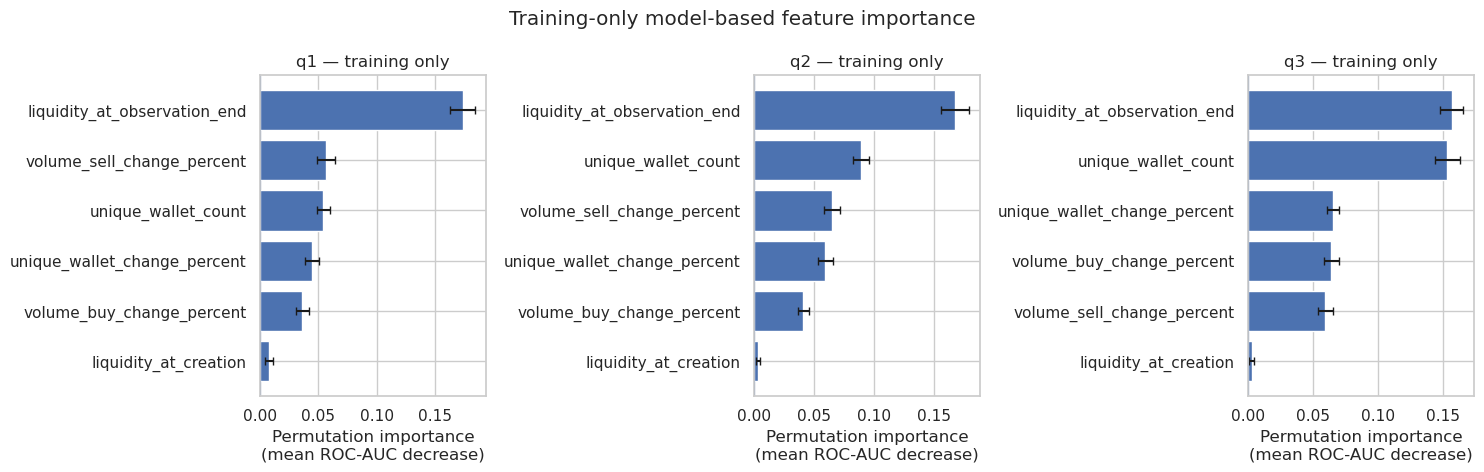

In [88]:
# ============================================================
# TRAINING-ONLY FEATURE-IMPORTANCE FIGURE
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))

for ax, q in zip(axes, EXPERIMENTS):

    plot_df = feature_importance_by_q[q].sort_values('importance_mean', ascending=True)

    ax.barh(
        plot_df['feature'],
        plot_df['importance_mean'],
        xerr=plot_df['importance_std'],
        capsize=3
    )

    ax.axvline(0, linewidth=0.8)
    ax.set_title(f'{q} — training only')
    ax.set_xlabel('Permutation importance\n(mean ROC-AUC decrease)')

fig.suptitle('Training-only model-based feature importance')

fig.tight_layout()

fig.savefig('./artifacts_stratified/figures/training_only_feature_importance.png', dpi=300, bbox_inches='tight')
fig.savefig('./artifacts_stratified/figures/training_only_feature_importance.pdf', bbox_inches='tight')

plt.show()

In [89]:
# ============================================================
# FINAL MODEL-READY ARTIFACT AUDIT
# ============================================================

audit_rows = []

for q in EXPERIMENTS:

    for variant_name, df in final_tabular[q].items():

        assert set(df['split'].unique()) == {'train', 'validation', 'test'}

        for split_name in [
            'train',
            'validation',
            'test'
        ]:

            part = (df[df['split'] == split_name].copy())

            missing_cells = int(part[NODE_MODEL_FEATURES].isna().sum().sum())

            total_predictor_cells = len(part) * len(NODE_MODEL_FEATURES)

            missing_cell_pct = 100.0 * missing_cells / total_predictor_cells if total_predictor_cells else np.nan

            audit_rows.append(
                {
                    'experiment_id': q,
                    'variant': variant_name,
                    'split': split_name,
                    'rows': len(part),

                    'rug_rate_percent': part['rug_pull_label'].mean() * 100.0,

                    'predictor_missing_cells': missing_cells,

                    'predictor_missing_cell_pct': missing_cell_pct
                }
            )


final_artifact_audit = pd.DataFrame(audit_rows)


# ------------------------------------------------------------
# Strong audits for imputed variants
# ------------------------------------------------------------

for q in EXPERIMENTS:

    assert set(final_tabular[q].keys()) == {
        'raw_nan',
        'median_indicator'
    }

    raw_ids = (
        final_tabular[q]['raw_nan'][
            [
                'lp_address',
                'token_mint',
                'experiment_id',
                'creation_time',
                'rug_pull_label',
                'split'
            ]
        ]
        .reset_index(drop=True)
    )

    for variant_name in ['median_indicator']:

        df = final_tabular[q][variant_name]

        # No missing values may remain in the final token-level predictors.
        assert not df[NODE_MODEL_FEATURES].isna().any().any()

        # No infinite values.
        assert np.isfinite(df[NODE_MODEL_FEATURES].to_numpy(dtype=float)).all()

        # Row identity and outcomes must be unchanged.
        processed_ids = (
            df[
                [
                    'lp_address',
                    'token_mint',
                    'experiment_id',
                    'creation_time',
                    'rug_pull_label',
                    'split'
                ]
            ]
            .reset_index(drop=True)
        )

        assert raw_ids.equals(processed_ids)

        # Indicators must exist and be binary.
        for indicator in MISSING_INDICATOR_COLUMNS:

            assert indicator in df.columns

            assert set(df[indicator].dropna().unique()).issubset({0, 1})


final_artifact_audit.to_csv('./artifacts_stratified/final/final_artifact_audit.csv', index=False)

display(final_artifact_audit)

,experiment_id,variant,split,rows,rug_rate_percent,predictor_missing_cells,predictor_missing_cell_pct
0,q1,raw_nan,train,1372,38.994169,3533,51.501458
1,q1,raw_nan,validation,294,39.115646,764,51.972789
2,q1,raw_nan,test,295,38.983051,811,54.983051
3,q1,median_indicator,train,1372,38.994169,0,0.000000
4,q1,median_indicator,validation,294,39.115646,0,0.000000
5,q1,median_indicator,test,295,38.983051,0,0.000000
6,q2,raw_nan,train,1253,35.913807,2484,39.648843
7,q2,raw_nan,validation,270,35.925926,535,39.629630
8,q2,raw_nan,test,275,35.636364,579,42.109091
9,q2,median_indicator,train,1253,35.913807,0,0.000000


In [90]:
# ============================================================
# FINAL GRAPH / EDGE ARTIFACT AUDIT
# ============================================================

FINAL_EDGE_AMOUNT_COLUMNS = [
    'amount_raw',
    'decimals',
    'amount_token_exact',
    'amount_token',
    'amount_resolved',
    'amount_resolution_status',
    'amount_provenance',
]

final_graph_edge_audit_rows = []

for q in EXPERIMENTS:

    final_dir = f'./artifacts_stratified/final/full/{q}'

    final_graph = pd.read_parquet(f'{final_dir}/model_graph_features_with_split.parquet')

    EDGE_AUDIT_COLUMNS = [
        'token_mint',
        'split',
        'amount_raw',
        'decimals',
        'amount_token_exact',
        'amount_token',
        'amount_resolved',
        'amount_resolution_status',
        'amount_provenance',
    ]

    final_edges = pd.read_parquet(f'{final_dir}/edges_with_split.parquet', columns=EDGE_AUDIT_COLUMNS)

    # --------------------------------------------------------
    # Required enriched amount schema must survive export.
    # --------------------------------------------------------

    missing_edge_columns = [
        col
        for col in FINAL_EDGE_AMOUNT_COLUMNS
        if col not in final_edges.columns
    ]

    assert not missing_edge_columns, f'{q}: final edge artifact is missing columns: {missing_edge_columns}'

    # --------------------------------------------------------
    # Only model-development partitions may remain.
    # --------------------------------------------------------

    assert set(
        final_edges['split']
        .dropna()
        .unique()
    ).issubset(
        {'train', 'validation', 'test'}
    )

    assert set(
        final_graph['split']
        .dropna()
        .unique()
    ).issubset(
        {'train', 'validation', 'test'}
    )

    # --------------------------------------------------------
    # One central split per token everywhere.
    # --------------------------------------------------------

    if len(final_edges):

        assert (
            final_edges
            .groupby('token_mint')['split']
            .nunique()
            .max()
            <= 1
        )

    if len(final_graph):

        assert (
            final_graph
            .groupby('token_mint')['split']
            .nunique()
            .max()
            <= 1
        )

    # Every graph-model token must have retained edges.
    assert set(
        final_graph['token_mint']
    ).issubset(
        set(final_edges['token_mint'])
    )

    # --------------------------------------------------------
    # Resolved normalized amounts must remain usable.
    # --------------------------------------------------------

    resolved_mask = (
        final_edges['amount_resolved']
        .fillna(False)
        .astype(bool)
    )

    resolved_amount = final_edges.loc[
        resolved_mask,
        'amount_token'
    ]

    assert np.isfinite(resolved_amount.to_numpy(dtype=float)).all()

    assert (resolved_amount >= 0).all()

    # --------------------------------------------------------
    # Unresolved edges must not acquire canonical values during
    # serialization/export.
    # --------------------------------------------------------

    unresolved_canonical = (
        final_edges.loc[
            ~resolved_mask,
            [
                'amount_raw',
                'decimals',
                'amount_token_exact'
            ]
        ]
        .replace('', pd.NA)
        .notna()
        .any(axis=1)
    )

    assert not unresolved_canonical.any(), f'{q}: unresolved final edge rows contain canonical amount values'

    # --------------------------------------------------------
    # Primary graph-model artifact must remain topology/timing
    # only. Diagnostic amount and quality columns must not
    # silently enter the baseline.
    # --------------------------------------------------------

    forbidden_graph_model_columns = GRAPH_DIAGNOSTIC_ONLY + GRAPH_QUALITY_COLUMNS

    leaked_graph_columns = [
        col
        for col in forbidden_graph_model_columns
        if col in final_graph.columns
    ]

    assert not leaked_graph_columns, (
        f'{q}: diagnostic/audit graph columns entered the '
        f'primary model artifact: {leaked_graph_columns}'
    )

    # Primary predictors must all be present.
    missing_graph_predictors = [
        col
        for col in GRAPH_MODEL_FEATURES
        if col not in final_graph.columns
    ]

    assert not missing_graph_predictors, (
        f'{q}: missing graph-model predictors: '
        f'{missing_graph_predictors}'
    )

    final_graph_edge_audit_rows.append(
        {
            'experiment_id': q,
            'graph_rows': len(final_graph),
            'edge_rows': len(final_edges),
            'resolved_edge_rows': int(
                resolved_mask.sum()
            ),
            'unresolved_edge_rows': int(
                (~resolved_mask).sum()
            ),
            'graph_tokens': int(
                final_graph['token_mint'].nunique()
            ),
            'edge_tokens': int(
                final_edges['token_mint'].nunique()
            ),
        }
    )


final_graph_edge_audit = pd.DataFrame(final_graph_edge_audit_rows)

display(final_graph_edge_audit)

final_graph_edge_audit.to_csv('./artifacts_stratified/final/final_graph_edge_artifact_audit.csv', index=False)

print('Final graph/edge artifact audit PASSED.')

,experiment_id,graph_rows,edge_rows,resolved_edge_rows,unresolved_edge_rows,graph_tokens,edge_tokens
0,q1,911,303696,303695,1,911,911
1,q2,955,822516,822513,3,955,955
2,q3,888,1735007,1734999,8,888,888


Final graph/edge artifact audit PASSED.


In [91]:
# ============================================================
# SOFTWARE VERSION MANIFEST
# ============================================================

software_versions = {
    'python': sys.version.split()[0],
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit_learn': sklearn.__version__,
    'joblib': joblib.__version__,
    'matplotlib': matplotlib.__version__,
    'seaborn': sns.__version__,
    'networkx': nx.__version__,
    'pyarrow': pyarrow.__version__,
}

with open('./artifacts_stratified/software_versions.json', 'w', encoding='utf-8') as f:
    json.dump(software_versions, f, indent=2)

print(json.dumps(software_versions, indent=2))

{
  "python": "3.13.9",
  "numpy": "2.3.5",
  "pandas": "2.3.3",
  "scikit_learn": "1.7.2",
  "joblib": "1.5.2",
  "matplotlib": "3.10.6",
  "seaborn": "0.13.2",
  "networkx": "3.5",
  "pyarrow": "21.0.0"
}


# Summary

The notebook now completes the full data-preparation workflow required before model
training.

Completed steps:

* cleaned and audited token-level, recovered-edge, and label tables;
* q1/q2/q3 observation-window populations;
* complete-data descriptive EDA and temporal diagnostics;
* token-level missingness, univariate association, correlation, authority, and creator
  diagnostics;
* recovered-graph availability, topology, structural, and univariate diagnostics;
* label-timing, predictor-provenance, and direct-leakage audits;
* one central label-independent chronological split at the token-mint level;
* temporal embargo checks based on `label_available_time`;
* one common split assignment reused across q1/q2/q3 and across tabular and graph branches;
* two final token-level missing-data representations for each observation window:
  `raw_nan` and `median_indicator`;
* three controlled missingness-analysis cohorts were exported using the same
  chronological split: the original cohort, a cohort excluding rows with three
  or more missing final predictors, and a complete-case cohort;
* the original and drop-three-or-more cohorts contain both `raw_nan` and
  train-only `median_indicator` representations, while the complete-case
  cohort requires no imputation;
* graph-summary, recovered-edge, and graph-matched token-level artifacts were
  generated separately for each missingness cohort;
* training-fitted median imputers saved for reproducibility;
* training-only model-based feature importance for all six token-level candidate features;
* `liquidity_at_creation` excluded from final model-ready token-level predictors after
  considering its extreme missingness and negligible training-only permutation importance;
* candidate top-k feature-set definitions generated from the fixed training-only rankings;
* final split-tagged graph-summary and recovered-edge artifacts;
* final artifact-level missingness and partition audits.
* degree-filtered, weighted Gephi visualization export with exact recovered-row
  multiplicity preservation and documented visualization settings;

The complete-data EDA does not use the model-development split for descriptive feature
analysis. Conversely, learned imputation and model-based feature importance are performed
only after the chronological split is fixed.

Validation and test rows do not influence fitted imputation parameters or the
feature-importance ranking. Embargoed tokens remain documented in the split manifest but
are excluded from final model-development datasets.

The primary final tabular artifacts are stored under:

`artifacts/final/full/q1--q3/`

Missingness-ablation artifacts are stored under:

`artifacts/final/missingness_experiments/`

with separate directories for:

`original/`

`drop_3_or_more_missing/`

`complete_case/`

with one file for each missing-data representation. The same directories contain the
split-tagged graph-summary and recovered-edge artifacts.

The central source of truth for partition assignment is:

`artifacts/splits/chronological_split_manifest.parquet`

Training-only feature-importance results are stored under:

`artifacts/feature_importance/`

Transfer-amount status:

* Edge-level SPL transfer amounts have been re-resolved with explicit
  `amount_raw`, `decimals`, canonical `amount_token`, resolution status, and provenance.
  Exact raw/decimal consistency is verified before artifact generation, and unresolved
  transaction-unavailable rows remain explicitly marked rather than guessed.

* Decimal normalization resolves the historical raw-base-unit inconsistency, but absolute
  token quantities are not treated as cross-token economic values. They are retained in
  the final edge artifacts and graph-level descriptive summaries but excluded from the
  primary topology/timing graph-model predictor set.

* No USD-valued transfer feature is constructed because a cutoff-safe historical
  edge-time price series is not currently available. Label-side price-drop variables
  are outcome evidence and are never reused as predictors.

* A future amount-aware ablation may evaluate scale-invariant amount features such as
  sender concentration and, if suitable historical data are collected, cutoff-safe
  supply-normalized or historical-price-normalized transfer values.